# 9강. 순서가 있는 데이터와 어텐션: RNN부터 Transformer, BERT, CLIP까지

**대상**: 파이썬과 1~8강 내용을 아는 입문자 · **분량**: 7부 · **환경**: Google Colab

**저자**: 이창민 · **라이선스**: 본문 CC BY 4.0, 코드 MIT (제3자 자료 제외, NOTICE 참고)

**예상 학습 시간**: 읽고 실습하는 데 8~10시간(어림값). 코드 전체 실행은 Apple GPU에서 약 17분(5부 BERT는 줄인 설정)이었고, Colab에서는 재 보지 못했습니다.

**막혔을 때**: 에러 메시지의 마지막 줄로 검색하고, [PyTorch 포럼](https://discuss.pytorch.org/)과 [Hugging Face 문서](https://huggingface.co/docs/transformers/index)를 찾아보세요. 패키지 설치 직후의 import 오류는 런타임을 다시 시작하면 풀리는 경우가 많습니다.

이 강의 줄기는 "단어나 시간처럼 **순서가 있는 데이터를 어떻게 숫자로 바꾸고, 멀리 떨어진 정보를 어떻게 전달할까**"입니다. 시계열 신호처리에서 출발한 RNN의 한계를 어텐션이 어떻게 풀었고, 그 아이디어가 이미지(ViT), 언어(BERT, GPT), 이미지와 언어의 결합(CLIP)으로 어떻게 번졌는지 순서대로 따라갑니다.

이 강을 마치면 다음을 할 수 있습니다.

- 원핫 인코딩과 임베딩의 차이를 설명하고 `nn.Embedding`을 쓴다.
- RNN, LSTM, GRU를 직접 구현하고 PyTorch 내장 모듈과 결과가 같은지 검증한다.
- 기울기 소실과 폭주를 실험으로 보이고 대응법을 말한다.
- Scaled Dot-Product Attention, Multi-Head Attention, 위치 인코딩, 마스킹을 수식과 코드로 설명한다.
- Transformer로 독일어-영어 번역기를 학습하고 BLEU로 평가한다.
- ViT의 추론 과정을 패치 단위까지 뜯어 본다.
- BERT로 한국어 감성분석기를 학습하고 F1으로 평가한다.
- CLIP과 문장 임베딩으로 zero-shot 분류와 의미 검색을 한다.
- 학습 방식(지도, 준지도, 약지도, 자기지도 등)과 zero/one/few-shot을 구분한다.

| 부 | 주제 | 다루는 내용 |
|---|---|---|
| 1부 | 원핫과 RNN | 원핫, 임베딩, RNN 직접 구현, 이미지를 순서로 읽기, BPTT, 기울기 소실과 폭주 |
| 2부 | LSTM과 GRU | 게이트, 직접 구현과 내장 모듈 검증, 세 모델 비교, RNN 계열의 한계 |
| 3부 | 어텐션 | Seq2Seq 어텐션, Scaled Dot-Product, Multi-Head, 마스킹, FFN, 위치 인코딩 |
| 4부 | Transformer와 ViT | 번역 실습, 추론, BLEU, Label smoothing, ViT 해부 |
| 5부 | BERT와 GPT | Hugging Face, 토큰/세그먼트/마스크, NSMC 감성분석, F1 |
| 6부 | CLIP과 임베딩 검색 | 이미지-텍스트 유사도, zero-shot 분류, 문장 임베딩 의미 검색 |
| 7부 | 학습 방식과 zero/few-shot | 지도, 준지도, 약지도, 자기지도, pseudo label, 프로토타입 분류 |

> **사용법**: 위에서 아래로 순서대로 실행하세요. 메뉴의 `런타임 → 런타임 유형 변경`에서 **T4 GPU**를 고르면 학습이 빨라집니다. `실습` 셀은 직접 채우고, 막히면 아래의 `정답`을 펼쳐 보세요. `답`이 붙은 질문은 먼저 생각해 본 뒤 펼치세요.
>
> **오래 걸리는 곳**: 5부 BERT는 전체 설정(15만 문장, 4 epoch)이 오래 걸립니다. 저장된 출력의 짧은 실행 시간으로 비례 계산하면 Apple GPU 기준 두 시간이 넘습니다(추정). 처음에는 5.4절의 `BERT_TRAIN_SAMPLES`를 8000 정도로 줄여 흐름부터 보세요.
>
> **필수와 선택**: 1~7부가 본 흐름입니다. 6.9절의 OpenAI, Pinecone 실습과 맨 뒤의 부록은 선택입니다. 시간이 부족하면 2.5절의 기억 과제는 저장된 결과만, 5부의 전체 학습은 5.6절의 참고값만 읽어도 됩니다. 대규모 언어 모델(LLM)은 11강에서 다룹니다.

In [1]:
# 이번 강의 전체에서 쓰는 라이브러리
%pip install -q timm datasets transformers sentence-transformers scikit-image pooch scikit-learn nltk

import math
import os
import random
import re
import time
import urllib.request
import warnings
from collections import Counter
from collections.abc import Callable
from pathlib import Path

warnings.filterwarnings("ignore", category=DeprecationWarning)   # 라이브러리 내부 경고가 출력을 가리지 않게 한다
warnings.filterwarnings("ignore", message="IProgress")

# 다운로드 진행 막대가 출력을 덮지 않게 라이브러리를 불러오기 전에 끈다
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
os.environ["TOKENIZERS_PARALLELISM"] = "false"

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import PIL.Image
import skimage.data
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import DataLoader, Sampler, TensorDataset

device = torch.device("cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu")
print("PyTorch:", torch.__version__, "/ device:", device)


def set_seed(seed: int = 1234) -> None:
    """파이썬, NumPy, PyTorch의 난수를 한 번에 고정합니다."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed()

Note: you may need to restart the kernel to use updated packages.


PyTorch: 2.15.0 / device: mps


---
# 1부. 원핫 인코딩과 RNN

## 1.1 범주를 숫자로: 원핫 인코딩

신경망은 숫자만 받습니다. 도시 이름 같은 범주에 숫자를 붙이면 어떨까요?

휴스턴=1, 로마=2, 마드리드=3, 런던=4

**Q. 이렇게 하면 무엇이 문제일까요? 런던과 휴스턴은 먼 도시인가요?**

<details><summary>답</summary>

번호의 크기와 간격에 없는 의미가 생깁니다. 숫자로만 보면 런던(4)과 휴스턴(1)의 거리는 3이고, 로마(2)와 휴스턴(1)의 거리는 1입니다. 번호는 **등장 순서에 따라 붙였을 뿐**인데 모델은 이 크기 차이를 정보로 받아들입니다.

</details>

**원핫 인코딩**은 범주마다 축을 하나씩 주고, 자기 축만 1로 둡니다. 표로 쓰면 이렇습니다.

| City | Houston | Rome | Madrid | London |
|---|---|---|---|---|
| Houston | 1 | 0 | 0 | 0 |
| Rome | 0 | 1 | 0 | 0 |
| Madrid | 0 | 0 | 1 | 0 |
| London | 0 | 0 | 0 | 1 |

그림 출처: [원핫 인코딩](https://miro.medium.com/v2/resize:fit:1400/1*x_DYdNVsPiRoDpSoRGJo3Q.png)

이제 어느 두 도시를 골라도 거리가 같습니다. 코드로 확인합니다.

In [2]:
# 번호 그대로일 때의 거리: 번호를 붙인 순서가 거리를 정해 버린다
city_numbers = {"Houston": 1, "Rome": 2, "Madrid": 3, "London": 4}
print("번호 거리 London-Houston:", abs(city_numbers["London"] - city_numbers["Houston"]))
print("번호 거리 Rome-Houston:  ", abs(city_numbers["Rome"] - city_numbers["Houston"]))

# 원핫으로 바꾸면 모든 쌍의 거리가 sqrt(2)로 같아진다
city_onehot = F.one_hot(torch.arange(4), num_classes=4).float()
print(city_onehot)
print("쌍별 거리:\n", torch.cdist(city_onehot, city_onehot).round(decimals=3))

# F.one_hot은 정수 텐서를 받는다. 값 0,1,2,0,1 이므로 클래스는 3개로 추정된다
F.one_hot(torch.arange(0, 5) % 3)

번호 거리 London-Houston: 3
번호 거리 Rome-Houston:   1
tensor([[1., 0., 0., 0.],
        [0., 1., 0., 0.],
        [0., 0., 1., 0.],
        [0., 0., 0., 1.]])
쌍별 거리:
 tensor([[0.0000, 1.4140, 1.4140, 1.4140],
        [1.4140, 0.0000, 1.4140, 1.4140],
        [1.4140, 1.4140, 0.0000, 1.4140],
        [1.4140, 1.4140, 1.4140, 0.0000]])


tensor([[1, 0, 0],
        [0, 1, 0],
        [0, 0, 1],
        [1, 0, 0],
        [0, 1, 0]])

## 1.2 원핫의 한계와 임베딩

원핫에는 두 가지 약점이 있습니다.

1. **차원이 어휘 수만큼 커집니다.** 단어가 3만 개면 벡터 하나가 3만 차원이고, 대부분 0입니다.
2. **모든 단어가 똑같이 멉니다.** "cat"과 "dog"의 거리나 "cat"과 "car"의 거리가 같습니다. 비슷함을 표현할 방법이 없습니다.

**임베딩**은 단어마다 짧은 실수 벡터를 하나씩 주고, 그 값을 학습합니다. `nn.Embedding(V, D)`는 V×D 크기의 표이고, 정수 번호로 그 표의 한 행을 꺼냅니다. 수학적으로는 **원핫 벡터에 가중치 행렬을 곱한 것과 같습니다.** 곱셈을 실제로 하지 않고 행만 꺼내니 훨씬 빠를 뿐입니다. 4부의 Transformer와 5부의 BERT 모두 입력 맨 앞에 이 층이 있습니다.

In [3]:
vocab_size, embed_dim = 5, 3
embedding = nn.Embedding(vocab_size, embed_dim)
ids = torch.tensor([0, 3, 3, 1])

by_lookup = embedding(ids)
# 원핫 행렬과 임베딩 가중치의 행렬곱이 표 조회와 같은지 확인한다
by_matmul = F.one_hot(ids, vocab_size).float() @ embedding.weight

print("가중치 모양:", embedding.weight.shape)
print("출력 모양:", by_lookup.shape, "(단어 수, 임베딩 차원)")
print("두 계산이 같은가:", torch.allclose(by_lookup, by_matmul))
assert torch.allclose(by_lookup, by_matmul)

가중치 모양: torch.Size([5, 3])
출력 모양: torch.Size([4, 3]) (단어 수, 임베딩 차원)
두 계산이 같은가: True


## 1.3 RNN의 구조

일반 신경망은 입력 사이의 순서를 모릅니다. **RNN(Recurrent Neural Network)** 은 앞 단계의 출력을 **은닉 상태** $h$로 기억해 다음 단계에 함께 넣습니다. 같은 가중치를 시간마다 되풀이해 씁니다.

$$h_t = \tanh\big(h_{t-1} W_y + x_t W_x + b\big)$$

입력과 출력을 어떻게 묶느냐에 따라 쓰임이 나뉩니다.

| 형태 | 입력 → 출력 | 예 |
|---|---|---|
| one to many | 하나 → 여럿 | 사진 설명 붙이기: 사진 → 단어들 |
| many to one | 여럿 → 하나 | 감성분석: 단어들 → 감성 점수 |
| many to many | 여럿 → 여럿 | 번역: 단어들 → 단어들 |

그림 출처: [RNN 입력/출력 형태](https://img1.daumcdn.net/thumb/R1280x0/?scode=mtistory2&fname=https%3A%2F%2Fblog.kakaocdn.net%2Fdn%2FcffBNq%2FbtrrXqRKRQM%2FZDsokUIc5RRUdFhAJT40jK%2Fimg.png) · [펼친 RNN과 배치 입력](https://miro.medium.com/v2/resize:fit:1400/format:webp/1*xCj9h3f2kekfqN_dMCpcag.png)

## 1.4 RNN을 직접 만들기

이 절부터 1.6절까지의 예제는 [dair-ai의 RNN 노트북](https://github.com/dair-ai/notebooks/blob/master/_notebooks/2020-03-18-RNN_PT.ipynb)(Apache-2.0)을 고쳐 쓴 것입니다.

시간을 두 단계만 펼쳐서 수식을 그대로 코드로 옮깁니다. 배치 크기는 4이고, 시각 0과 1의 입력이 각각 `X0_batch`, `X1_batch`입니다. 첫 단계에는 이전 상태가 없으니 $h_{-1}=0$으로 보고 그 항을 뺐습니다.

In [4]:
class BasicRNN(nn.Module):
    """두 시각만 펼친 RNN입니다. 수식과 코드를 맞춰 보기 위한 것입니다."""

    def __init__(self, n_inputs: int, n_neurons: int) -> None:
        super().__init__()
        # nn.Parameter로 감싸야 model.parameters()에 잡혀 학습된다
        self.Wx = nn.Parameter(torch.randn(n_inputs, n_neurons))    # n_inputs X n_neurons
        self.Wy = nn.Parameter(torch.randn(n_neurons, n_neurons))   # n_neurons X n_neurons
        self.b = nn.Parameter(torch.zeros(1, n_neurons))            # 1 X n_neurons

    def forward(self, X0: torch.Tensor, X1: torch.Tensor) -> tuple[torch.Tensor, torch.Tensor]:
        Y0 = torch.tanh(torch.mm(X0, self.Wx) + self.b)                             # batch X n_neurons
        # 시각 0의 출력 Y0가 시각 1의 계산에 들어간다. 이것이 RNN의 기억이다
        Y1 = torch.tanh(torch.mm(Y0, self.Wy) + torch.mm(X1, self.Wx) + self.b)     # batch X n_neurons
        return Y0, Y1

In [5]:
# 입력 특징 4개, 은닉 상태 1개 (출력이 숫자 하나씩)
N_INPUT = 4
N_NEURONS = 1

X0_batch = torch.tensor([[0, 1, 2, 0],
                         [3, 4, 5, 0],
                         [6, 7, 8, 0],
                         [9, 0, 1, 0]], dtype=torch.float)  # t=0 => 4 X 4

X1_batch = torch.tensor([[9, 8, 7, 0],
                         [0, 0, 0, 0],
                         [6, 5, 4, 0],
                         [3, 2, 1, 0]], dtype=torch.float)  # t=1 => 4 X 4

model = BasicRNN(N_INPUT, N_NEURONS)
Y0_val, Y1_val = model(X0_batch, X1_batch)
print(Y0_val.shape, Y1_val.shape)
print(Y0_val.detach().T)
print(Y1_val.detach().T)

torch.Size([4, 1]) torch.Size([4, 1])
tensor([[0.7442, 0.9998, 1.0000, 1.0000]])
tensor([[ 1.0000, -0.8951,  0.9999,  0.8605]])


In [6]:
# 입력 특징 3개, 은닉 상태 5개로 바꿔도 같은 클래스를 그대로 쓴다
N_INPUT = 3     # 입력 특징 수
N_NEURONS = 5   # 층의 유닛 수

X0_batch = torch.tensor([[0, 1, 2], [3, 4, 5],
                         [6, 7, 8], [9, 0, 1]], dtype=torch.float)  # t=0 => 4 X 3

X1_batch = torch.tensor([[9, 8, 7], [0, 0, 0],
                         [6, 5, 4], [3, 2, 1]], dtype=torch.float)  # t=1 => 4 X 3

model = BasicRNN(N_INPUT, N_NEURONS)
Y0_val, Y1_val = model(X0_batch, X1_batch)
print(Y0_val.detach())
print(Y1_val.detach())
print("시각 1에서 입력이 전부 0인 둘째 샘플의 출력:", Y1_val[1].detach())

tensor([[ 0.9354, -0.8141,  0.6633, -0.8394, -0.9977],
        [ 0.9990, -0.9088,  0.1891,  0.0814, -1.0000],
        [ 1.0000, -0.9564, -0.3935,  0.8815, -1.0000],
        [-0.7743,  1.0000, -1.0000,  0.9998,  0.3928]])
tensor([[ 0.9960,  0.2383, -0.8742,  1.0000, -1.0000],
        [-0.9426, -0.7764,  0.4814, -0.9185, -0.9881],
        [ 0.4444, -0.9345, -0.9831, -0.0401, -1.0000],
        [ 0.9322,  0.2545, -0.9940,  0.2888,  0.9496]])
시각 1에서 입력이 전부 0인 둘째 샘플의 출력: tensor([-0.9426, -0.7764,  0.4814, -0.9185, -0.9881])


**Q. 시각 1에서 둘째 샘플의 입력은 `[0, 0, 0]`입니다. 그런데 왜 출력이 0이 아닐까요?**

<details><summary>답</summary>

시각 0의 출력 $Y_0$가 $W_y$를 거쳐 들어오기 때문입니다. 지금 입력이 없어도 앞에서 본 것을 기억합니다. RNN의 핵심이 이것입니다.

</details>

## 1.5 `nn.RNNCell`로 줄이기

`nn.RNNCell`은 위 수식의 한 시각을 계산합니다. 시각 수만큼 반복문을 돌리면 됩니다.

In [7]:
rnn = nn.RNNCell(3, 5)  # n_input X n_neurons

X_batch = torch.tensor([[[0, 1, 2], [3, 4, 5],
                         [6, 7, 8], [9, 0, 1]],
                        [[9, 8, 7], [0, 0, 0],
                         [6, 5, 4], [3, 2, 1]]], dtype=torch.float)  # (시각 2, 배치 4, 특징 3)

hx = torch.zeros(4, 5)  # 배치 X n_neurons. 시작 상태는 보통 0으로 둔다
output = []

for t in range(2):      # 시각마다 같은 셀을 되풀이한다
    hx = rnn(X_batch[t], hx)
    output.append(hx)

print(len(output), output[0].shape)
print(output[1].detach())

2 torch.Size([4, 5])
tensor([[ 1.0000, -0.1580, -0.9769,  0.1917, -0.9998],
        [ 0.6200, -0.4457,  0.7058,  0.0714,  0.1375],
        [ 0.9994, -0.5772, -0.6188,  0.5618, -0.9898],
        [ 0.9748, -0.1543, -0.3032,  0.6506, -0.0027]])


이 반복문을 모듈로 묶습니다. 처음 구현할 때 하기 쉬운 실수 세 가지를 피합니다.

1. 시각 수를 `range(2)`처럼 고정하면 다른 길이를 받지 못합니다. `X.size(0)`을 씁니다.
2. 은닉 상태를 `self.hx`에 저장하면 **호출할 때마다 앞 호출의 상태를 이어받습니다.** 같은 입력에 다른 답이 나오고, 학습하면 이미 해제된 계산 그래프로 역전파하려다 에러가 납니다. 호출마다 새로 만듭니다.
3. 그러면 배치 크기를 생성자에서 고정할 필요도 없습니다.

In [8]:
class CleanBasicRNN(nn.Module):
    def __init__(self, n_inputs: int, n_neurons: int) -> None:
        super().__init__()
        self.rnn = nn.RNNCell(n_inputs, n_neurons)
        self.n_neurons = n_neurons

    def forward(self, X: torch.Tensor) -> tuple[list[torch.Tensor], torch.Tensor]:
        # X: (시각, 배치, 특징). 호출마다 상태를 새로 시작해야 같은 입력에 같은 답이 나온다
        hx = torch.zeros(X.size(1), self.n_neurons, device=X.device)
        output = []
        for t in range(X.size(0)):
            hx = self.rnn(X[t], hx)
            output.append(hx)
        return output, hx


N_INPUT = 3
N_NEURONS = 5
model = CleanBasicRNN(N_INPUT, N_NEURONS)
output_val, states_val = model(X_batch)
print("시각별 출력 개수:", len(output_val))
print("마지막 상태:", states_val.shape)

# 같은 입력이면 다시 불러도 같은 답이 나와야 한다
assert torch.equal(model(X_batch)[1], states_val)
# 길이가 달라도 동작한다
print("길이 7인 입력:", len(model(torch.zeros(7, 2, 3))[0]), "개 출력")

시각별 출력 개수: 2
마지막 상태: torch.Size([4, 5])
길이 7인 입력: 7 개 출력


## 1.6 이미지를 순서대로 보면 어떨까?

28×28 MNIST 이미지를 **위에서 아래로 한 줄씩 읽는 시퀀스**로 볼 수 있습니다. 한 줄(픽셀 28개)이 한 시각의 입력이고, 시각은 28개입니다. 이 형태는 many to one입니다. 마지막 은닉 상태로 숫자를 맞힙니다.

내장 `nn.RNN`의 입력 축 순서는 인자로 정합니다.

- `batch_first=False`(기본값): 입력은 (길이, 배치, 특징), 출력은 (길이, 배치, 은닉)
- `batch_first=True`: 입력은 (배치, 길이, 특징), 출력은 (배치, 길이, 은닉)

그림 출처: [MNIST를 줄 단위 시퀀스로 보기](https://miro.medium.com/v2/resize:fit:1400/format:webp/1*wFYZpxTTiXVqncOLQd_CIQ.jpeg)

In [9]:
BATCH_SIZE = 64

# 이미지를 [0, 1] 텐서로 바꾼다
transform = transforms.Compose([transforms.ToTensor()])

trainset = torchvision.datasets.MNIST(root="./data", train=True, download=True, transform=transform)
trainloader = DataLoader(trainset, batch_size=BATCH_SIZE, shuffle=True)

testset = torchvision.datasets.MNIST(root="./data", train=False, download=True, transform=transform)
testloader = DataLoader(testset, batch_size=BATCH_SIZE, shuffle=False)
print(len(trainset), len(testset))

60000 10000


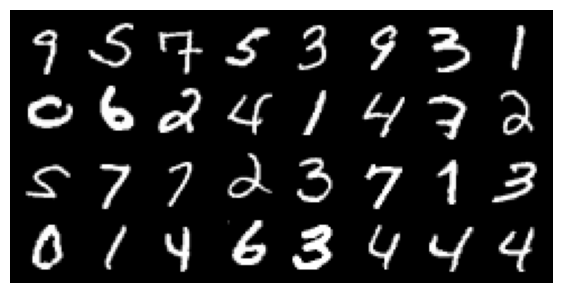

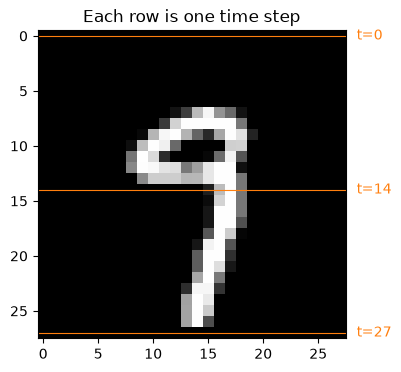

In [10]:
def imshow(img: torch.Tensor) -> None:
    """make_grid 결과(채널, 높이, 너비)를 matplotlib 순서로 바꿔 그립니다."""
    npimg = img.numpy()
    plt.imshow(np.transpose(npimg, (1, 2, 0)))
    plt.axis("off")


images, labels = next(iter(trainloader))
plt.figure(figsize=(7, 7))
imshow(torchvision.utils.make_grid(images[:32]))
plt.show()

# 한 장을 시퀀스로 읽는 모습: 가로 한 줄이 한 시각의 입력이다
fig, ax = plt.subplots(figsize=(4, 4))
ax.imshow(images[0].squeeze(), cmap="gray")
for t in [0, 14, 27]:
    ax.axhline(t, color="tab:orange", lw=0.8)
    ax.text(28.5, t, f"t={t}", va="center", color="tab:orange")
ax.set_title("Each row is one time step")
ax.set_xlim(-0.5, 27.5)
plt.show()

In [11]:
# 파라미터
N_STEPS = 28
N_INPUTS = 28
N_NEURONS = 150
N_OUTPUTS = 10
N_EPOCHS = 10


class ImageRNN(nn.Module):
    def __init__(self, n_inputs: int, n_neurons: int, n_outputs: int) -> None:
        super().__init__()
        self.n_neurons = n_neurons
        self.n_outputs = n_outputs
        self.basic_rnn = nn.RNN(n_inputs, n_neurons)
        self.fc = nn.Linear(n_neurons, n_outputs)

    def init_hidden(self, batch_size: int, device: torch.device) -> torch.Tensor:
        # (num_layers, batch_size, n_neurons). 입력과 같은 장치에 만들어야 GPU에서 에러가 나지 않는다
        return torch.zeros(1, batch_size, self.n_neurons, device=device)

    def forward(self, X: torch.Tensor) -> torch.Tensor:
        # 기본값이 batch_first=False이므로 (시각, 배치, 특징)으로 바꾼다
        X = X.permute(1, 0, 2)
        hidden = self.init_hidden(X.size(1), X.device)
        _, hidden = self.basic_rnn(X, hidden)
        # 마지막 은닉 상태만 분류기에 넣는다 (many to one)
        out = self.fc(hidden)
        return out.view(-1, self.n_outputs)  # batch X n_outputs

In [12]:
images, labels = next(iter(trainloader))
print(images.shape, labels.shape)
model = ImageRNN(N_INPUTS, N_NEURONS, N_OUTPUTS)

# (배치, 채널 1, 28, 28) → (배치, 시각 28, 특징 28)
images2 = images.view(-1, N_STEPS, N_INPUTS)
print(images2.shape)
logits = model(images2)
print(logits.shape)
print("학습 전 첫 이미지의 로짓:", logits[0].detach().numpy().round(2))

torch.Size([64, 1, 28, 28]) torch.Size([64])
torch.Size([64, 28, 28])


torch.Size([64, 10])
학습 전 첫 이미지의 로짓: [ 0.01 -0.09 -0.08 -0.09  0.02 -0.02  0.02 -0.04 -0.06 -0.02]


In [13]:
model = ImageRNN(N_INPUTS, N_NEURONS, N_OUTPUTS).to(device)  # 모델을 옮기지 않으면 device를 만들어도 CPU에서 돈다
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)


def count_correct(logit: torch.Tensor, target: torch.Tensor) -> int:
    """맞힌 개수를 셉니다. 비율은 합산이 끝난 뒤 전체 개수로 나눠야 합니다."""
    return (logit.argmax(dim=1) == target).sum().item()

In [14]:
for epoch in range(N_EPOCHS):
    running_loss, n_correct, n_seen = 0.0, 0, 0
    model.train()

    for inputs, labels in trainloader:
        inputs, labels = inputs.view(-1, N_STEPS, N_INPUTS).to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(inputs)     # 순전파
        loss = criterion(outputs, labels)
        loss.backward()             # 역전파
        optimizer.step()            # 갱신

        # 마지막 배치는 크기가 작으므로 샘플 수로 가중해 평균을 낸다
        running_loss += loss.item() * labels.size(0)
        n_correct += count_correct(outputs, labels)
        n_seen += labels.size(0)

    print(f"Epoch: {epoch} | Loss: {running_loss / n_seen:.4f} | Train Accuracy: {100 * n_correct / n_seen:.2f}")

Epoch: 0 | Loss: 0.6687 | Train Accuracy: 78.45


Epoch: 1 | Loss: 0.2810 | Train Accuracy: 92.03


Epoch: 2 | Loss: 0.1990 | Train Accuracy: 94.39


Epoch: 3 | Loss: 0.1735 | Train Accuracy: 95.01


Epoch: 4 | Loss: 0.1538 | Train Accuracy: 95.61


Epoch: 5 | Loss: 0.1400 | Train Accuracy: 95.97


Epoch: 6 | Loss: 0.1316 | Train Accuracy: 96.31


Epoch: 7 | Loss: 0.1279 | Train Accuracy: 96.39


Epoch: 8 | Loss: 0.1170 | Train Accuracy: 96.67


Epoch: 9 | Loss: 0.1084 | Train Accuracy: 96.94


In [15]:
def evaluate_accuracy(model: nn.Module, loader: DataLoader) -> float:
    """시퀀스 모델의 정확도(%)를 계산합니다."""
    model.eval()     # dropout 등을 평가 모드로 바꾼다
    n_correct, n_seen = 0, 0
    with torch.no_grad():   # 평가에는 기울기가 필요 없다
        for inputs, labels in loader:
            inputs, labels = inputs.view(-1, N_STEPS, N_INPUTS).to(device), labels.to(device)
            n_correct += count_correct(model(inputs), labels)
            n_seen += labels.size(0)
    return 100 * n_correct / n_seen


test_accuracy = evaluate_accuracy(model, testloader)
print(f"Test Accuracy: {test_accuracy:.2f}")

# 흔한 실수를 재현한다: 배치별 '맞힌 수 / BATCH_SIZE'를 더해 마지막 인덱스 i로 나눈다
old_sum = 0.0
with torch.no_grad():
    for i, (inputs, labels) in enumerate(testloader):
        inputs, labels = inputs.view(-1, N_STEPS, N_INPUTS).to(device), labels.to(device)
        old_sum += 100.0 * count_correct(model(inputs), labels) / BATCH_SIZE
print(f"잘못된 계산: {old_sum / i:.2f} (배치 {i + 1}개인데 {i}로 나눔)")

Test Accuracy: 96.72


잘못된 계산: 96.88 (배치 157개인데 156로 나눔)


**정확도 계산에서 흔한 실수**: `enumerate`의 마지막 인덱스 `i`로 나누면 배치가 157개일 때 `i`는 156이라 **분모가 하나 작습니다.** 크기가 16인 마지막 배치까지 `BATCH_SIZE`(64)로 나누면 오차가 하나 더 생깁니다. 두 오차가 일부 상쇄되어 위처럼 차이는 작지만, 모델이 좋으면 100%를 넘는 값도 나올 수 있는 계산입니다. 비율은 **맞힌 개수의 합 / 샘플 수의 합**으로 구하세요. 평가할 때는 `model.eval()`과 `torch.no_grad()`도 잊지 마세요.

## 1.7 `nn.RNN` 활용: 층 쌓기와 `batch_first`

`nn.RNN`은 `num_layers`로 RNN을 쌓고, `batch_first=True`면 (배치, 길이, 특징) 순서로 받습니다. `dropout`은 층 사이에만 들어가므로 **층이 2개 이상일 때만** 의미가 있습니다.

아래 함수 `fit`은 이후 비교 실험에 계속 씁니다. 이런 분류 모델의 구성은 다음 코드를 참고했습니다: [rnn](https://gist.github.com/bkaankuguoglu/afabeb96d32b9485ba52dca83274c573) · [lstm](https://gist.github.com/bkaankuguoglu/c668c4c1490baa3ba8db006203d2f65c) · [gru](https://gist.github.com/bkaankuguoglu/762bce55868db4424bfe98b988316bcf).

In [16]:
class SequenceClassifier(nn.Module):
    """내장 순환 모듈의 마지막 시각 출력으로 분류합니다. RNN, LSTM, GRU에 함께 씁니다."""

    def __init__(self, recurrent_type: type[nn.Module], input_dim: int, hidden_dim: int, n_layers: int,
                 n_classes: int, dropout: float = 0.0) -> None:
        super().__init__()
        self.recurrent = recurrent_type(input_dim, hidden_dim, num_layers=n_layers, batch_first=True, dropout=dropout)
        self.classifier = nn.Linear(hidden_dim, n_classes)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # 시작 상태를 주지 않으면 내장 모듈이 입력과 같은 장치에 0으로 만든다
        outputs, _ = self.recurrent(x)
        return self.classifier(outputs[:, -1])  # outputs: (배치, 길이, 은닉)


def fit(model: nn.Module, loader: DataLoader, epochs: int, lr: float = 0.001) -> None:
    """MNIST 시퀀스 분류 모델을 학습합니다."""
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)
    for _ in range(epochs):
        model.train()
        for inputs, labels in loader:
            inputs, labels = inputs.view(-1, N_STEPS, N_INPUTS).to(device), labels.to(device)
            optimizer.zero_grad()
            criterion(model(inputs), labels).backward()
            optimizer.step()


set_seed()
rnn_model = SequenceClassifier(nn.RNN, N_INPUTS, N_NEURONS, n_layers=2, n_classes=N_OUTPUTS, dropout=0.2).to(device)
fit(rnn_model, trainloader, epochs=3)
print(f"2층 nn.RNN, 3 epoch 테스트 정확도: {evaluate_accuracy(rnn_model, testloader):.2f}")

2층 nn.RNN, 3 epoch 테스트 정확도: 95.10


## 1.8 역전파: 기울기 소실? 폭주?

RNN은 시간을 펼쳐 놓고 역전파합니다. 이것을 **BPTT(Backpropagation Through Time)** 라고 합니다. 그림으로 보던 내용을 식으로 쓰면 이렇습니다. 시각 101의 오차 $E_{101}$을 시각 1의 상태로 미분하면 연쇄 법칙에 따라 **곱이 시간 수만큼 이어집니다.**

$$\frac{\partial E_{101}}{\partial h_1} = \frac{\partial E_{101}}{\partial h_{101}} \cdot \frac{\partial h_{101}}{\partial h_{100}} \cdot \frac{\partial h_{100}}{\partial h_{99}} \cdots \frac{\partial h_{3}}{\partial h_{2}} \cdot \frac{\partial h_{2}}{\partial h_{1}}$$

- 곱하는 값이 모두 **1보다 작으면** 곱은 0으로 사라집니다. 먼 과거는 학습에 영향을 주지 못합니다. 이것이 **기울기 소실(gradient vanishing)** 입니다.
- 모두 **1보다 크면** 곱이 터집니다. 가중치 갱신식 $W \leftarrow W - \eta\,\partial E/\partial W$에서 $W$가 한 번에 크게 움직여 학습이 불안정해집니다. 이것이 **기울기 폭주(gradient exploding)** 입니다.

참고: [기울기 소실과 폭주 설명 글](https://huidea.tistory.com/237) · 그림 출처: [BPTT](https://user-images.githubusercontent.com/42150335/134299504-6704fb9d-2578-4c38-a5e1-0de5438bf546.png) · [RNN 셀의 역전파 계산 그래프](https://user-images.githubusercontent.com/42150335/134299677-12bf24c3-0833-4c88-85e1-5b8d4da2db66.png) · [기울기 소실](https://img1.daumcdn.net/thumb/R1280x0/?scode=mtistory2&fname=https%3A%2F%2Fblog.kakaocdn.net%2Fdn%2FdmUvCi%2FbtrrU6Ug9i4%2FWyPdgRYk56EkKLLGji3eC1%2Fimg.png) · [기울기 폭주](https://img1.daumcdn.net/thumb/R1280x0/?scode=mtistory2&fname=https%3A%2F%2Fblog.kakaocdn.net%2Fdn%2FHVJTZ%2FbtrrUoVo5m5%2Fo4fbrAxqd0ncupCCQo9Kp0%2Fimg.png)

먼저 숫자로, 그다음 실제 RNN으로 확인합니다. 아래 실험은 마지막 출력을 각 시각의 **입력**으로 미분합니다. 값이 클수록 그 시각의 입력이 마지막 출력에 영향을 준다는 뜻입니다. $W_y$(내장 모듈의 `weight_hh`)의 크기를 직교 행렬 × `gain`으로 조절합니다.

0.9를 100번 곱하면: 2.6561398887587544e-05
1.1을 100번 곱하면: 13780.61233982238
gain=0.7: 첫 시각 기울기 7.00e-16, 마지막 시각 기울기 1.53e+00
gain=1.0: 첫 시각 기울기 1.08e+00, 마지막 시각 기울기 1.03e+00
gain=1.1: 첫 시각 기울기 1.64e+04, 마지막 시각 기울기 2.49e+00


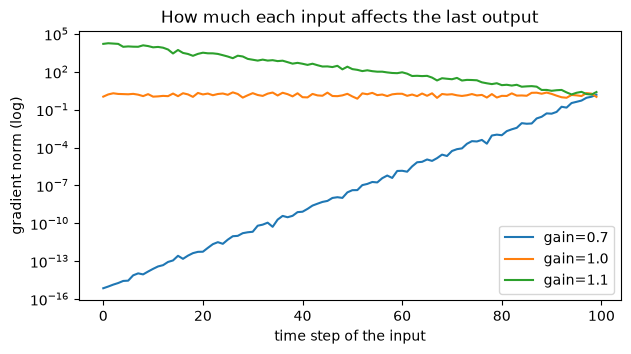

In [17]:
print("0.9를 100번 곱하면:", 0.9 ** 100)
print("1.1을 100번 곱하면:", 1.1 ** 100)

SEQ_LEN = 100
INPUT_SIZE, HIDDEN_SIZE = 8, 64


def input_grad_by_time(recurrent: nn.Module, seq_len: int, input_scale: float = 0.01) -> np.ndarray:
    """마지막 출력을 각 시각의 입력으로 미분한 크기를 시각별로 돌려줍니다."""
    x = (input_scale * torch.randn(1, seq_len, INPUT_SIZE)).requires_grad_()
    out, _ = recurrent(x)
    out[:, -1].sum().backward()
    return x.grad.norm(dim=(0, 2)).numpy()


set_seed()
plt.figure(figsize=(7, 3.5))
for gain in [0.7, 1.0, 1.1]:
    rnn_probe = nn.RNN(INPUT_SIZE, HIDDEN_SIZE, batch_first=True)
    nn.init.orthogonal_(rnn_probe.weight_hh_l0, gain=gain)
    # 편향을 0으로, 입력을 아주 작게 두어 tanh가 포화되지 않게 한다. 포화되면 폭주가 가려진다
    nn.init.zeros_(rnn_probe.bias_ih_l0)
    nn.init.zeros_(rnn_probe.bias_hh_l0)
    grads = input_grad_by_time(rnn_probe, SEQ_LEN, input_scale=1e-5)
    plt.semilogy(grads, label=f"gain={gain}")
    print(f"gain={gain}: 첫 시각 기울기 {grads[0]:.2e}, 마지막 시각 기울기 {grads[-1]:.2e}")
plt.xlabel("time step of the input")
plt.ylabel("gradient norm (log)")
plt.title("How much each input affects the last output")
plt.legend()
plt.show()

그래프의 가로축은 입력의 시각, 세로축은 로그 눈금입니다. `gain`이 1보다 작으면 먼 과거(왼쪽)의 기울기가 지수적으로 작아지고, 1보다 크면 커집니다. 곱이 지수적으로 변한다는 앞의 식 그대로입니다.

**대응법**

| 문제 | 대응 |
|---|---|
| 폭주 | **기울기 클리핑**(`torch.nn.utils.clip_grad_norm_`): 기울기 벡터의 크기가 기준을 넘으면 줄입니다. 4부 학습 코드에서 씁니다. |
| 폭주, 연산량 | **Truncated BPTT**: 긴 시퀀스를 끊어서 일정 구간까지만 역전파합니다. |
| 소실 | **구조 변경**: 다음 부의 LSTM, GRU가 게이트로 정보의 통로를 만듭니다. |

### 실습 1. `nn.RNN`을 `nn.RNNCell`로 재현하기

`nn.RNN` 한 층은 `nn.RNNCell`을 시각마다 반복한 것과 같아야 합니다. 아래 준비 코드는 가중치를 같게 맞춥니다. 입력 `x`(배치, 길이, 특징)를 시각별로 잘라 셀에 넣고 **마지막 은닉 상태**를 돌려주는 함수 `run_cell(cell, x)`를 작성하세요. 시작 상태는 0입니다.

In [18]:
# 준비: 셀의 가중치를 nn.RNN과 같게 복사한다
set_seed()
full_rnn = nn.RNN(3, 5, batch_first=True)
same_cell = nn.RNNCell(3, 5)
same_cell.weight_ih.data = full_rnn.weight_ih_l0.data.clone()
same_cell.weight_hh.data = full_rnn.weight_hh_l0.data.clone()
same_cell.bias_ih.data = full_rnn.bias_ih_l0.data.clone()
same_cell.bias_hh.data = full_rnn.bias_hh_l0.data.clone()
practice_x = torch.randn(2, 6, 3)

In [19]:
# 여기에 작성하세요

<details><summary>정답</summary>

```python
def run_cell(cell: nn.RNNCell, x: torch.Tensor) -> torch.Tensor:
    # 배치 축은 그대로 두고 시각 축(1번)을 따라 한 칸씩 진행한다
    hx = torch.zeros(x.size(0), cell.hidden_size)
    for t in range(x.size(1)):
        hx = cell(x[:, t], hx)
    return hx

_, h_n = full_rnn(practice_x)
assert torch.allclose(run_cell(same_cell, practice_x), h_n[0])
print("nn.RNN과 같습니다")
```

</details>

---
# 2부. LSTM과 GRU

## 2.1 LSTM(Long Short-Term Memory)의 구조

LSTM은 은닉 상태 $h_t$ 말고 **셀 상태(cell state) $C_t$** 를 하나 더 둡니다. 셀 상태는 시간 축을 따라 곧게 흐르는 통로이고, 곱셈과 덧셈만 살짝 거칩니다. 이 통로로 먼 과거의 정보가 잘 전달됩니다.

**게이트(gate)** 가 이 통로의 수도꼭지입니다. sigmoid가 0~1 값을 내고, 1이면 모든 정보를 통과시키고 0이면 차단합니다. 아래에서 $[h_{t-1}, x_t]$는 두 벡터를 이어 붙인 것입니다.

1. **Forget**: $C_{t-1}$을 얼마나 남길지 정합니다.
$$f_t = \sigma\big(W_f \cdot [h_{t-1}, x_t] + b_f\big)$$
2. **Input**: $C_t$에 무엇을 저장할지 가공합니다.
$$i_t = \sigma\big(W_i \cdot [h_{t-1}, x_t] + b_i\big), \qquad \tilde{C}_t = \tanh\big(W_C \cdot [h_{t-1}, x_t] + b_C\big)$$
3. **Cell state update**: 다음 단계로 전달할 셀 상태를 정합니다.
$$C_t = f_t * C_{t-1} + i_t * \tilde{C}_t$$
4. **Output**: 정보를 조합해($h_{t-1}, x_t, C_t$) 출력 $h_t$를 정합니다.
$$o_t = \sigma\big(W_o \cdot [h_{t-1}, x_t] + b_o\big), \qquad h_t = o_t * \tanh(C_t)$$

그림 출처: [LSTM 전체 구조](https://img1.daumcdn.net/thumb/R1280x0/?scode=mtistory2&fname=https%3A%2F%2Ft1.daumcdn.net%2Fcfile%2Ftistory%2F999F603E5ACB86A005) · [셀 상태](https://img1.daumcdn.net/thumb/R1280x0/?scode=mtistory2&fname=https%3A%2F%2Ft1.daumcdn.net%2Fcfile%2Ftistory%2F99CB87505ACB86A00F) · [forget](https://img1.daumcdn.net/thumb/R1280x0/?scode=mtistory2&fname=https%3A%2F%2Ft1.daumcdn.net%2Fcfile%2Ftistory%2F9957DB445ACB86A021) · [input](https://img1.daumcdn.net/thumb/R1280x0/?scode=mtistory2&fname=https%3A%2F%2Ft1.daumcdn.net%2Fcfile%2Ftistory%2F99D969495ACB86A00B) · [update](https://img1.daumcdn.net/thumb/R1280x0/?scode=mtistory2&fname=https%3A%2F%2Ft1.daumcdn.net%2Fcfile%2Ftistory%2F997589405ACB86A00C) · [output](https://img1.daumcdn.net/thumb/R1280x0/?scode=mtistory2&fname=https%3A%2F%2Ft1.daumcdn.net%2Fcfile%2Ftistory%2F99FB824C5ACB86A10D) · [게이트 기호](https://img1.daumcdn.net/thumb/R1280x0/?scode=mtistory2&fname=https%3A%2F%2Ft1.daumcdn.net%2Fcfile%2Ftistory%2F99C98C4F5ACB86A01F)

## 2.2 LSTM 구현

수식을 그대로 옮깁니다. 게이트마다 $[h_{t-1}, x_t]$를 받는 선형층을 하나씩 둡니다. 이어 붙이고 선형층을 지나면 $W \cdot [h, x] + b$가 됩니다. 구현 방식의 참고 자료는 [lstm-gru-pytorch](https://github.com/emadRad/lstm-gru-pytorch)입니다.

활성화 함수는 `torch.sigmoid`, `torch.tanh`를 씁니다. 배치 축을 지울 수 있는 `squeeze()`는 쓰지 않습니다. 배치가 1일 때 축이 사라져 에러가 나기 때문입니다.

In [20]:
class LSTMCell(nn.Module):
    """2.1절의 식을 한 시각만큼 계산합니다."""

    def __init__(self, input_size: int, hidden_size: int, bias: bool = True) -> None:
        super().__init__()
        joined_size = hidden_size + input_size
        self.forget_layer = nn.Linear(joined_size, hidden_size, bias=bias)
        self.input_layer = nn.Linear(joined_size, hidden_size, bias=bias)
        self.candidate_layer = nn.Linear(joined_size, hidden_size, bias=bias)
        self.output_layer = nn.Linear(joined_size, hidden_size, bias=bias)

    def forward(self, x: torch.Tensor, state: tuple[torch.Tensor, torch.Tensor]) -> tuple[torch.Tensor, torch.Tensor]:
        previous_h, previous_c = state
        joined = torch.cat([previous_h, x], dim=1)      # [h_{t-1}, x_t]

        f_t = torch.sigmoid(self.forget_layer(joined))
        i_t = torch.sigmoid(self.input_layer(joined))
        candidate = torch.tanh(self.candidate_layer(joined))    # 새 셀 값은 하이퍼볼릭 탄젠트를 쓴다
        o_t = torch.sigmoid(self.output_layer(joined))

        c_t = f_t * previous_c + i_t * candidate
        h_t = o_t * torch.tanh(c_t)
        return h_t, c_t

수식을 제대로 옮겼는지 **내장 `nn.LSTMCell`과 가중치를 맞춰 숫자로 비교**합니다. 내장 모듈은 입력 쪽(`ih`)과 은닉 쪽(`hh`) 가중치를 게이트 순서(input, forget, cell, output)로 이어 저장합니다. 이것을 잘라 각 층에 넣으면 출력이 같아야 합니다.

In [21]:
def copy_gate_weights(layer: nn.Linear, builtin: nn.Module, position: int) -> None:
    """내장 셀에서 position번째 게이트의 가중치를 잘라 [h, x] 순서의 선형층에 넣습니다."""
    size = builtin.hidden_size
    start, stop = position * size, (position + 1) * size
    layer.weight.data = torch.cat([builtin.weight_hh[start:stop], builtin.weight_ih[start:stop]], dim=1).detach().clone()
    layer.bias.data = (builtin.bias_ih[start:stop] + builtin.bias_hh[start:stop]).detach().clone()


set_seed()
official_cell = nn.LSTMCell(4, 6)
my_cell = LSTMCell(4, 6)
for position, layer in enumerate([my_cell.input_layer, my_cell.forget_layer, my_cell.candidate_layer, my_cell.output_layer]):
    copy_gate_weights(layer, official_cell, position)

x_probe, h_probe, c_probe = torch.randn(3, 4), torch.randn(3, 6), torch.randn(3, 6)
my_h, my_c = my_cell(x_probe, (h_probe, c_probe))
official_h, official_c = official_cell(x_probe, (h_probe, c_probe))
print("h 최대 차이:", (my_h - official_h).abs().max().item())
print("c 최대 차이:", (my_c - official_c).abs().max().item())
assert torch.allclose(my_h, official_h, atol=1e-6) and torch.allclose(my_c, official_c, atol=1e-6)

# 배치 크기 1도 처리되는지 확인한다
print("배치 1 출력:", my_cell(x_probe[:1], (h_probe[:1], c_probe[:1]))[0].shape)

h 최대 차이: 2.9802322387695312e-08
c 최대 차이: 5.960464477539063e-08
배치 1 출력: torch.Size([1, 6])


이 셀을 시간과 층으로 돌리는 분류 모델입니다. 다음 실수를 조심하세요.

- 셀을 하나만 두면 층 수 인자를 2로 줘도 **조용히 1층으로 돕니다.** 층마다 셀을 둡니다.
- `.cuda()` 분기는 필요 없습니다. `device=x.device` 한 줄로 충분합니다.
- `squeeze()`는 배치가 1이면 축을 없앱니다.

아래 코드는 층을 하나씩 처리합니다. 한 층이 시퀀스 전체를 읽어 만든 출력 시퀀스가 다음 층의 입력이 됩니다. 2.4절의 GRU 셀도 같은 클래스로 돌립니다.

In [22]:
def zero_state(cell: nn.Module, batch: int, hidden: int, device: torch.device) -> torch.Tensor | tuple[torch.Tensor, torch.Tensor]:
    """셀 종류에 맞는 시작 상태를 만듭니다. LSTM만 상태가 둘입니다."""
    zeros = torch.zeros(batch, hidden, device=device)
    return (zeros, zeros.clone()) if isinstance(cell, LSTMCell) else zeros


class CellStackClassifier(nn.Module):
    def __init__(self, cell_type: type[nn.Module], input_dim: int, hidden_dim: int, n_layers: int, n_classes: int) -> None:
        super().__init__()
        self.hidden_dim = hidden_dim
        # 첫 층만 입력 크기를 받고, 나머지 층은 아래 층의 은닉 상태를 받는다
        layer_inputs = [input_dim] + [hidden_dim] * (n_layers - 1)
        self.cells = nn.ModuleList(cell_type(size, hidden_dim) for size in layer_inputs)
        self.classifier = nn.Linear(hidden_dim, n_classes)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        sequence = x
        for cell in self.cells:
            state = zero_state(cell, x.size(0), self.hidden_dim, x.device)
            hidden_steps = []
            for t in range(sequence.size(1)):
                state = cell(sequence[:, t], state)
                hidden_steps.append(state[0] if isinstance(state, tuple) else state)
            sequence = torch.stack(hidden_steps, dim=1)     # 이 층의 출력이 다음 층의 입력이다
        return self.classifier(sequence[:, -1])


# 층을 2개로 주면 셀도 2개여야 한다
print("층 2개의 셀 수:", len(CellStackClassifier(LSTMCell, 4, 6, 2, 3).cells))
print("출력:", CellStackClassifier(LSTMCell, 4, 6, 2, 3)(torch.zeros(1, 5, 4)).shape, "(배치 1도 된다)")

층 2개의 셀 수: 2
출력: torch.Size([1, 3]) (배치 1도 된다)


실제로는 내장 `nn.LSTM`을 씁니다. 상태가 둘이라 `(h0, c0)` 튜플로 넘깁니다.

실제로는 내장 `nn.LSTM`을 씁니다. 1.7절의 `SequenceClassifier`에 모듈만 바꿔 넣으면 됩니다. 상태가 둘이라 입력과 출력이 튜플입니다. 시작 상태를 직접 줄 때는 `(h0, c0)`로 넘기고, 매번 새로 만든 0이면 끊을 과거가 없으므로 `detach()`가 필요 없습니다. Truncated BPTT(1.8절)는 앞 구간의 상태를 다음 구간으로 넘길 때 `detach()`를 씁니다.

In [23]:
lstm_classifier = SequenceClassifier(nn.LSTM, N_INPUTS, N_NEURONS, n_layers=2, n_classes=N_OUTPUTS, dropout=0.2)
print(lstm_classifier(torch.zeros(3, N_STEPS, N_INPUTS)).shape)

# 상태를 직접 넘기고 돌려받는 모습
sequence_probe = torch.zeros(3, N_STEPS, N_INPUTS)
start_h = torch.zeros(2, 3, N_NEURONS)     # (층, 배치, 은닉)
start_c = torch.zeros(2, 3, N_NEURONS)
probe_outputs, (last_h, last_c) = lstm_classifier.recurrent(sequence_probe, (start_h, start_c))
print("출력:", probe_outputs.shape, "| h_n:", last_h.shape, "| c_n:", last_c.shape)

torch.Size([3, 10])
출력: torch.Size([3, 28, 150]) | h_n: torch.Size([2, 3, 150]) | c_n: torch.Size([2, 3, 150])


## 2.3 LSTM의 역전파

LSTM도 같은 BPTT로 학습합니다. 게이트를 지날 때 곱해지는 미분은 다음과 같습니다. 어떤 게이트의 sigmoid 입력을 $x$라고 할 때, 그 출력 $f = \sigma(x)$와 새 셀 값 $\tilde{C} = \tanh(x)$의 미분입니다.

- sigmoid: $f(x)=\frac{1}{1+e^{-x}}$이면 $f'(x) = (1-f(x))\,f(x)$
- tanh: $\tanh'(x) = 1-\tanh^2(x)$

아래 코드는 두 식을 autograd로 확인합니다.

그림 출처: [LSTM 역전파 애니메이션](http://i.imgur.com/2BZtc2l.gif)

In [24]:
z = torch.tensor([-2.0, 0.0, 1.5], requires_grad=True)
torch.sigmoid(z).sum().backward()
assert torch.allclose(z.grad, (1 - torch.sigmoid(z)) * torch.sigmoid(z))
print("sigmoid 미분 (1-f)f 확인:", z.grad.numpy().round(4))

z = torch.tensor([-2.0, 0.0, 1.5], requires_grad=True)
torch.tanh(z).sum().backward()
assert torch.allclose(z.grad, 1 - torch.tanh(z) ** 2)
print("tanh 미분 1-tanh^2 확인: ", z.grad.numpy().round(4))

sigmoid 미분 (1-f)f 확인: [0.105  0.25   0.1491]
tanh 미분 1-tanh^2 확인:  [0.0707 1.     0.1807]


핵심은 셀 상태의 식 $C_t = f_t * C_{t-1} + i_t * \tilde{C}_t$가 **덧셈**이라는 점입니다. RNN처럼 같은 행렬을 거듭 곱하는 경로 말고, $f_t$를 곱해 곧게 지나가는 경로가 있습니다. 게이트가 1에 가까우면 이 경로로 기울기가 많이 남습니다. 다만 $h$를 거쳐 게이트로 돌아오는 경로도 있어서 전체 기울기가 $f_t$만으로 정해지지는 않습니다. **조건이 붙는다**는 점이 중요합니다. 2.5절에서 이 조건이 얼마나 큰 차이를 만드는지 재 봅니다.

## 2.4 GRU(Gated Recurrent Unit)

GRU는 LSTM을 줄인 구조입니다. **셀 상태가 없고** 시간 방향으로 전파하는 것은 은닉 상태 $h_t$뿐입니다. 게이트는 **reset 게이트 $r$** 과 **update 게이트 $z$** 두 개입니다. 

$$r_t = \sigma\big(W_r \cdot [h_{t-1}, x_t]\big), \qquad z_t = \sigma\big(W_z \cdot [h_{t-1}, x_t]\big)$$
$$\tilde{h}_t = \tanh\big(W \cdot [r_t * h_{t-1}, x_t]\big)$$
$$h_t = (1-z_t) * h_{t-1} + z_t * \tilde{h}_t$$

- $r$은 과거를 얼마나 지울지 정합니다. 새 후보 $\tilde{h}$를 만들 때 $h_{t-1}$에 곱합니다.
- $z$는 하나로 LSTM의 forget과 input 역할을 함께 합니다. $1-z$만큼 과거를 남기고 $z$만큼 새 값을 받습니다.

**주의**: 위 식은 자주 쓰는 교재 표기입니다. PyTorch 문서와 아래 코드는 $h_t = z_t * h_{t-1} + (1-z_t) * n_t$로 **$z$와 $1-z$가 반대**입니다. 어차피 학습되는 값이라 표현력은 같지만, 코드에서 게이트 값을 읽을 때는 의미가 뒤집힙니다. 또 내장 구현은 $r$을 $W h$ 뒤에 곱합니다($\tanh(W_x x + r * (W_h h))$).

그림 출처: [GRU의 r, z](https://user-images.githubusercontent.com/42150335/134336742-a931fb8a-f8ca-4009-93a6-f6633ded89dc.png) · [GRU 게이트별 역할](https://user-images.githubusercontent.com/42150335/134336822-3fb171a2-3286-4bfd-be87-52d0ba309adc.png)

In [25]:
class GRUCell(nn.Module):
    """내장 모듈과 같은 식(z가 과거를 남기는 쪽)을 한 시각만큼 계산합니다."""

    def __init__(self, input_size: int, hidden_size: int, bias: bool = True) -> None:
        super().__init__()
        joined_size = hidden_size + input_size
        self.reset_layer = nn.Linear(joined_size, hidden_size, bias=bias)
        self.update_layer = nn.Linear(joined_size, hidden_size, bias=bias)
        # 새 후보는 은닉 쪽 항에만 r을 곱하므로 입력 쪽과 은닉 쪽 층을 나눈다
        self.candidate_from_x = nn.Linear(input_size, hidden_size, bias=bias)
        self.candidate_from_h = nn.Linear(hidden_size, hidden_size, bias=bias)

    def forward(self, x: torch.Tensor, previous_h: torch.Tensor) -> torch.Tensor:
        joined = torch.cat([previous_h, x], dim=1)
        r_t = torch.sigmoid(self.reset_layer(joined))
        z_t = torch.sigmoid(self.update_layer(joined))
        candidate = torch.tanh(self.candidate_from_x(x) + r_t * self.candidate_from_h(previous_h))
        return z_t * previous_h + (1 - z_t) * candidate


# 내장 nn.GRUCell과 가중치를 맞춰 비교한다. 게이트 순서는 reset, update, new다
set_seed()
official_gru = nn.GRUCell(4, 6)
my_gru = GRUCell(4, 6)
copy_gate_weights(my_gru.reset_layer, official_gru, 0)
copy_gate_weights(my_gru.update_layer, official_gru, 1)
my_gru.candidate_from_x.weight.data = official_gru.weight_ih[12:18].detach().clone()
my_gru.candidate_from_x.bias.data = official_gru.bias_ih[12:18].detach().clone()
my_gru.candidate_from_h.weight.data = official_gru.weight_hh[12:18].detach().clone()
my_gru.candidate_from_h.bias.data = official_gru.bias_hh[12:18].detach().clone()
gru_diff = (my_gru(x_probe, h_probe) - official_gru(x_probe, h_probe)).abs().max().item()
print("GRU 최대 차이:", gru_diff)
assert gru_diff < 1e-5

GRU 최대 차이: 8.940696716308594e-08


In [26]:
# 직접 구현한 셀과 내장 모듈 모두 앞에서 만든 클래스에 그대로 들어간다. GRU는 상태가 하나다
print(CellStackClassifier(GRUCell, 4, 6, 2, 3)(torch.zeros(1, 5, 4)).shape)
gru_classifier = SequenceClassifier(nn.GRU, N_INPUTS, N_NEURONS, n_layers=2, n_classes=N_OUTPUTS, dropout=0.2)
probe_outputs, last_h = gru_classifier.recurrent(sequence_probe)
print("출력:", probe_outputs.shape, "| h_n:", last_h.shape)

torch.Size([1, 3])
출력: torch.Size([3, 28, 150]) | h_n: torch.Size([2, 3, 150])


## 2.5 세 모델 비교

같은 조건으로 세 모델을 돌려 봅니다. 먼저 MNIST를 3 epoch 학습합니다. 직접 구현한 모델도 1 epoch 돌려서 실제로 학습되는지 봅니다.

In [27]:
COMPARE_EPOCHS = 3
results = {}
for name, recurrent_type in [("RNN", nn.RNN), ("LSTM", nn.LSTM), ("GRU", nn.GRU)]:
    set_seed()
    candidate = SequenceClassifier(recurrent_type, N_INPUTS, N_NEURONS, 1, N_OUTPUTS).to(device)
    n_params = sum(p.numel() for p in candidate.parameters())
    start = time.time()
    fit(candidate, trainloader, COMPARE_EPOCHS)
    results[name] = evaluate_accuracy(candidate, testloader)
    print(f"{name:5s} 파라미터 {n_params:7,d} | 테스트 정확도 {results[name]:.2f}% | {time.time() - start:.0f}초")

for name, cell_type in [("LSTM 직접 구현", LSTMCell), ("GRU 직접 구현", GRUCell)]:
    set_seed()
    candidate = CellStackClassifier(cell_type, N_INPUTS, N_NEURONS, 1, N_OUTPUTS).to(device)
    start = time.time()
    fit(candidate, trainloader, 1)
    print(f"{name}: 1 epoch 테스트 정확도 {evaluate_accuracy(candidate, testloader):.2f}% | {time.time() - start:.0f}초")

RNN   파라미터  28,510 | 테스트 정확도 94.76% | 16초


LSTM  파라미터 109,510 | 테스트 정확도 96.71% | 10초


GRU   파라미터  82,510 | 테스트 정확도 97.80% | 26초


LSTM 직접 구현: 1 epoch 테스트 정확도 94.79% | 14초


GRU 직접 구현: 1 epoch 테스트 정확도 95.62% | 12초


**게이트만 있으면 소실이 해결될까요?** 흔히 그렇게 설명하니 재 봅니다. 1.8절의 기울기 실험을 학습 전의 모델에 적용합니다. 초기화 한 번을 잰 것이므로 값 자체보다 자릿수를 보세요.

비교 대상으로 **게이트를 열어 둔** 모델을 함께 넣습니다. 내장 모듈의 게이트 입력은 $W_{ih}x + b_{ih} + W_{hh}h + b_{hh}$로 **편향이 두 개 더해집니다.** 그래서 합이 1이 되도록 $b_{ih}$의 해당 구간을 0, $b_{hh}$의 해당 구간을 1로 둡니다. LSTM은 forget 게이트, GRU는 과거를 남기는 $z$ 게이트이고, 두 모듈 모두 둘째 구간입니다.

RNN               : 첫 시각 0.0e+00, 마지막 시각 1.5e+00, 한 칸당 비 0.582
GRU               : 첫 시각 2.6e-20, 마지막 시각 5.6e-01, 한 칸당 비 0.621
LSTM              : 첫 시각 8.0e-21, 마지막 시각 3.4e-01, 한 칸당 비 0.634
GRU, gate bias 1  : 첫 시각 8.0e-11, 마지막 시각 5.1e-01, 한 칸당 비 0.781
LSTM, gate bias 1 : 첫 시각 2.0e-07, 마지막 시각 5.7e-01, 한 칸당 비 0.846


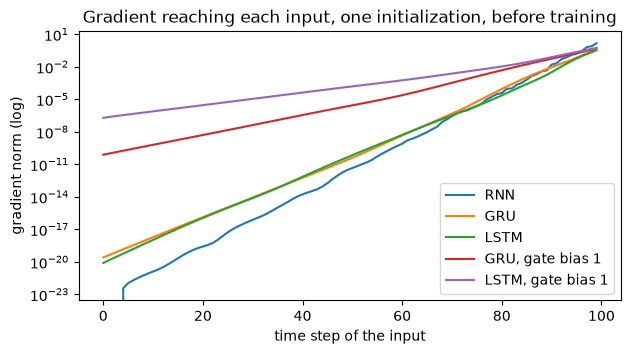

In [28]:
GATE_BIAS = 1.0


def open_gate(module: nn.Module, value: float) -> nn.Module:
    """LSTM(input, forget, cell, output)의 forget, GRU(r, z, n)의 z 게이트 편향 합을 value로 맞춥니다."""
    hidden = module.hidden_size
    # 두 편향이 더해지므로 한쪽을 0으로 두어야 합이 value가 된다
    module.bias_ih_l0.data[hidden:2 * hidden] = 0.0
    module.bias_hh_l0.data[hidden:2 * hidden] = value
    return module


set_seed()
candidates = {"RNN": nn.RNN(INPUT_SIZE, HIDDEN_SIZE, batch_first=True),
              "GRU": nn.GRU(INPUT_SIZE, HIDDEN_SIZE, batch_first=True),
              "LSTM": nn.LSTM(INPUT_SIZE, HIDDEN_SIZE, batch_first=True),
              "GRU, gate bias 1": open_gate(nn.GRU(INPUT_SIZE, HIDDEN_SIZE, batch_first=True), GATE_BIAS),
              "LSTM, gate bias 1": open_gate(nn.LSTM(INPUT_SIZE, HIDDEN_SIZE, batch_first=True), GATE_BIAS)}
plt.figure(figsize=(7, 3.5))
for name, module in candidates.items():
    grads = input_grad_by_time(module, SEQ_LEN)
    plt.semilogy(grads, label=name)
    # 첫 시각은 0으로 잘릴 수 있어 뒤쪽 50칸에서 한 칸당 줄어드는 비율을 잰다
    ratio_per_step = (grads[SEQ_LEN // 2] / grads[-1]) ** (1 / (SEQ_LEN // 2 - 1))
    print(f"{name:18s}: 첫 시각 {grads[0]:.1e}, 마지막 시각 {grads[-1]:.1e}, 한 칸당 비 {ratio_per_step:.3f}")
plt.xlabel("time step of the input")
plt.ylabel("gradient norm (log)")
plt.title("Gradient reaching each input, one initialization, before training")
plt.legend()
plt.show()

기본 초기값에서는 **LSTM과 GRU도 RNN과 같은 수준으로** 먼 과거의 기울기가 사라집니다. 기본 편향은 평균 0인 작은 난수($\pm 1/\sqrt{\text{hidden}}$ 범위)라 게이트가 0.5 근처에서 시작하기 때문입니다. "시각마다 절반쯤 줄어든다"는 직관과 비슷하게 한 칸당 비는 약 0.6입니다. $h$를 거치는 경로가 더 있어 게이트 값과 정확히 같지는 않습니다. 게이트 편향의 합을 1로 올리면 sigmoid(1) ≈ 0.73에서 시작하고, 한 칸당 비가 LSTM은 약 0.85, GRU는 약 0.78로 올라갑니다. 작아 보이는 차이지만 100칸을 지나면 첫 시각 기울기의 자릿수가 크게 달라집니다(LSTM 약 $10^{-20}$ → $10^{-7}$). 게이트는 **통로를 열 수 있게 해 줄 뿐** 처음부터 열려 있지는 않습니다.

그래서 긴 의존성을 직접 시험합니다. 과제는 **"시퀀스의 맨 첫 숫자가 양수였는가"** 입니다. 뒤의 숫자는 전부 잡음이라, 첫 입력을 끝까지 기억해야만 찍기(0.5)를 넘습니다. 길이를 바꿔 가며 시드 5개로 잽니다. 시간이 꽤 걸리는 셀입니다(소요 시간은 출력의 마지막 줄을 보세요).

In [29]:
MEMORY_LENGTHS = [10, 20, 30]
MEMORY_HIDDEN = 32
MEMORY_STEPS = 3000
MEMORY_SEEDS = 5


class MemoryClassifier(nn.Module):
    def __init__(self, recurrent: nn.Module) -> None:
        super().__init__()
        self.recurrent = recurrent
        self.fc = nn.Linear(recurrent.hidden_size, 1)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.fc(self.recurrent(x)[0][:, -1]).squeeze(-1)


def memory_batch(n: int, length: int) -> tuple[torch.Tensor, torch.Tensor]:
    x = torch.randn(n, length, 1)
    return x, (x[:, 0, 0] > 0).float()


def run_memory_task(make_recurrent: Callable[[], nn.Module], length: int) -> list[float]:
    """시드마다 학습해 새 데이터에서의 정확도를 돌려줍니다. 작은 모델이라 CPU가 충분히 빠릅니다."""
    scores = []
    for seed in range(MEMORY_SEEDS):
        set_seed(seed)
        memory_model = MemoryClassifier(make_recurrent())
        memory_optimizer = optim.Adam(memory_model.parameters(), lr=0.001)
        for _ in range(MEMORY_STEPS):
            x, y = memory_batch(64, length)
            memory_optimizer.zero_grad()
            F.binary_cross_entropy_with_logits(memory_model(x), y).backward()
            memory_optimizer.step()
        x, y = memory_batch(2000, length)
        with torch.no_grad():
            scores.append(((memory_model(x) > 0).float() == y).float().mean().item())
    return scores


memory_candidates = {
    "RNN": lambda: nn.RNN(1, MEMORY_HIDDEN, batch_first=True),
    "GRU": lambda: nn.GRU(1, MEMORY_HIDDEN, batch_first=True),
    "LSTM": lambda: nn.LSTM(1, MEMORY_HIDDEN, batch_first=True),
    "GRU, gate bias 1": lambda: open_gate(nn.GRU(1, MEMORY_HIDDEN, batch_first=True), GATE_BIAS),
    "LSTM, gate bias 1": lambda: open_gate(nn.LSTM(1, MEMORY_HIDDEN, batch_first=True), GATE_BIAS),
}
memory_start = time.time()
for length in MEMORY_LENGTHS:
    print(f"길이 {length}")
    for name, make_recurrent in memory_candidates.items():
        scores = run_memory_task(make_recurrent, length)
        print(f"  {name:18s}: {np.round(scores, 3)}")
print(f"소요 시간: {(time.time() - memory_start) / 60:.1f}분")

길이 10


  RNN               : [0.996 0.985 0.775 0.997 0.783]


  GRU               : [0.989 0.996 0.989 0.991 0.992]


  LSTM              : [0.98  0.988 0.987 0.996 0.988]


  GRU, gate bias 1  : [0.99  0.994 0.991 0.993 0.993]


  LSTM, gate bias 1 : [0.98  0.987 0.979 0.994 0.987]
길이 20


... (6 outputs left out)

  GRU               : [0.493 0.498 0.484 0.489 0.499]


  LSTM              : [0.477 0.502 0.516 0.5   0.512]


  GRU, gate bias 1  : [0.998 0.819 0.994 0.989 0.998]


  LSTM, gate bias 1 : [0.767 0.996 0.993 0.512 0.988]
소요 시간: 6.2분


읽는 법입니다.

- **길이 10**: 대부분 풉니다. 기본 RNN만 시드 5개 중 2개가 약 0.78에 머뭅니다.
- **길이 20**: 기본 LSTM은 5개 모두 찍기 수준이고, 기본 RNN은 1~2개, 기본 GRU는 3개만 풉니다. **기본 설정끼리는 순위가 안정적이지 않습니다.** 게이트를 연 두 모델은 대체로 풉니다(LSTM의 한 시드는 약 0.81).
- **길이 30**: 기본 초기값은 셋 다 찍기 수준입니다. 게이트를 연 GRU는 5개 중 4개가 0.98을 넘고(나머지 약 0.82), LSTM은 3개가 0.98을 넘지만 1개는 약 0.77, 1개는 찍기 수준입니다.

이 조건에서는 **게이트의 종류보다 초기값의 차이가 더 컸습니다.** 이것이 forget 게이트 편향을 양수로 초기화하라는 권장의 이유입니다([Jozefowicz et al., 2015](https://proceedings.mlr.press/v37/jozefowicz15.pdf)). 내장 `nn.LSTM`은 이렇게 초기화하지 않으므로 긴 시퀀스에서는 직접 설정해야 합니다. 앞의 MNIST에서 LSTM과 GRU가 RNN보다 나았던 것은 답의 단서가 시퀀스 곳곳에 흩어져 있어, 맨 처음을 끝까지 기억하지 않아도 되는 과제였기 때문으로 보입니다. 시드 5개, 3000 스텝의 결과이고 시드에 따른 차이가 크므로, 더 오래 학습하거나 설정을 바꾸면 달라질 수 있습니다.

## 2.6 RNN 계열의 문제점

게이트로 기울기 문제를 줄여도 구조에서 오는 한계가 남습니다.

1. **무조건 순차적으로 계산해야 합니다.** 시각 t는 t-1이 끝나야 계산할 수 있어 시간 축으로는 병렬화할 수 없습니다.
2. **먼 곳까지 정보를 전달하기가 쉽지 않습니다.** 번역하는 Seq2Seq 모델을 떠올려 보세요. 인코더 RNN이 문장 전체를 읽고 **마지막 은닉 상태 벡터 하나**만 디코더에 넘깁니다. 문장이 길어도 그 벡터의 크기는 고정이라 앞쪽 단어의 정보가 희미해집니다.

다음 부의 어텐션은 이 **병목**을 없앱니다. ([인코더-디코더 RNN 애니메이션](https://user-images.githubusercontent.com/45377884/86040995-f27b4800-ba7f-11ea-8ca1-67b2517573eb.gif))

### 실습 2. 파라미터 수 공식과 출력의 관계

입력 크기 `i`, 은닉 크기 `h`인 1층 순환 모듈의 파라미터 수는 "한 묶음 $(i\cdot h + h\cdot h + 2h)$ × 묶음 수"입니다. 내장 모듈은 입력 쪽과 은닉 쪽에 편향을 하나씩 두어 $2h$입니다. RNN은 묶음 1개, GRU는 3개, LSTM은 4개입니다.

1. 함수 `count_recurrent_params(kind, i, h)`를 작성하세요. `kind`는 `"RNN"`, `"GRU"`, `"LSTM"` 중 하나입니다.
2. `nn.LSTM(10, 20, batch_first=True)`에 무작위 입력을 넣고, `out[:, -1]`과 `hn[0]`이 같은지 확인하세요. many to one에서 왜 둘 중 어느 쪽을 써도 되는지 답합니다.

In [30]:
# 여기에 작성하세요

<details><summary>정답</summary>

```python
def count_recurrent_params(kind: str, i: int, h: int) -> int:
    n_groups = {"RNN": 1, "GRU": 3, "LSTM": 4}[kind]
    return n_groups * (i * h + h * h + 2 * h)

for kind, cls in [("RNN", nn.RNN), ("GRU", nn.GRU), ("LSTM", nn.LSTM)]:
    module = cls(10, 20, batch_first=True)
    actual = sum(p.numel() for p in module.parameters())
    assert actual == count_recurrent_params(kind, 10, 20), kind

lstm = nn.LSTM(10, 20, batch_first=True)
out, (hn, cn) = lstm(torch.randn(2, 5, 10))
# 1층이면 마지막 시각의 출력이 곧 마지막 은닉 상태다
assert torch.allclose(out[:, -1], hn[0])
print("공식과 출력 관계 모두 확인했습니다")
```

</details>

---
# 3부. 어텐션

논문: [Attention Is All You Need](https://arxiv.org/pdf/1706.03762.pdf) · 함께 읽기: [The Illustrated Transformer 한국어 번역](https://nlpinkorean.github.io/illustrated-transformer/)

## 3.1 Seq2Seq 어텐션: 벡터 하나에 다 담지 말자

어텐션의 발상은 단순합니다. **디코더가 단어를 하나 낼 때마다 인코더의 모든 은닉 상태를 다시 보고, 지금 필요한 것에 가중치를 주어 섞어 씁니다.** "Je suis étudiant"를 번역할 때 "I"를 낼 때는 "Je"를, "am"을 낼 때는 "suis"를 주로 봅니다.

그림(Attention at time step 4)의 다섯 단계를 코드로 옮깁니다.

1. 인코더 은닉 상태 $h_1, h_2, h_3$와 디코더 은닉 상태를 준비합니다.
2. 각 인코더 상태에 점수를 매깁니다. 그림의 점수는 13, 9, 9입니다.
3. 점수에 softmax를 씌웁니다. 그림의 결과는 0.96, 0.02, 0.02입니다.
4. 각 벡터에 softmax 값을 곱합니다.
5. 곱한 벡터를 모두 더합니다. 이것이 이 시각의 **컨텍스트 벡터**입니다.

그림 출처: [어텐션 다섯 단계](https://velog.velcdn.com/images%2Fyuns_u%2Fpost%2F885a41ae-e222-4f56-8c49-e708c022aa13%2Fimage.png) · [Je suis étudiant 정렬 애니메이션](https://user-images.githubusercontent.com/45377884/86047018-29a22700-ba89-11ea-98ee-a90b2fb70a23.gif)

In [31]:
# 2~5단계: 그림의 숫자를 그대로 넣어 본다
scores = torch.tensor([13.0, 9.0, 9.0])
weights = scores.softmax(dim=0)
print("softmax 결과:", weights.numpy().round(2))
assert torch.allclose(weights, torch.tensor([0.96, 0.02, 0.02]), atol=0.01)

encoder_states = torch.tensor([[1.0, 0.0, 2.0],    # h1
                               [0.0, 3.0, 1.0],    # h2
                               [2.0, 1.0, 0.0]])   # h3
context = weights @ encoder_states  # 가중합. 점수가 높은 h1이 대부분을 차지한다
print("컨텍스트 벡터:", context.numpy().round(3))

softmax 결과: [0.96 0.02 0.02]
컨텍스트 벡터: [1.    0.071 1.947]


## 3.2 Scaled Dot-Product Attention

Transformer의 어텐션 층은 두 가지입니다. 하나는 **Scaled Dot-Product Attention**이고, 다른 하나는 이것을 여러 개 쓰는 **Multi-Head Attention**입니다.

입력은 셋입니다. 검색에 비유하면 **Query**는 검색어, **Key**는 문서의 색인, **Value**는 문서 내용입니다. Query와 Key가 얼마나 맞는지로 가중치를 구하고, 그 가중치로 Value를 섞습니다. Query와 Key는 $d_k$ 차원, Value는 $d_v$ 차원입니다.

$$\text{Attention}(Q, K, V) = \text{softmax}\left(\frac{QK^T}{\sqrt{d_k}}\right)V$$

계산 순서는 MatMul($QK^T$) → Scale($\sqrt{d_k}$로 나눔) → Mask(선택) → SoftMax → MatMul($V$)입니다.

**왜 $\sqrt{d_k}$로 나눌까요?** 스케일을 하지 않으면 내적 값이 차원과 함께 커져, softmax가 거의 원핫이 되고 기울기가 매우 작아집니다. 논문의 설명은 이렇습니다. $q, k$의 각 성분이 평균 0, 분산 1로 독립이면 내적 $\sum_i q_i k_i$의 분산은 $d_k$입니다. 표준편차 $\sqrt{d_k}$로 나누면 분산이 1로 돌아옵니다. 아래에서 확인합니다.

> 어텐션 함수로는 내적 말고 additive attention도 있습니다. 이론적인 복잡도는 비슷하지만, 내적은 행렬곱 한 번으로 계산되므로 실제로는 더 빠르고 메모리도 덜 씁니다. 논문은 스케일이 없으면 $d_k$가 클 때 additive 쪽이 더 낫다고 보고하는데, $\sqrt{d_k}$로 나누는 이유가 바로 이것입니다.

그림 출처: [Scaled Dot-Product Attention 구조](https://github.com/happy-jihye/Natural-Language-Processing/blob/main/images/transformer2.png?raw=1)

In [32]:
def scaled_dot_product_attention(q: torch.Tensor, k: torch.Tensor, v: torch.Tensor,
                                 mask: torch.Tensor | None = None) -> tuple[torch.Tensor, torch.Tensor]:
    """수식 그대로의 어텐션입니다. mask가 0인 위치는 보지 못하게 합니다."""
    d_k = k.size(-1)
    energy = q @ k.transpose(-2, -1) / math.sqrt(d_k)
    if mask is not None:
        # softmax 전에 아주 작은 값으로 덮어써야 그 위치의 확률이 0이 된다
        energy = energy.masked_fill(mask == 0, -1e10)
    attention = energy.softmax(dim=-1)
    return attention @ v, attention


set_seed()
q_toy, k_toy, v_toy = torch.randn(2, 3, 8), torch.randn(2, 5, 8), torch.randn(2, 5, 16)
out_toy, attn_toy = scaled_dot_product_attention(q_toy, k_toy, v_toy)
print("출력:", out_toy.shape, "| 어텐션:", attn_toy.shape, "(배치, query 수, key 수)")
print("각 query의 가중치 합:", attn_toy.sum(-1)[0].numpy().round(4))

# PyTorch에 내장된 함수와 값이 같아야 한다
official_out = F.scaled_dot_product_attention(q_toy, k_toy, v_toy)
assert torch.allclose(out_toy, official_out, atol=1e-5)
print("F.scaled_dot_product_attention과 일치")

출력: torch.Size([2, 3, 16]) | 어텐션: torch.Size([2, 3, 5]) (배치, query 수, key 수)
각 query의 가중치 합: [1. 1. 1.]
F.scaled_dot_product_attention과 일치


In [33]:
# sqrt(d_k)로 나누는 이유를 숫자로 확인한다
set_seed()
print(f"{'d_k':>5} | {'내적 분산':>9} | {'스케일 후 분산':>12} | {'스케일 없음: 최대 확률':>20} | {'스케일: 최대 확률':>16}")
for d_k in [4, 64, 512, 4096]:
    q_s, k_s = torch.randn(10000, 1, d_k), torch.randn(10000, 10, d_k)
    dots = (q_s @ k_s.transpose(-2, -1)).squeeze(1)
    print(f"{d_k:5d} | {dots.var():9.1f} | {(dots / math.sqrt(d_k)).var():12.3f} | "
          f"{dots.softmax(-1).max(-1).values.mean():20.3f} | {(dots / math.sqrt(d_k)).softmax(-1).max(-1).values.mean():16.3f}")

  d_k |     내적 분산 |     스케일 후 분산 |        스케일 없음: 최대 확률 |       스케일: 최대 확률
    4 |       4.0 |        1.007 |                0.493 |            0.305
   64 |      64.1 |        1.001 |                0.863 |            0.318


  512 |     515.4 |        1.007 |                0.951 |            0.320


 4096 |    4114.3 |        1.004 |                0.983 |            0.320


내적의 분산은 정말 $d_k$를 따라가고, 스케일 후에는 1 근처입니다. 스케일이 없으면 차원이 클수록 최대 확률이 1에 붙습니다. softmax가 이렇게 포화되면 기울기가 거의 0입니다.

## 3.3 Self-Attention

Q, K, V가 **모두 같은 문장**에서 오면 **셀프 어텐션**입니다. 문장의 각 단어가 같은 문장의 다른 단어들을 보고 자기 표현을 고칩니다. RNN과 달리 첫 단어와 마지막 단어가 **한 번에** 연결되고, 모든 위치를 동시에 계산할 수 있습니다. 2.6절의 두 문제가 함께 풀립니다.

아래는 임의의 임베딩으로 모양과 흐름만 보는 예입니다. 학습 전이라 가중치 값에 의미는 없습니다.

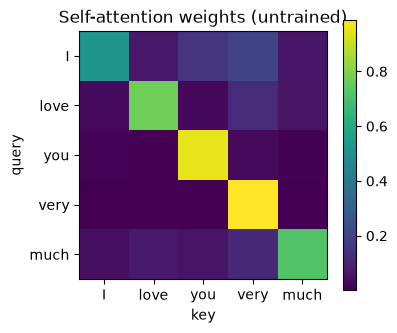

In [34]:
set_seed()
words = ["I", "love", "you", "very", "much"]
x_words = torch.randn(1, len(words), 16)
_, self_attn = scaled_dot_product_attention(x_words, x_words, x_words)

fig, ax = plt.subplots(figsize=(4, 3.5))
im = ax.imshow(self_attn[0].numpy(), cmap="viridis")
ax.set_xticks(range(len(words)), words)
ax.set_yticks(range(len(words)), words)
ax.set_xlabel("key")
ax.set_ylabel("query")
ax.set_title("Self-attention weights (untrained)")
fig.colorbar(im)
plt.show()

## 3.4 Multi-Head Attention

전체 차원으로 어텐션을 한 번 하는 대신, Q, K, V를 **head 개수 $h$만큼 나눠 $h$번** 어텐션을 하고 다시 이어 붙입니다.

$$\text{MultiHead}(Q, K, V) = \text{Concat}(\text{head}_1,\dots,\text{head}_h)W^O, \quad \text{head}_i = \text{Attention}(QW_i^Q, KW_i^K, VW_i^V)$$

파라미터는 $W_i^Q, W_i^K \in \mathbb{R}^{d_{\text{model}}\times d_k}$, $W_i^V \in \mathbb{R}^{d_{\text{model}}\times d_v}$, $W^O \in \mathbb{R}^{hd_v\times d_{\text{model}}}$입니다. 논문은 $h=8$, $d_k=d_v=d_{\text{model}}/h=64$를 씁니다.

**왜 나눌까요?** 병렬 계산이 가능한 것은 부수 효과입니다. 논문이 든 이유는 **여러 표현 공간에서 서로 다른 위치에 함께 주목할 수 있다**는 것입니다. head가 하나면 평균을 내는 효과로 이것이 억제된다고 합니다. 각 head의 차원이 줄어드니 전체 계산량은 한 번 하는 경우와 비슷합니다.

코드는 head마다 선형층을 따로 두지 않고, `hid_dim → hid_dim` 선형층 하나를 지나게 한 뒤 `view`로 나눕니다. 다음 절부터 쓸 번역 모델의 부품입니다.

그림 출처: [Multi-Head Attention 구조](https://github.com/happy-jihye/Natural-Language-Processing/blob/main/images/transformer3.png?raw=1)

In [35]:
class MultiHeadAttentionLayer(nn.Module):
    def __init__(self, hid_dim: int, n_heads: int, dropout: float, device: torch.device) -> None:
        super().__init__()
        assert hid_dim % n_heads == 0   # 나누어떨어져야 head로 쪼갤 수 있다

        self.hid_dim = hid_dim
        self.n_heads = n_heads
        self.head_dim = hid_dim // n_heads

        self.fc_q = nn.Linear(hid_dim, hid_dim)
        self.fc_k = nn.Linear(hid_dim, hid_dim)
        self.fc_v = nn.Linear(hid_dim, hid_dim)
        self.fc_o = nn.Linear(hid_dim, hid_dim)     # 수식의 W^O

        self.dropout = nn.Dropout(dropout)
        # 수식의 sqrt(d_k). head 하나의 차원이 d_k다
        self.scale = torch.sqrt(torch.FloatTensor([self.head_dim])).to(device)

    def forward(self, query: torch.Tensor, key: torch.Tensor, value: torch.Tensor,
                mask: torch.Tensor | None = None) -> tuple[torch.Tensor, torch.Tensor]:
        batch_size = query.shape[0]
        # query = [batch, query len, hid dim], key·value = [batch, key len, hid dim]

        Q = self.fc_q(query)
        K = self.fc_k(key)
        V = self.fc_v(value)

        # hid dim을 (n heads, head dim)으로 쪼개고 head 축을 앞으로 보낸다
        Q = Q.view(batch_size, -1, self.n_heads, self.head_dim).permute(0, 2, 1, 3)
        K = K.view(batch_size, -1, self.n_heads, self.head_dim).permute(0, 2, 1, 3)
        V = V.view(batch_size, -1, self.n_heads, self.head_dim).permute(0, 2, 1, 3)
        # Q = [batch, n heads, query len, head dim]

        energy = torch.matmul(Q, K.permute(0, 1, 3, 2)) / self.scale
        # energy = [batch, n heads, query len, key len]

        if mask is not None:
            energy = energy.masked_fill(mask == 0, -1e10)

        attention = torch.softmax(energy, dim=-1)
        x = torch.matmul(self.dropout(attention), V)
        # x = [batch, n heads, query len, head dim]

        # head를 다시 이어 붙인다 (Concat)
        x = x.permute(0, 2, 1, 3).contiguous()
        x = x.view(batch_size, -1, self.hid_dim)
        # x = [batch, query len, hid dim]

        return self.fc_o(x), attention

In [36]:
mha = MultiHeadAttentionLayer(hid_dim=512, n_heads=8, dropout=0.0, device=device).to(device)
x_mha = torch.randn(2, 10, 512, device=device)
y_mha, attn_mha = mha(x_mha, x_mha, x_mha)
print("입력:", x_mha.shape, "→ 출력:", y_mha.shape, "(모양이 같아 층을 쌓을 수 있다)")
print("어텐션:", attn_mha.shape, "(배치, head, query, key)")
print("head 하나의 차원 d_k:", mha.head_dim)

# 첫 head의 어텐션을 3.2절 함수로 다시 계산해 수식과 맞는지 확인한다
with torch.no_grad():
    q0 = mha.fc_q(x_mha)[..., :mha.head_dim]
    k0 = mha.fc_k(x_mha)[..., :mha.head_dim]
    v0 = mha.fc_v(x_mha)[..., :mha.head_dim]
    _, by_function = scaled_dot_product_attention(q0, k0, v0)
assert torch.allclose(by_function, attn_mha[:, 0], atol=1e-4)
print("첫 head의 어텐션이 scaled_dot_product_attention과 일치")

입력: torch.Size([2, 10, 512]) → 출력: torch.Size([2, 10, 512]) (모양이 같아 층을 쌓을 수 있다)
어텐션: torch.Size([2, 8, 10, 10]) (배치, head, query, key)
head 하나의 차원 d_k: 64
첫 head의 어텐션이 scaled_dot_product_attention과 일치


**지금의 PyTorch에서는** 위의 내적, 스케일, 마스크, softmax 네 줄을 `F.scaled_dot_product_attention` 한 줄로 씁니다. 장치에 맞는 빠른 구현(flash attention 등)을 자동으로 고르기 때문입니다. 불리언 마스크는 `True`가 "봐도 된다"입니다. 대신 어텐션 가중치를 돌려주지 않으므로, 이 강의처럼 어텐션 지도를 그릴 때는 직접 구현이 편합니다. 층 전체가 필요하면 `nn.MultiheadAttention`도 있습니다. 주의할 점은 이 모듈의 불리언 마스크가 **반대**라는 것입니다. `True`가 "보지 않는다"입니다.

In [37]:
class FastMultiHeadAttention(MultiHeadAttentionLayer):
    """내적 계산만 내장 함수로 바꾼 버전입니다. 어텐션 가중치는 돌려주지 않습니다."""

    def forward(self, query: torch.Tensor, key: torch.Tensor, value: torch.Tensor,
                mask: torch.Tensor | None = None) -> torch.Tensor:
        batch_size = query.shape[0]
        split = lambda t: t.view(batch_size, -1, self.n_heads, self.head_dim).transpose(1, 2)
        Q, K, V = split(self.fc_q(query)), split(self.fc_k(key)), split(self.fc_v(value))
        x = F.scaled_dot_product_attention(Q, K, V, attn_mask=mask, dropout_p=self.dropout.p if self.training else 0.0)
        return self.fc_o(x.transpose(1, 2).contiguous().view(batch_size, -1, self.hid_dim))


fast_mha = FastMultiHeadAttention(hid_dim=512, n_heads=8, dropout=0.0, device=device).to(device)
fast_mha.load_state_dict(mha.state_dict())
with torch.no_grad():
    assert torch.allclose(fast_mha(x_mha, x_mha, x_mha), y_mha, atol=1e-4)
print("직접 구현과 내장 함수의 출력이 같습니다")

직접 구현과 내장 함수의 출력이 같습니다


## 3.5 Transformer 안의 세 가지 어텐션과 마스킹

Transformer는 Multi-Head Attention을 세 군데서 씁니다.

1. **Encoder self-attention**: Q, K, V가 모두 이전 인코더 층의 출력에서 옵니다. 이전 층의 모든 위치를 볼 수 있습니다.
2. **Masked self-attention(Decoder)**: 디코더는 다음 단어를 맞혀야 하므로 **자기 뒤의 단어를 보면 안 됩니다.** 이것을 막는 것이 마스킹입니다.
3. **Encoder-decoder attention**(cross-attention): Q는 디코더의 이전 층에서, K와 V는 인코더의 출력에서 옵니다. 디코더의 각 위치가 입력 문장 전체를 볼 수 있습니다. 3.1절의 Seq2Seq 어텐션과 같은 역할입니다.

**자주 헷갈리는 두 가지**

- "I love you"에서 `love`가 `I`만 본다고 오해하기 쉽습니다. 논문은 "그 위치까지(포함)"라고 씁니다. **`love`는 `I`와 자기 자신을, `you`는 셋 다 봅니다.** 정답을 보지 않는 것은 디코더 입력을 한 칸 밀어 넣기 때문입니다(4.7절).
- 마스크는 음의 무한대를 **곱하는 것이 아닙니다.** 곱하면 음수 점수가 양의 무한대가 되고 0은 NaN이 됩니다. 그 위치의 값을 아주 작은 값으로 **덮어씁니다.** 그러면 softmax 결과가 0이 됩니다. 코드는 `-1e10`을 씁니다.

아래에서 마스크의 모양과 효과를 봅니다.

tensor([[1, 0, 0],
        [1, 1, 0],
        [1, 1, 1]], dtype=torch.int32)


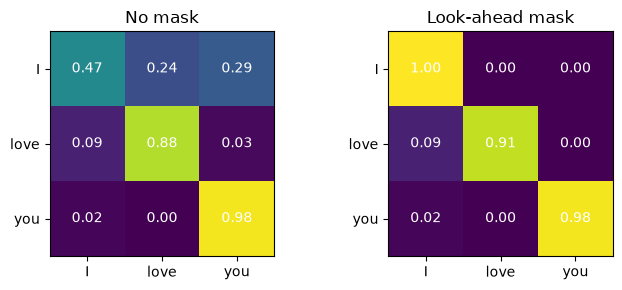

In [38]:
# 아래 삼각 행렬: 행(query)은 열(key) 중 자기 위치까지만 볼 수 있다
sentence = ["I", "love", "you"]
look_ahead_mask = torch.tril(torch.ones(3, 3)).bool()
print(look_ahead_mask.int())

set_seed()
x_three = torch.randn(1, 3, 8)
_, unmasked = scaled_dot_product_attention(x_three, x_three, x_three)
_, masked = scaled_dot_product_attention(x_three, x_three, x_three, mask=look_ahead_mask)

fig, axes = plt.subplots(1, 2, figsize=(7, 3))
for ax, data, title in zip(axes, [unmasked, masked], ["No mask", "Look-ahead mask"]):
    im = ax.imshow(data[0].numpy(), cmap="viridis", vmin=0, vmax=1)
    ax.set_xticks(range(3), sentence)
    ax.set_yticks(range(3), sentence)
    for row in range(3):
        for col in range(3):
            ax.text(col, row, f"{data[0, row, col]:.2f}", ha="center", va="center", color="white")
    ax.set_title(title)
plt.tight_layout()
plt.show()

assert masked[0, 0, 0] == 1 and masked[0, 0, 1:].sum() == 0   # I는 자기 자신만 본다

## 3.6 Position-wise Feed Forward Networks

어텐션 층 뒤에는 **완전연결 신경망**이 붙습니다. 선형층 두 개와 ReLU로 이루어지고, 각 위치(단어)에 **같은 신경망을 따로따로** 적용합니다. 그래서 position-wise입니다.

$$\text{FFN}(x)=\max(0, xW_1+b_1)W_2+b_2$$

입출력 차원은 $d_{\text{model}} = 512$, 내부 차원은 $d_{ff} = 2048$입니다. 어텐션의 출력은 Value의 **가중합**이라 Value에 대해 선형이고, 그 위에 비선형 변환을 이 층이 더합니다.

> FFN의 내부 층은 메모리를 많이 씁니다. [Reformer](https://arxiv.org/abs/2001.04451)는 reversible residual layer와 chunking으로 이를 개선합니다.

In [39]:
class PositionwiseFeedforwardLayer(nn.Module):
    def __init__(self, hid_dim: int, pf_dim: int, dropout: float) -> None:
        super().__init__()
        self.fc_1 = nn.Linear(hid_dim, pf_dim)
        self.fc_2 = nn.Linear(pf_dim, hid_dim)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # x = [batch, seq len, hid dim]. nn.Linear는 마지막 축에만 작용하므로 위치별로 같은 층이 적용된다
        x = self.dropout(torch.relu(self.fc_1(x)))  # [batch, seq len, pf dim]
        return self.fc_2(x)                         # [batch, seq len, hid dim]

## 3.7 Embeddings and Softmax

- 다른 시퀀스 변환 모델처럼 입력과 출력의 토큰을 $d_{\text{model}}$ 차원으로 **임베딩**합니다.
- 디코더 출력은 **선형 변환과 softmax**로 다음 토큰의 확률로 바꿉니다.
- 논문은 입력 임베딩, 출력 임베딩, softmax 앞의 선형 변환이 **같은 가중치를 공유**하게 합니다. 임베딩 층에서는 이 가중치에 $\sqrt{d_{\text{model}}}$을 곱합니다. (4부 실습 코드는 $\sqrt{d_{\text{model}}}$ 곱셈만 따르고, 어휘가 서로 다른 번역이라 가중치는 공유하지 않습니다.)

## 3.8 Positional Encoding

Transformer에는 RNN이나 CNN이 없으므로 **단어 순서를 따로 알려 줘야 합니다.** 3.3절의 어텐션은 입력 순서를 바꾸면 출력도 똑같이 순서만 바뀝니다. **Positional encoding**은 임베딩과 같은 $d_{\text{model}}$ 차원의 벡터이고, 임베딩에 **더해서** 위치 정보를 넣습니다.

$$PE_{(pos,2i)}=\sin\left(\frac{pos}{10000^{2i/d_{\text{model}}}}\right), \qquad PE_{(pos,2i+1)}=\cos\left(\frac{pos}{10000^{2i/d_{\text{model}}}}\right)$$

위치 임베딩을 학습할 수도 있지만, 논문은 sinusoid로도 비슷한 성능이 나와 이 함수를 택했다고 합니다. 4부 실습 코드는 BERT처럼 **학습하는 위치 임베딩**을 씁니다.

torch.Size([50, 128])


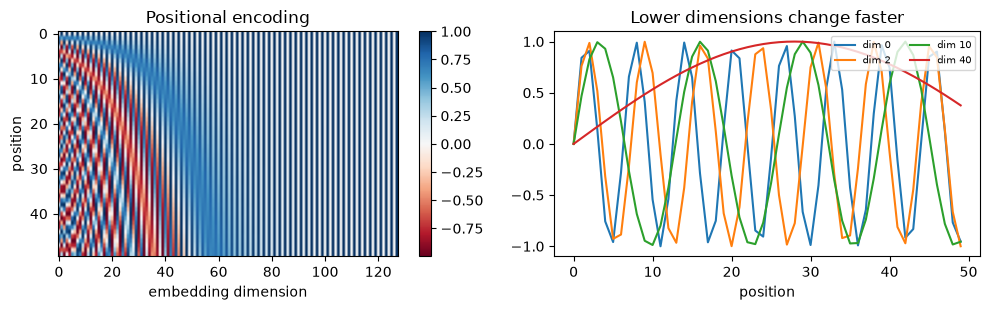

위치 10과의 코사인 유사도 (위치 10, 11, 15, 30): [1.0, 0.97, 0.737, 0.608]


In [40]:
def positional_encoding(max_len: int, d_model: int) -> torch.Tensor:
    """논문의 sinusoid 위치 인코딩을 (max_len, d_model) 텐서로 돌려줍니다."""
    pos = torch.arange(max_len, dtype=torch.float).unsqueeze(1)
    # 10000^(2i/d_model)을 2i = 0, 2, 4, ... 에 대해 계산한다
    denominator = 10000 ** (torch.arange(0, d_model, 2, dtype=torch.float) / d_model)
    pe = torch.zeros(max_len, d_model)
    pe[:, 0::2] = torch.sin(pos / denominator)
    pe[:, 1::2] = torch.cos(pos / denominator)
    return pe


pe = positional_encoding(50, 128)
print(pe.shape)
# 수식에 숫자를 직접 넣어 검산한다
pos_check, i_check, d_check = 7, 3, 128
assert math.isclose(pe[pos_check, 2 * i_check], math.sin(pos_check / 10000 ** (2 * i_check / d_check)), abs_tol=1e-6)
assert math.isclose(pe[pos_check, 2 * i_check + 1], math.cos(pos_check / 10000 ** (2 * i_check / d_check)), abs_tol=1e-6)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
im = axes[0].imshow(pe.numpy(), cmap="RdBu", aspect="auto")
axes[0].set_xlabel("embedding dimension")
axes[0].set_ylabel("position")
axes[0].set_title("Positional encoding")
fig.colorbar(im, ax=axes[0])
for dim in [0, 2, 10, 40]:
    axes[1].plot(pe[:, dim].numpy(), label=f"dim {dim}")
axes[1].set_xlabel("position")
axes[1].set_title("Lower dimensions change faster")
axes[1].legend(loc="upper right", ncol=2, fontsize=7)
plt.tight_layout()
plt.show()

# 위치가 가까울수록 벡터가 비슷하다. 멀어질수록 내적이 작아지는지 본다
similarity_to_10 = F.cosine_similarity(pe[10:11], pe, dim=1)
print("위치 10과의 코사인 유사도 (위치 10, 11, 15, 30):",
      [round(similarity_to_10[p].item(), 3) for p in [10, 11, 15, 30]])

그림 왼쪽의 한 행이 한 위치의 벡터입니다. 앞쪽 차원은 위치에 따라 빠르게 진동하고 뒤쪽 차원은 느리게 변합니다. 이진수의 낮은 자리와 높은 자리처럼, 차원들을 함께 보면 위치를 구별할 수 있습니다.

### 실습 3. 미래를 보지 않는다는 것을 테스트로 증명하기

마스크가 제대로 동작하면, **t번째 출력은 t보다 뒤의 입력을 바꿔도 달라지지 않아야 합니다.**

1. 함수 `make_look_ahead_mask(n)`을 작성하세요. 크기 n×n의 불리언 아래 삼각 행렬을 돌려줍니다.
2. 무작위 입력 `x`(배치 1, 길이 6, 차원 8)로 3.2절 함수의 마스크 셀프 어텐션 출력을 구합니다.
3. `x`의 마지막 위치(인덱스 5)만 바꾼 `x2`로 다시 계산해, 앞쪽 다섯 위치의 출력이 그대로이고 마지막 위치만 변하는지 `assert`로 확인하세요.

In [41]:
# 여기에 작성하세요

<details><summary>정답</summary>

```python
def make_look_ahead_mask(n: int) -> torch.Tensor:
    return torch.tril(torch.ones(n, n)).bool()

set_seed()
x = torch.randn(1, 6, 8)
x2 = x.clone()
x2[0, 5] = torch.randn(8)   # 마지막 위치만 바꾼다
mask = make_look_ahead_mask(6)

out1, _ = scaled_dot_product_attention(x, x, x, mask)
out2, _ = scaled_dot_product_attention(x2, x2, x2, mask)

assert torch.allclose(out1[0, :5], out2[0, :5])         # 앞 다섯 위치는 그대로
assert not torch.allclose(out1[0, 5], out2[0, 5])       # 마지막 위치만 달라진다
print("앞 위치의 출력은 뒤 입력의 영향을 받지 않습니다")
```

</details>

---
# 4부. Transformer와 ViT

## 4.1 Transformer의 구조

전체는 인코더 스택과 디코더 스택입니다.

**Encoder**

- 같은 층이 N번 반복됩니다(논문은 N = 6).
- 층마다 **Multi-head Self-Attention**과 **Position-wise Feed-Forward network** 두 sub-layer가 있습니다.
- 두 sub-layer 모두 **residual connection** 뒤에 Layer Normalization을 합니다. 잔차를 바로 더할 수 있도록 임베딩과 sub-layer 출력 차원을 모두 512로 맞췄습니다.

**Decoder**

- 같은 층이 N = 6번 반복되고, 층마다 sub-layer가 3개입니다.
- 첫째는 **masked self-attention**입니다. 현재 위치 뒤의 단어를 보지 못합니다.
- 둘째는 인코더 출력을 받는 **Multi-head Attention**(encoder-decoder attention)입니다.
- 셋째는 인코더와 같은 Feed-Forward입니다.

**추론 흐름**(Je suis étudiant → I am a student)

1. 인코더가 입력 문장을 한 번 처리해 Key와 Value를 만듭니다.
2. 디코더는 시작 토큰으로 첫 단어를 냅니다.
3. **지금까지 낸 단어들**을 다시 입력으로 넣어 다음 단어를 냅니다. 이때 인코더는 다시 돌리지 않습니다.
4. 끝 토큰이 나오면 멈춥니다.

구조도는 아래에 직접 그렸습니다(논문 Figure 1과 같은 구조). 그림 출처: [디코딩 1단계](https://jalammar.github.io/images/t/transformer_decoding_1.gif) · [디코딩 2단계](https://jalammar.github.io/images/t/transformer_decoding_2.gif)

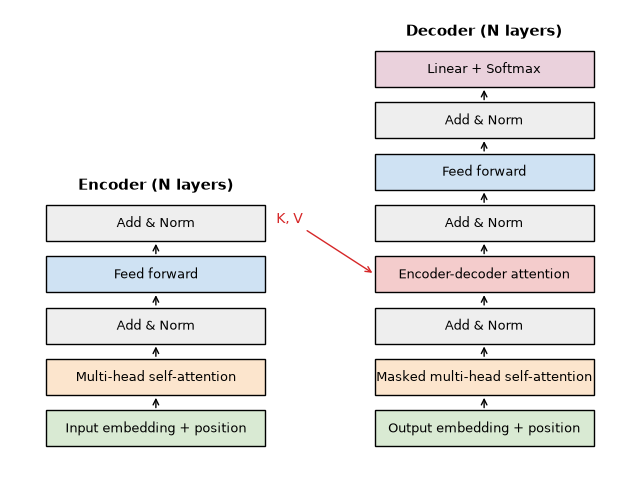

In [42]:
def draw_box(ax: plt.Axes, x: float, y: float, text: str, color: str, width: float = 3.0) -> None:
    """구조도의 상자 하나를 그립니다."""
    ax.add_patch(plt.Rectangle((x, y), width, 0.7, facecolor=color, edgecolor="black"))
    ax.text(x + width / 2, y + 0.35, text, ha="center", va="center", fontsize=9)


fig, ax = plt.subplots(figsize=(8, 6))
encoder_rows = [("Input embedding + position", "#d9ead3"), ("Multi-head self-attention", "#fce5cd"),
                ("Add & Norm", "#eeeeee"), ("Feed forward", "#cfe2f3"), ("Add & Norm", "#eeeeee")]
decoder_rows = [("Output embedding + position", "#d9ead3"), ("Masked multi-head self-attention", "#fce5cd"),
                ("Add & Norm", "#eeeeee"), ("Encoder-decoder attention", "#f4cccc"), ("Add & Norm", "#eeeeee"),
                ("Feed forward", "#cfe2f3"), ("Add & Norm", "#eeeeee"), ("Linear + Softmax", "#ead1dc")]
for i, (text, color) in enumerate(encoder_rows):
    draw_box(ax, 0.5, 0.5 + i, text, color)
for i, (text, color) in enumerate(decoder_rows):
    draw_box(ax, 5.0, 0.5 + i, text, color)
for x_center, n_rows in [(2.0, len(encoder_rows)), (6.5, len(decoder_rows))]:
    for i in range(n_rows - 1):
        ax.annotate("", (x_center, 1.5 + i), (x_center, 1.2 + i), arrowprops={"arrowstyle": "->"})
# 인코더 출력이 디코더의 cross-attention으로 들어간다
ax.annotate("K, V", (5.0, 3.85), (3.65, 4.85), arrowprops={"arrowstyle": "->", "color": "tab:red"},
            color="tab:red", fontsize=10)
ax.text(2.0, 5.5, "Encoder (N layers)", ha="center", fontsize=11, weight="bold")
ax.text(6.5, 8.5, "Decoder (N layers)", ha="center", fontsize=11, weight="bold")
ax.set_xlim(0, 8.5)
ax.set_ylim(0, 9)
ax.axis("off")
plt.show()

## 4.2 토크나이저

토크나이저는 문장을 개별 토큰으로 나눕니다. 예를 들어 "good morning!"은 `["good", "morning", "!"]`가 됩니다.

번역 데이터를 다루는 데 특별한 라이브러리는 필요 없습니다. 전처리가 하는 일은 아래가 전부이므로 직접 만듭니다.

- 토큰으로 나누기, 소문자로 바꾸기
- 시작과 끝에 `<sos>`, `<eos>` 붙이기
- 어휘 사전 만들고 번호로 바꾸기
- 패딩해서 배치로 묶기(배치 축을 맨 앞에 둠)

토크나이저는 정규식 한 줄로 충분합니다. 단어와 문장부호를 나눕니다. spaCy의 규칙 토크나이저(`spacy.blank`, 언어 모델을 받지 않아도 됨)와 나란히 비교합니다.

In [43]:
def tokenize(text: str) -> list[str]:
    """소문자로 바꾸고 단어와 문장부호를 나눕니다. 독일어와 영어에 함께 씁니다."""
    return re.findall(r"\w+|[^\w\s]", text.lower())


sample_de = "Zwei junge weiße Männer sind im Freien in der Nähe vieler Büsche."
print(tokenize("good morning!"))
print(tokenize(sample_de))

# spaCy가 있으면 비교해 본다 (없어도 이후 내용에는 영향이 없다)
try:
    import spacy
    spacy_de = spacy.blank("de")
    print("spaCy:", [tok.text.lower() for tok in spacy_de.tokenizer(sample_de)])
except ImportError:
    print("spaCy가 없어 비교를 건너뜁니다")

['good', 'morning', '!']
['zwei', 'junge', 'weiße', 'männer', 'sind', 'im', 'freien', 'in', 'der', 'nähe', 'vieler', 'büsche', '.']


spaCy: ['zwei', 'junge', 'weiße', 'männer', 'sind', 'im', 'freien', 'in', 'der', 'nähe', 'vieler', 'büsche', '.']


## 4.3 데이터셋: Multi30k

데이터셋은 [Multi30k](https://github.com/multi30k/dataset)입니다. 이미지 설명 문장을 영어와 독일어로 쓴 약 3만 쌍이고, 문장은 평균 13토큰 안팎으로 짧습니다. 독일어(de)를 source로, 영어(en)를 target으로 씁니다. Hugging Face의 `bentrevett/multi30k`에서 받습니다.

In [44]:
from datasets import Dataset, disable_progress_bars, load_dataset

disable_progress_bars()
multi30k = load_dataset("bentrevett/multi30k")


def build_examples(split: Dataset) -> list[dict[str, list[str]]]:
    """한 쌍을 {'src': 독일어 토큰들, 'trg': 영어 토큰들} 형태로 바꿉니다."""
    return [{"src": tokenize(row["de"]), "trg": tokenize(row["en"])} for row in split]


train_data = build_examples(multi30k["train"])
valid_data = build_examples(multi30k["validation"])
test_data = build_examples(multi30k["test"])

print(f"Number of training examples: {len(train_data)}")
print(f"Number of validation examples: {len(valid_data)}")
print(f"Number of testing examples: {len(test_data)}")

print(len(train_data[0]["src"]), len(train_data[1]["src"]))
print(train_data[0])
print(train_data[1])

src_lengths = [len(e["src"]) for e in train_data]
trg_lengths = [len(e["trg"]) for e in train_data]
print(f"평균 길이 de {np.mean(src_lengths):.1f}, en {np.mean(trg_lengths):.1f} / 최대 길이 de {max(src_lengths)}, en {max(trg_lengths)}")

Number of training examples: 29000
Number of validation examples: 1014
Number of testing examples: 1000
13 8
{'src': ['zwei', 'junge', 'weiße', 'männer', 'sind', 'im', 'freien', 'in', 'der', 'nähe', 'vieler', 'büsche', '.'], 'trg': ['two', 'young', ',', 'white', 'males', 'are', 'outside', 'near', 'many', 'bushes', '.']}
{'src': ['mehrere', 'männer', 'mit', 'schutzhelmen', 'bedienen', 'ein', 'antriebsradsystem', '.'], 'trg': ['several', 'men', 'in', 'hard', 'hats', 'are', 'operating', 'a', 'giant', 'pulley', 'system', '.']}
평균 길이 de 12.6, en 13.1 / 최대 길이 de 45, en 41


## 4.4 어휘 사전

각 토큰에 번호를 붙입니다. source와 target의 어휘는 따로 만듭니다.

- `min_freq=2`: 2번 이상 나온 단어만 어휘에 넣습니다. 한 번만 나온 단어는 `<unk>`로 바뀝니다.
- 어휘는 **training set에서만 만들어야 합니다.** validation이나 test의 단어까지 넣으면, 처음 보는 단어를 만나는 상황을 평가할 수 없어 결과가 부풀려집니다.

In [45]:
class Vocab:
    """토큰과 번호를 서로 바꾸는 어휘 사전입니다."""
    UNK, PAD, SOS, EOS = "<unk>", "<pad>", "<sos>", "<eos>"

    def __init__(self, tokenized_sentences: list[list[str]], min_freq: int = 2) -> None:
        counter = Counter(token for sentence in tokenized_sentences for token in sentence)
        specials = [self.UNK, self.PAD, self.SOS, self.EOS]
        # 자주 나오는 단어부터 번호를 준다
        self.itos = specials + [token for token, count in counter.most_common() if count >= min_freq]
        self.stoi = {token: index for index, token in enumerate(self.itos)}

    def __len__(self) -> int:
        return len(self.itos)

    def encode(self, tokens: list[str]) -> list[int]:
        """<sos>와 <eos>를 붙여 번호로 바꿉니다. 어휘에 없는 단어는 <unk>입니다."""
        unk = self.stoi[self.UNK]
        return [self.stoi[self.SOS]] + [self.stoi.get(token, unk) for token in tokens] + [self.stoi[self.EOS]]


SRC = Vocab([e["src"] for e in train_data], min_freq=2)
TRG = Vocab([e["trg"] for e in train_data], min_freq=2)

print(f"Unique tokens in source (de) vocabulary: {len(SRC)}")
print(f"Unique tokens in target (en) vocabulary: {len(TRG)}")
print("앞쪽 토큰:", TRG.itos[:12])
print("번호로 바꾼 첫 문장:", TRG.encode(train_data[0]["trg"]))

Unique tokens in source (de) vocabulary: 7882
Unique tokens in target (en) vocabulary: 5898
앞쪽 토큰: ['<unk>', '<pad>', '<sos>', '<eos>', 'a', '.', 'in', 'the', 'on', 'man', 'is', 'and']
번호로 바꾼 첫 문장: [2, 16, 24, 15, 25, 776, 17, 57, 80, 204, 1305, 5, 3]


## 4.5 배치 만들기

**길이가 비슷한 문장끼리 묶으면**(bucketing) 패딩이 줄어듭니다. 이것을 `Sampler`로 만듭니다. 섞은 뒤 일정 크기로 잘라 그 안에서 길이순으로 정렬하고 배치로 자릅니다. 학습 때는 배치 순서도 섞습니다. 효과는 `<pad>` 비율로 확인합니다.

In [46]:
BATCH_SIZE = 128
BUCKET_FACTOR = 100     # 배치 몇 개 분량씩 묶어 정렬할지. 너무 크면 무작위성이 줄어든다


class BucketBatchSampler(Sampler):
    """길이가 비슷한 샘플끼리 배치로 묶습니다."""

    def __init__(self, lengths: list[int], batch_size: int, shuffle: bool) -> None:
        self.lengths = lengths
        self.batch_size = batch_size
        self.shuffle = shuffle

    def __iter__(self):
        order = list(range(len(self.lengths)))
        if self.shuffle:
            random.shuffle(order)
        batches = []
        pool_size = self.batch_size * BUCKET_FACTOR
        for start in range(0, len(order), pool_size):
            pool = sorted(order[start:start + pool_size], key=lambda i: self.lengths[i])
            batches += [pool[i:i + self.batch_size] for i in range(0, len(pool), self.batch_size)]
        if self.shuffle:
            random.shuffle(batches)
        return iter(batches)

    def __len__(self) -> int:
        return math.ceil(len(self.lengths) / self.batch_size)


def collate_pairs(rows: list[tuple[list[int], list[int]]]) -> tuple[torch.Tensor, torch.Tensor]:
    """배치 안에서 가장 긴 문장에 맞춰 <pad>로 채웁니다."""
    src = [torch.tensor(s) for s, _ in rows]
    trg = [torch.tensor(t) for _, t in rows]
    src = nn.utils.rnn.pad_sequence(src, batch_first=True, padding_value=SRC.stoi[Vocab.PAD])
    trg = nn.utils.rnn.pad_sequence(trg, batch_first=True, padding_value=TRG.stoi[Vocab.PAD])
    return src, trg


def make_iterator(examples: list[dict[str, list[str]]], shuffle: bool) -> DataLoader:
    pairs = [(SRC.encode(e["src"]), TRG.encode(e["trg"])) for e in examples]
    sampler = BucketBatchSampler([len(s) for s, _ in pairs], BATCH_SIZE, shuffle)
    return DataLoader(pairs, batch_sampler=sampler, collate_fn=collate_pairs)


train_iterator = make_iterator(train_data, shuffle=True)
valid_iterator = make_iterator(valid_data, shuffle=False)
test_iterator = make_iterator(test_data, shuffle=False)

src_batch, trg_batch = next(iter(train_iterator))
print("src:", src_batch.shape, "trg:", trg_batch.shape, "(배치, 길이)")


def pad_ratio(loader: DataLoader) -> float:
    """source 쪽 전체 토큰 중 <pad>의 비율입니다."""
    pads, total = 0, 0
    for src, _ in loader:
        pads += (src == SRC.stoi[Vocab.PAD]).sum().item()
        total += src.numel()
    return pads / total


random_loader = DataLoader([(SRC.encode(e["src"]), TRG.encode(e["trg"])) for e in train_data],
                           batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate_pairs)
print(f"<pad> 비율: 무작위 배치 {pad_ratio(random_loader):.1%} vs 길이별 묶음 {pad_ratio(train_iterator):.1%}")

src: torch.Size([128, 24]) trg: torch.Size([128, 32]) (배치, 길이)


<pad> 비율: 무작위 배치 51.7% vs 길이별 묶음 2.0%


## 4.6 모델 만들기

이 절부터 4.9절까지의 Transformer 구현은 [bentrevett/pytorch-seq2seq](https://github.com/bentrevett/pytorch-seq2seq/tree/main/legacy)(MIT, Copyright (c) 2018 Ben Trevett)와 이를 한국어로 옮긴 [happy-jihye/Natural-Language-Processing](https://github.com/happy-jihye/Natural-Language-Processing)(MIT, Copyright (c) 2021 Jihye Back)을 고쳐 쓴 것입니다.

### Encoder

**Positional Encoding**: Transformer는 순환 구조가 아니므로 위치 정보가 필요합니다. 이 실습은 3.8절의 고정된 sinusoid 대신, BERT에서 쓰는 **학습하는 position embedding**을 씁니다. sinusoid를 쓰는 전체 구현은 [The Annotated Transformer](https://nlp.seas.harvard.edu/annotated-transformer/)를 참고하세요.

**Encoder layer**: self-attention과 feed-forward 두 sub-layer에 [Layer Normalization](https://arxiv.org/abs/1607.06450)과 residual connection을 더합니다.

코드 구조: `Encoder`가 임베딩과 위치 임베딩을 더한 뒤 `EncoderLayer`를 `n_layers`번 통과시킵니다. 임베딩에 $\sqrt{d_{\text{model}}}$을 곱하는 것이 3.7절의 그 곱셈입니다.

그림 출처: [Encoder 구조](https://github.com/happy-jihye/Natural-Language-Processing/blob/main/images/transformer4.png?raw=1)

In [47]:
class EncoderLayer(nn.Module):
    def __init__(self, hid_dim: int, n_heads: int, pf_dim: int, dropout: float, device: torch.device) -> None:
        super().__init__()
        # Multi Head self-Attention
        self.self_attention = MultiHeadAttentionLayer(hid_dim, n_heads, dropout, device)
        self.self_attn_layer_norm = nn.LayerNorm(hid_dim)
        # Positional FeedForward Layer
        self.positionwise_feedforward = PositionwiseFeedforwardLayer(hid_dim, pf_dim, dropout)
        self.ff_layer_norm = nn.LayerNorm(hid_dim)
        self.dropout = nn.Dropout(dropout)

    def forward(self, src: torch.Tensor, src_mask: torch.Tensor) -> torch.Tensor:
        # src = [batch, src len, hid dim], src_mask = [batch, 1, 1, src len]

        # self attention: Q, K, V가 모두 src다
        _src, _ = self.self_attention(src, src, src, src_mask)
        # dropout, residual connection, layer norm
        src = self.self_attn_layer_norm(src + self.dropout(_src))

        # positionwise feedforward
        _src = self.positionwise_feedforward(src)
        src = self.ff_layer_norm(src + self.dropout(_src))

        return src  # [batch, src len, hid dim]

In [48]:
class Encoder(nn.Module):
    def __init__(self, input_dim: int, hid_dim: int, n_layers: int, n_heads: int, pf_dim: int,
                 dropout: float, device: torch.device, max_length: int = 100) -> None:
        super().__init__()
        self.device = device

        # Input Embedding
        self.tok_embedding = nn.Embedding(input_dim, hid_dim)
        # <sos>부터 최대 길이로 잡은 100까지의 위치를 학습한다
        self.pos_embedding = nn.Embedding(max_length, hid_dim)

        # Multiple Encoder. 논문은 N=6, 여기서는 3개를 쓴다
        self.layers = nn.ModuleList([EncoderLayer(hid_dim, n_heads, pf_dim, dropout, device)
                                     for _ in range(n_layers)])
        self.dropout = nn.Dropout(dropout)
        self.scale = torch.sqrt(torch.FloatTensor([hid_dim])).to(device)

    def forward(self, src: torch.Tensor, src_mask: torch.Tensor) -> torch.Tensor:
        # src = [batch, src len], src_mask = [batch, 1, 1, src len]
        batch_size, src_len = src.shape[0], src.shape[1]

        pos = torch.arange(0, src_len).unsqueeze(0).repeat(batch_size, 1).to(self.device)
        # pos = [batch, src len]

        # 단어 임베딩과 위치 임베딩을 더한다
        src = self.dropout((self.tok_embedding(src) * self.scale) + self.pos_embedding(pos))
        # src = [batch, src len, hid dim]

        for layer in self.layers:
            src = layer(src, src_mask)
        return src  # [batch, src len, hid dim]

In [49]:
# pos 예시: 배치 2, 길이 7
torch.arange(0, 7).unsqueeze(0).repeat(2, 1)

tensor([[0, 1, 2, 3, 4, 5, 6],
        [0, 1, 2, 3, 4, 5, 6]])

### Decoder

인코더와 같은 뼈대에 sub-layer가 하나 더 있습니다. `self_attention`은 `trg_mask`로 미래를 가리고, `encoder_attention`은 Q로 디코더 값을, K와 V로 인코더 출력을 받습니다. 그래서 어텐션 지도의 모양이 (trg 길이, src 길이)입니다. 4.8절에서 이 값을 그립니다.

그림 출처: [Decoder 구조](https://github.com/happy-jihye/Natural-Language-Processing/blob/main/images/transformer5.png?raw=1)

In [50]:
class DecoderLayer(nn.Module):
    def __init__(self, hid_dim: int, n_heads: int, pf_dim: int, dropout: float, device: torch.device) -> None:
        super().__init__()
        # Multi Head self Attention
        self.self_attention = MultiHeadAttentionLayer(hid_dim, n_heads, dropout, device)
        self.self_attn_layer_norm = nn.LayerNorm(hid_dim)
        # Encoder-decoder attention
        self.encoder_attention = MultiHeadAttentionLayer(hid_dim, n_heads, dropout, device)
        self.enc_attn_layer_norm = nn.LayerNorm(hid_dim)
        # Positionwise FeedForward Layer
        self.positionwise_feedforward = PositionwiseFeedforwardLayer(hid_dim, pf_dim, dropout)
        self.ff_layer_norm = nn.LayerNorm(hid_dim)
        self.dropout = nn.Dropout(dropout)

    def forward(self, trg: torch.Tensor, enc_src: torch.Tensor, trg_mask: torch.Tensor,
                src_mask: torch.Tensor) -> tuple[torch.Tensor, torch.Tensor]:
        # trg = [batch, trg len, hid dim], enc_src = [batch, src len, hid dim]
        # trg_mask = [batch, 1, trg len, trg len], src_mask = [batch, 1, 1, src len]

        # self attention (미래 위치는 trg_mask로 가린다)
        _trg, _ = self.self_attention(trg, trg, trg, trg_mask)
        trg = self.self_attn_layer_norm(trg + self.dropout(_trg))

        # encoder attention: Q는 디코더, K와 V는 인코더 출력
        _trg, attention = self.encoder_attention(trg, enc_src, enc_src, src_mask)
        trg = self.enc_attn_layer_norm(trg + self.dropout(_trg))

        # positionwise feedforward
        _trg = self.positionwise_feedforward(trg)
        trg = self.ff_layer_norm(trg + self.dropout(_trg))

        # attention = [batch, n heads, trg len, src len]
        return trg, attention

In [51]:
class Decoder(nn.Module):
    def __init__(self, output_dim: int, hid_dim: int, n_layers: int, n_heads: int, pf_dim: int,
                 dropout: float, device: torch.device, max_length: int = 100) -> None:
        super().__init__()
        self.device = device
        self.tok_embedding = nn.Embedding(output_dim, hid_dim)
        self.pos_embedding = nn.Embedding(max_length, hid_dim)
        self.layers = nn.ModuleList([DecoderLayer(hid_dim, n_heads, pf_dim, dropout, device)
                                     for _ in range(n_layers)])
        self.fc_out = nn.Linear(hid_dim, output_dim)
        self.dropout = nn.Dropout(dropout)
        self.scale = torch.sqrt(torch.FloatTensor([hid_dim])).to(device)

    def forward(self, trg: torch.Tensor, enc_src: torch.Tensor, trg_mask: torch.Tensor,
                src_mask: torch.Tensor) -> tuple[torch.Tensor, torch.Tensor]:
        batch_size, trg_len = trg.shape[0], trg.shape[1]

        pos = torch.arange(0, trg_len).unsqueeze(0).repeat(batch_size, 1).to(self.device)
        trg = self.dropout((self.tok_embedding(trg) * self.scale) + self.pos_embedding(pos))
        # trg = [batch, trg len, hid dim]

        for layer in self.layers:
            trg, attention = layer(trg, enc_src, trg_mask, src_mask)

        # 소프트맥스는 CrossEntropyLoss 안에 있으므로 여기서는 로짓을 낸다
        output = self.fc_out(trg)   # [batch, trg len, output dim]
        return output, attention    # attention은 마지막 층의 값이다

### Seq2Seq

인코더와 디코더를 묶고 마스크 두 개를 만듭니다.

- `src_mask`: `<pad>`를 보지 않게 합니다. 모양 `[batch, 1, 1, src len]`은 어텐션 점수 `[batch, heads, query, key]`의 key 축에 맞춰 브로드캐스팅됩니다.
- `trg_mask`: `<pad>` 마스크와 아래 삼각 마스크의 AND입니다. 패딩도 미래도 보지 않습니다.

In [52]:
class Seq2Seq(nn.Module):
    def __init__(self, encoder: Encoder, decoder: Decoder, src_pad_idx: int, trg_pad_idx: int,
                 device: torch.device) -> None:
        super().__init__()
        self.encoder = encoder
        self.decoder = decoder
        self.src_pad_idx = src_pad_idx
        self.trg_pad_idx = trg_pad_idx
        self.device = device

    def make_src_mask(self, src: torch.Tensor) -> torch.Tensor:
        return (src != self.src_pad_idx).unsqueeze(1).unsqueeze(2)  # [batch, 1, 1, src len]

    def make_trg_mask(self, trg: torch.Tensor) -> torch.Tensor:
        trg_pad_mask = (trg != self.trg_pad_idx).unsqueeze(1).unsqueeze(2)  # [batch, 1, 1, trg len]
        trg_len = trg.shape[1]
        trg_sub_mask = torch.tril(torch.ones((trg_len, trg_len), device=self.device)).bool()
        return trg_pad_mask & trg_sub_mask  # [batch, 1, trg len, trg len]

    def forward(self, src: torch.Tensor, trg: torch.Tensor) -> tuple[torch.Tensor, torch.Tensor]:
        src_mask = self.make_src_mask(src)
        trg_mask = self.make_trg_mask(trg)
        enc_src = self.encoder(src, src_mask)   # [batch, src len, hid dim]
        output, attention = self.decoder(trg, enc_src, trg_mask, src_mask)
        return output, attention

## 4.7 Seq2Seq 모델 학습

In [53]:
set_seed()
INPUT_DIM = len(SRC)
OUTPUT_DIM = len(TRG)
HID_DIM = 256
ENC_LAYERS = 3
DEC_LAYERS = 3
ENC_HEADS = 8
DEC_HEADS = 8
ENC_PF_DIM = 512
DEC_PF_DIM = 512
ENC_DROPOUT = 0.1
DEC_DROPOUT = 0.1

enc = Encoder(INPUT_DIM, HID_DIM, ENC_LAYERS, ENC_HEADS, ENC_PF_DIM, ENC_DROPOUT, device)
dec = Decoder(OUTPUT_DIM, HID_DIM, DEC_LAYERS, DEC_HEADS, DEC_PF_DIM, DEC_DROPOUT, device)

SRC_PAD_IDX = SRC.stoi[Vocab.PAD]
TRG_PAD_IDX = TRG.stoi[Vocab.PAD]

model = Seq2Seq(enc, dec, SRC_PAD_IDX, TRG_PAD_IDX, device).to(device)


def count_parameters(model: nn.Module) -> int:
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


print(f"The model has {count_parameters(model):,} trainable parameters")

# 학습 전에 모양과 마스크를 확인한다
src_small = torch.tensor([[2, 10, 11, 3, SRC_PAD_IDX]], device=device)
trg_small = torch.tensor([[2, 20, 3, TRG_PAD_IDX]], device=device)
print("src_mask:", model.make_src_mask(src_small).int().squeeze().tolist())
print("trg_mask:\n", model.make_trg_mask(trg_small).int().squeeze().cpu())
output_small, attention_small = model(src_small, trg_small)
print("출력:", output_small.shape, "| 어텐션:", attention_small.shape)

The model has 9,048,330 trainable parameters
src_mask: [1, 1, 1, 1, 0]
trg_mask:
 tensor([[1, 0, 0, 0],
        [1, 1, 0, 0],
        [1, 1, 1, 0],
        [1, 1, 1, 0]], dtype=torch.int32)
출력: torch.Size([1, 4, 5898]) | 어텐션: torch.Size([1, 8, 4, 5])


- **초기화**: 2차원 이상의 가중치(선형층과 임베딩의 가중치)를 Xavier uniform으로 초기화합니다.
- **옵티마이저와 손실**: `Adam`과 `CrossEntropyLoss`를 쓰고, `ignore_index`로 `<pad>` 위치는 손실 계산에서 뺍니다.

In [54]:
def initialize_weights(m: nn.Module) -> None:
    if hasattr(m, "weight") and m.weight.dim() > 1:
        nn.init.xavier_uniform_(m.weight.data)


model.apply(initialize_weights)

LEARNING_RATE = 0.0005
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
criterion = nn.CrossEntropyLoss(ignore_index=TRG_PAD_IDX)

### 학습과 평가

**Teacher forcing**: 학습할 때는 디코더 입력으로 모델의 예측 대신 **정답 문장**을 넣습니다. 앞 단어를 틀려도 다음 단어는 올바른 문맥에서 배우게 하기 위해서입니다. 추론(4.8절)에는 정답이 없으므로 자기가 낸 단어를 넣습니다.

**한 칸 밀기**: 그때 입력과 정답을 한 칸 어긋나게 합니다. 이것이 마스크가 "자기 자신은 봐도 되는" 이유입니다.

| | 위치 0 | 1 | 2 | 3 |
|---|---|---|---|---|
| 디코더 입력 `trg[:, :-1]` | `<sos>` | a | dog | `.` |
| 정답 `trg[:, 1:]` | a | dog | `.` | `<eos>` |

위치 1은 입력의 `<sos>`, `a`까지 보고 `dog`을 맞혀야 합니다. 그 위치의 입력(`a`)을 봐도 정답(`dog`)을 본 것이 아닙니다.

`clip_grad_norm_`은 1.8절의 기울기 클리핑입니다.

In [55]:
def train(model: nn.Module, iterator: DataLoader, optimizer: optim.Optimizer, criterion: nn.Module, clip: float) -> float:
    model.train()
    epoch_loss = 0.0

    for src, trg in iterator:
        src, trg = src.to(device), trg.to(device)
        optimizer.zero_grad()

        output, _ = model(src, trg[:, :-1])
        # output = [batch, trg len - 1, output dim], trg = [batch, trg len]

        output_dim = output.shape[-1]
        output = output.contiguous().view(-1, output_dim)
        trg = trg[:, 1:].contiguous().view(-1)
        # output = [batch * (trg len - 1), output dim], trg = [batch * (trg len - 1)]

        loss = criterion(output, trg)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), clip)
        optimizer.step()

        epoch_loss += loss.item()

    return epoch_loss / len(iterator)

In [56]:
def evaluate(model: nn.Module, iterator: DataLoader, criterion: nn.Module) -> float:
    model.eval()
    epoch_loss = 0.0

    with torch.no_grad():
        for src, trg in iterator:
            src, trg = src.to(device), trg.to(device)
            output, _ = model(src, trg[:, :-1])

            output_dim = output.shape[-1]
            output = output.contiguous().view(-1, output_dim)
            trg = trg[:, 1:].contiguous().view(-1)

            epoch_loss += criterion(output, trg).item()

    return epoch_loss / len(iterator)

In [57]:
def epoch_time(start_time: float, end_time: float) -> tuple[int, int]:
    elapsed_time = end_time - start_time
    elapsed_mins = int(elapsed_time / 60)
    elapsed_secs = int(elapsed_time - (elapsed_mins * 60))
    return elapsed_mins, elapsed_secs

### 여러 epoch 학습

검증 손실이 가장 낮을 때의 가중치를 저장합니다. PPL(perplexity)은 $e^{\text{loss}}$이고, "모델이 각 위치에서 평균 몇 개의 단어 사이에서 헤매는가"로 읽습니다. 낮을수록 좋습니다.

In [58]:
N_EPOCHS = 10
CLIP = 1

best_valid_loss = float("inf")
translation_history = []

for epoch in range(N_EPOCHS):
    start_time = time.time()

    train_loss = train(model, train_iterator, optimizer, criterion, CLIP)
    valid_loss = evaluate(model, valid_iterator, criterion)

    epoch_mins, epoch_secs = epoch_time(start_time, time.time())

    if valid_loss < best_valid_loss:
        best_valid_loss = valid_loss
        torch.save(model.state_dict(), "tut6-model.pt")

    translation_history.append((train_loss, valid_loss))
    print(f"Epoch: {epoch + 1:02} | Time: {epoch_mins}m {epoch_secs}s")
    print(f"\tTrain Loss: {train_loss:.3f} | Train PPL: {math.exp(train_loss):7.3f}")
    print(f"\t Val. Loss: {valid_loss:.3f} |  Val. PPL: {math.exp(valid_loss):7.3f}")

Epoch: 01 | Time: 0m 16s
	Train Loss: 4.271 | Train PPL:  71.568
	 Val. Loss: 3.144 |  Val. PPL:  23.204


Epoch: 02 | Time: 0m 15s
	Train Loss: 2.859 | Train PPL:  17.450
	 Val. Loss: 2.374 |  Val. PPL:  10.739


Epoch: 03 | Time: 0m 15s
	Train Loss: 2.246 | Train PPL:   9.450
	 Val. Loss: 2.015 |  Val. PPL:   7.499


Epoch: 04 | Time: 0m 15s
	Train Loss: 1.875 | Train PPL:   6.523
	 Val. Loss: 1.829 |  Val. PPL:   6.228


Epoch: 05 | Time: 0m 15s
	Train Loss: 1.620 | Train PPL:   5.055
	 Val. Loss: 1.734 |  Val. PPL:   5.663


Epoch: 06 | Time: 0m 15s
	Train Loss: 1.432 | Train PPL:   4.185
	 Val. Loss: 1.657 |  Val. PPL:   5.244


Epoch: 07 | Time: 0m 14s
	Train Loss: 1.276 | Train PPL:   3.582
	 Val. Loss: 1.614 |  Val. PPL:   5.025


Epoch: 08 | Time: 0m 15s
	Train Loss: 1.150 | Train PPL:   3.158
	 Val. Loss: 1.617 |  Val. PPL:   5.037


Epoch: 09 | Time: 0m 14s
	Train Loss: 1.044 | Train PPL:   2.839
	 Val. Loss: 1.615 |  Val. PPL:   5.029


Epoch: 10 | Time: 0m 15s
	Train Loss: 0.954 | Train PPL:   2.595
	 Val. Loss: 1.626 |  Val. PPL:   5.081


| Test Loss: 1.684 | Test PPL:   5.389 |


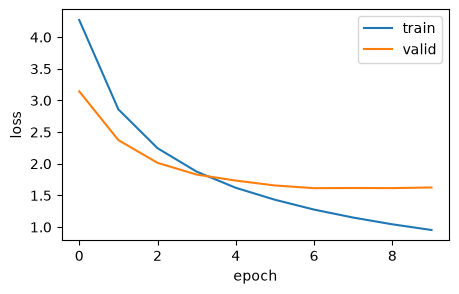

In [59]:
model.load_state_dict(torch.load("tut6-model.pt", map_location=device))

test_loss = evaluate(model, test_iterator, criterion)
print(f"| Test Loss: {test_loss:.3f} | Test PPL: {math.exp(test_loss):7.3f} |")

plt.figure(figsize=(5, 3))
plt.plot([h[0] for h in translation_history], label="train")
plt.plot([h[1] for h in translation_history], label="valid")
plt.xlabel("epoch")
plt.ylabel("loss")
plt.legend()
plt.show()

train 손실은 계속 내려가지만 검증 손실은 6~8 epoch 부근에서 멈춥니다. 과적합이 시작되는 지점이고, 위 코드가 마지막 가중치 대신 **검증 손실이 가장 낮을 때의 가중치**를 불러온 이유입니다.

## 4.8 추론

추론은 4.1절의 흐름 그대로입니다. 인코더를 한 번 돌리고, 디코더에 지금까지의 단어를 넣어 다음 단어를 가장 확률 높은 것으로 고르기를 반복합니다(greedy decoding). 입력은 문자열이나 토큰 리스트 둘 다 받습니다.

In [60]:
def translate_sentence(sentence: str | list[str], src_vocab: Vocab, trg_vocab: Vocab, model: nn.Module,
                       device: torch.device, max_len: int = 50) -> tuple[list[str], torch.Tensor]:
    model.eval()

    tokens = tokenize(sentence) if isinstance(sentence, str) else [token.lower() for token in sentence]
    src_tensor = torch.LongTensor(src_vocab.encode(tokens)).unsqueeze(0).to(device)
    src_mask = model.make_src_mask(src_tensor)

    with torch.no_grad():
        enc_src = model.encoder(src_tensor, src_mask)

    trg_indexes = [trg_vocab.stoi[Vocab.SOS]]

    for _ in range(max_len):
        trg_tensor = torch.LongTensor(trg_indexes).unsqueeze(0).to(device)
        trg_mask = model.make_trg_mask(trg_tensor)

        with torch.no_grad():
            output, attention = model.decoder(trg_tensor, enc_src, trg_mask, src_mask)

        # 마지막 위치의 예측만 다음 단어로 쓴다
        pred_token = output.argmax(2)[:, -1].item()
        trg_indexes.append(pred_token)

        if pred_token == trg_vocab.stoi[Vocab.EOS]:
            break

    trg_tokens = [trg_vocab.itos[i] for i in trg_indexes]
    return trg_tokens[1:], attention    # 맨 앞의 <sos>는 뺀다

In [61]:
def display_attention(sentence: list[str], translation: list[str], attention: torch.Tensor,
                      n_heads: int = 8, n_rows: int = 2, n_cols: int = 4) -> None:
    """디코더 마지막 층의 cross-attention을 head별로 그립니다."""
    assert n_rows * n_cols == n_heads

    fig = plt.figure(figsize=(14, 7))
    x_labels = [Vocab.SOS] + [t.lower() for t in sentence] + [Vocab.EOS]
    for i in range(n_heads):
        ax = fig.add_subplot(n_rows, n_cols, i + 1)
        ax.matshow(attention.squeeze(0)[i].cpu().numpy(), cmap="bone")
        # 눈금 위치를 먼저 정하고 글자를 달아야 칸과 글자가 어긋나지 않는다
        ax.set_xticks(range(len(x_labels)), x_labels, rotation=90, fontsize=8)
        ax.set_yticks(range(len(translation)), translation, fontsize=8)
    plt.tight_layout()
    plt.show()

src = ['eine', 'frau', 'mit', 'einer', 'großen', 'geldbörse', 'geht', 'an', 'einem', 'tor', 'vorbei', '.']
trg = ['a', 'woman', 'with', 'a', 'large', 'purse', 'is', 'walking', 'by', 'a', 'gate', '.']
predicted trg = ['a', 'woman', 'with', 'a', 'large', 'purse', 'walks', 'past', 'a', 'gate', '.', '<eos>']


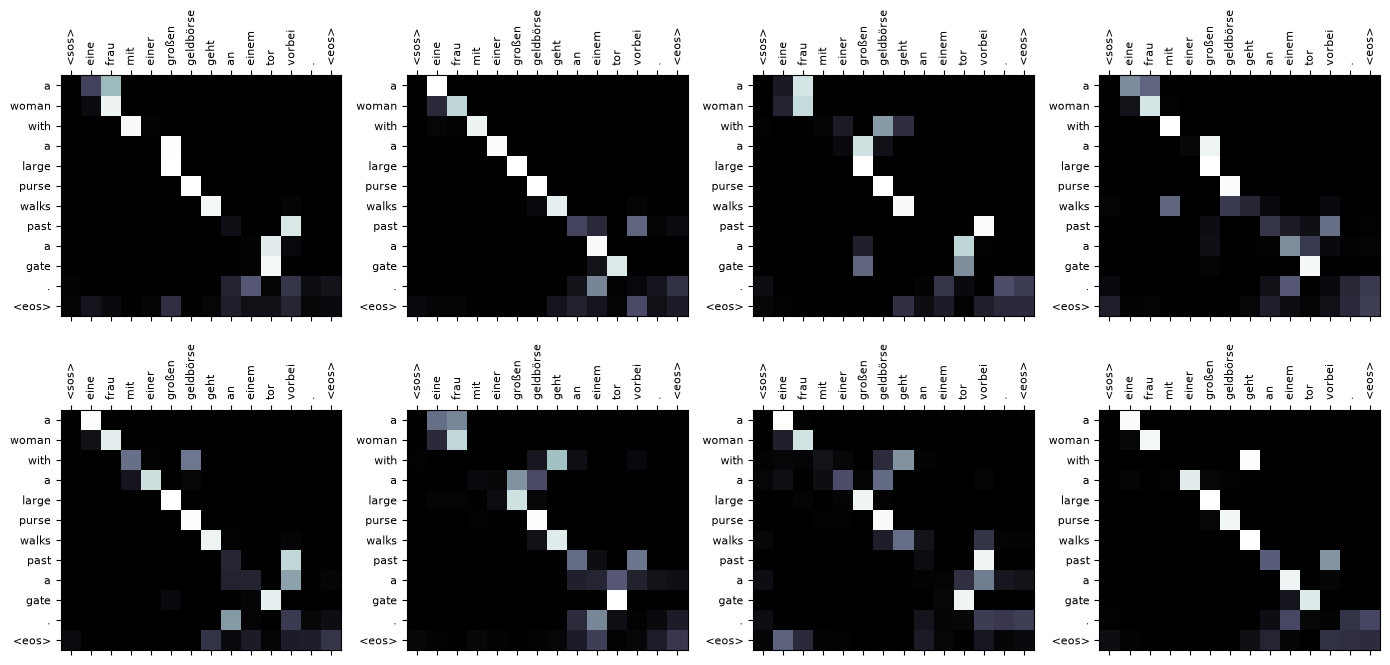

In [62]:
example_idx = 8

src = train_data[example_idx]["src"]
trg = train_data[example_idx]["trg"]
print(f"src = {src}")
print(f"trg = {trg}")

translation, attention = translate_sentence(src, SRC, TRG, model, device)
print(f"predicted trg = {translation}")

display_attention(src, translation, attention)

src = ['ein', 'brauner', 'hund', 'rennt', 'dem', 'schwarzen', 'hund', 'hinterher', '.']
trg = ['a', 'brown', 'dog', 'is', 'running', 'after', 'the', 'black', 'dog', '.']
predicted trg = ['a', 'brown', 'dog', 'is', 'running', 'after', 'the', 'black', 'dog', '.', '<eos>']


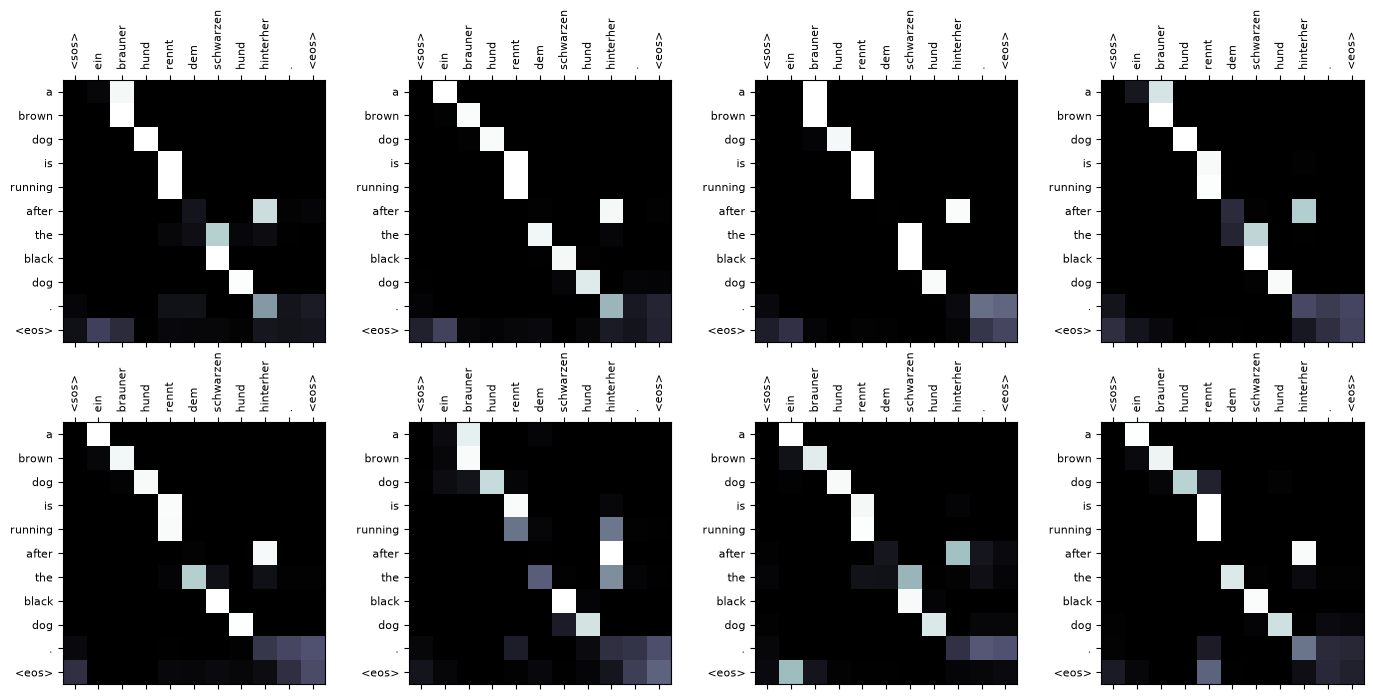

In [63]:
example_idx = 6

src = valid_data[example_idx]["src"]
trg = valid_data[example_idx]["trg"]
print(f"src = {src}")
print(f"trg = {trg}")

translation, attention = translate_sentence(src, SRC, TRG, model, device)
print(f"predicted trg = {translation}")

display_attention(src, translation, attention)

In [64]:
# 문자열을 직접 넣어 본다
for german in ["Ein Mann fährt mit dem Fahrrad auf der Straße.", "Zwei Kinder spielen im Park mit einem Hund."]:
    print(german, "→", " ".join(translate_sentence(german, SRC, TRG, model, device)[0]))

Ein Mann fährt mit dem Fahrrad auf der Straße. → a man riding a bicycle on the street . <eos>
Zwei Kinder spielen im Park mit einem Hund. → two kids playing with a dog in the park . <eos>


## 4.9 BLEU

번역은 정답이 하나가 아니라서 정확도로 재기 어렵습니다. **BLEU**는 모델 번역(candidate)이 사람 번역(reference)과 n-gram을 얼마나 공유하는지 봅니다.

$$\text{BLEU} = \text{BP} \cdot \exp\left(\sum_{n=1}^{4} \frac{1}{4}\log p_n\right), \qquad \text{BP} = \begin{cases} 1 & c > r \\ e^{1-r/c} & c \le r \end{cases}$$

- $p_n$(**modified n-gram precision**): candidate의 n-gram 중 reference에도 있는 비율입니다. 같은 n-gram은 reference에 나온 횟수까지만 인정합니다(clipping). 이것이 없으면 "the the the the"가 만점을 받습니다.
- BP(**brevity penalty**): 짧게 내서 precision만 올리는 것을 벌합니다. $c$는 candidate 전체 길이, $r$은 reference 전체 길이입니다.

수식을 직접 구현하고, `nltk`와 값이 같은지 확인합니다. 결과를 담는 변수에 `bleu_score` 같은 함수 이름을 그대로 쓰면 두 번째 호출이 실패하니 이름을 나눕니다.

In [65]:
def ngram_counts(tokens: list[str], n: int) -> Counter:
    return Counter(tuple(tokens[i:i + n]) for i in range(len(tokens) - n + 1))


def corpus_bleu_score(candidates: list[list[str]], references: list[list[list[str]]], max_n: int = 4) -> float:
    """코퍼스 전체의 BLEU를 계산합니다. references는 문장마다 정답 번역 여러 개의 리스트입니다."""
    matches, totals = [0] * max_n, [0] * max_n
    candidate_len, reference_len = 0, 0

    for candidate, refs in zip(candidates, references):
        candidate_len += len(candidate)
        # candidate와 길이가 가장 가까운 정답을 고른다. 동률이면 짧은 쪽이다
        reference_len += min((abs(len(r) - len(candidate)), len(r)) for r in refs)[1]
        for n in range(1, max_n + 1):
            cand_ngrams = ngram_counts(candidate, n)
            # 여러 정답 중 그 n-gram이 가장 많이 나온 횟수까지 인정한다
            max_ref_counts = Counter()
            for r in refs:
                max_ref_counts |= ngram_counts(r, n)
            matches[n - 1] += sum((cand_ngrams & max_ref_counts).values())
            totals[n - 1] += sum(cand_ngrams.values())

    if min(matches) == 0:   # log(0)을 피한다. 일치가 하나도 없는 차수가 있으면 BLEU는 0이다
        return 0.0
    log_precision = sum(math.log(m / t) for m, t in zip(matches, totals)) / max_n
    brevity_penalty = 1.0 if candidate_len > reference_len else math.exp(1 - reference_len / candidate_len)
    return brevity_penalty * math.exp(log_precision)


def calculate_bleu(data: list[dict[str, list[str]]], src_vocab: Vocab, trg_vocab: Vocab, model: nn.Module,
                   device: torch.device, max_len: int = 50) -> tuple[float, list[list[str]], list[list[list[str]]]]:
    trgs, pred_trgs = [], []
    for datum in data:
        pred_trg, _ = translate_sentence(datum["src"], src_vocab, trg_vocab, model, device, max_len)
        # <eos>는 번역 내용이 아니므로 뺀다
        if pred_trg[-1] == Vocab.EOS:
            pred_trg = pred_trg[:-1]
        pred_trgs.append(pred_trg)
        trgs.append([datum["trg"]])
    return corpus_bleu_score(pred_trgs, trgs), pred_trgs, trgs

In [66]:
# 손으로 계산할 수 있는 예로 검산한다
reference = "the cat is on the mat".split()
candidate = "the cat sat on the mat".split()
# 1-gram 5/6, 2-gram 3/5, 3-gram 1/4, 4-gram 0/3 이므로 4-gram까지 쓰면 0이다
assert corpus_bleu_score([candidate], [[reference]]) == 0.0
# 2-gram까지만 쓰면 sqrt(5/6 * 3/5) 이고 길이가 같아 BP는 1이다
assert math.isclose(corpus_bleu_score([candidate], [[reference]], max_n=2), math.sqrt(5 / 6 * 3 / 5))
# 짧은 번역은 BP를 받는다: 길이 2, 정답 길이 6 → 1-gram 2/2, BP = exp(1 - 6/2)
assert math.isclose(corpus_bleu_score([["the", "cat"]], [[reference]], max_n=1), math.exp(1 - 6 / 2))
print("손 계산과 일치합니다")

손 계산과 일치합니다


In [67]:
from nltk.translate.bleu_score import corpus_bleu as nltk_corpus_bleu

test_bleu, test_preds, test_refs = calculate_bleu(test_data, SRC, TRG, model, device)
print(f"BLEU score = {test_bleu * 100:.2f}")

# nltk 구현과 대조한다
nltk_bleu = nltk_corpus_bleu(test_refs, test_preds)
print(f"nltk 결과   = {nltk_bleu * 100:.2f}")
assert abs(test_bleu - nltk_bleu) < 1e-6

BLEU score = 35.58
nltk 결과   = 35.58


## 4.10 Label smoothing



딥러닝에 대한 라벨 스무딩은 Szegedy 등의 [Rethinking the Inception Architecture](https://arxiv.org/abs/1512.00567)에서 처음 소개되었습니다. **Hard label**(정답 인덱스만 1, 나머지는 0인 원핫)을 **Soft label**(0과 1 사이 값)로 부드럽게 만드는 방법입니다. $K$개 클래스에 스무딩 파라미터 $\alpha$를 쓰면 $k$번째 클래스의 라벨은 이렇습니다.

$$y_k^{LS} = y_k(1-\alpha) + \alpha/K$$

즉 정답 막대를 $\alpha$만큼 깎고, 깎은 양을 모든 클래스에 균등하게 $\alpha/K$씩 나눕니다. 예를 들어 $K=5$, 2번째 클래스가 정답, $\alpha=0.1$이면 다음과 같습니다.

$$y_2^{LS} = y_2(1-0.1) + \frac{0.1}{5} = 0.92, \qquad \text{hard} = [0, 1, 0, 0, 0] \;\to\; \text{soft} = [0.02, 0.92, 0.02, 0.02, 0.02]$$

모델이 정답에 지나치게 확신하지 않게 하는 규제(regularization) 효과가 있습니다. 논문의 Transformer도 $\alpha=0.1$을 씁니다.

아래 `LabelSmoothingDistribution`은 [gordicaleksa/pytorch-original-transformer](https://github.com/gordicaleksa/pytorch-original-transformer)(MIT, Copyright (c) 2020 Aleksa Gordić)의 코드를 고쳐 쓴 것입니다.

그림 출처: [Label smoothing 막대 그림](https://blog.kakaocdn.net/dn/uO0Hr/btqFFVzoC6h/N1cMUSyijCh6fvwBm64nh0/img.png)

In [68]:
class LabelSmoothingDistribution(nn.Module):
    """번역용 soft label을 만듭니다.

    정답 토큰의 확률을 confidence_value(보통 0.9)로 두고, 나머지 smoothing_value(보통 0.1)를
    정답과 pad를 뺀 어휘에 나눕니다. 정답이 pad인 위치는 분포 전체를 0으로 둡니다.
    """

    def __init__(self, smoothing_value: float, pad_token_id: int, trg_vocab_size: int, device: torch.device) -> None:
        assert 0.0 <= smoothing_value <= 1.0
        super().__init__()
        self.confidence_value = 1.0 - smoothing_value
        self.smoothing_value = smoothing_value
        self.pad_token_id = pad_token_id
        self.trg_vocab_size = trg_vocab_size
        self.device = device

    def forward(self, trg_token_ids_batch: torch.Tensor) -> torch.Tensor:
        # trg_token_ids_batch = [batch, 1]
        batch_size = trg_token_ids_batch.shape[0]
        smooth_target_distributions = torch.zeros((batch_size, self.trg_vocab_size), device=self.device)

        # 정답과 pad에는 나누지 않으므로 -2다. 두 칸은 다음 두 줄에서 덮어쓴다
        smooth_target_distributions.fill_(self.smoothing_value / (self.trg_vocab_size - 2))
        smooth_target_distributions.scatter_(1, trg_token_ids_batch, self.confidence_value)
        smooth_target_distributions[:, self.pad_token_id] = 0.0

        # 정답이 pad인 샘플은 손실에 들어가지 않게 전부 0으로 둔다
        smooth_target_distributions.masked_fill_(trg_token_ids_batch == self.pad_token_id, 0.0)
        return smooth_target_distributions

hard: [0.0, 1.0, 0.0, 0.0, 0.0]
soft: [0.02, 0.92, 0.02, 0.02, 0.02]
클래스 코드 결과:
 [[0.     0.9    0.0333 0.0333 0.0333]
 [0.     0.     0.     0.     0.    ]]
손 계산 0.72444 / nn.CrossEntropyLoss 0.72444


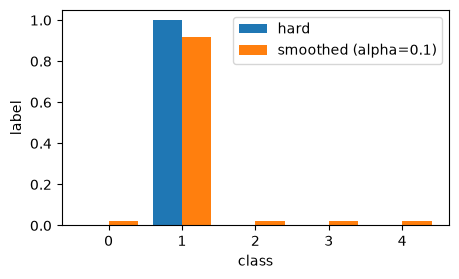

In [69]:
# 수식 예제 검산: K=5, 정답은 2번째(인덱스 1), alpha=0.1
K, alpha = 5, 0.1
hard = F.one_hot(torch.tensor(1), K).float()
soft = hard * (1 - alpha) + alpha / K
print("hard:", hard.tolist())
print("soft:", [round(value, 3) for value in soft.tolist()])
assert torch.allclose(soft, torch.tensor([0.02, 0.92, 0.02, 0.02, 0.02]))

# 코드는 수식과 나누는 방식이 조금 다르다. 위 클래스는 pad를 뺀 나머지에만 나눈다
PAD_ID = 0
smoother = LabelSmoothingDistribution(alpha, PAD_ID, K, torch.device("cpu"))
targets = torch.tensor([[1], [PAD_ID]])     # 둘째 샘플은 정답이 pad다
smooth = smoother(targets)
print("클래스 코드 결과:\n", smooth.numpy().round(4))
assert math.isclose(smooth[0].sum().item(), 1.0, abs_tol=1e-6)  # 정답이 pad가 아니면 합이 1이다
assert smooth[1].sum() == 0                                     # 정답이 pad면 손실에서 빠진다
assert math.isclose(smooth[0, 1].item(), 1 - alpha, abs_tol=1e-6)

# 내장 CrossEntropyLoss(label_smoothing=)는 위 수식을 따른다. 손으로 계산해 비교한다
logits = torch.tensor([[1.0, 2.0, 0.5, -1.0, 0.0]])
by_hand = -(soft * logits.log_softmax(dim=-1)).sum()
built_in = F.cross_entropy(logits, torch.tensor([1]), label_smoothing=alpha)
print(f"손 계산 {by_hand:.5f} / nn.CrossEntropyLoss {built_in:.5f}")
assert torch.allclose(by_hand, built_in)

plt.figure(figsize=(5, 2.8))
plt.bar(np.arange(K) - 0.2, hard.numpy(), width=0.4, label="hard")
plt.bar(np.arange(K) + 0.2, soft.numpy(), width=0.4, label=f"smoothed (alpha={alpha})")
plt.xlabel("class")
plt.ylabel("label")
plt.legend()
plt.show()

정리하면 두 가지 방식이 있습니다.

| | 정답 값 | 나머지 값 | 어디에 |
|---|---|---|---|
| 수식, `nn.CrossEntropyLoss(label_smoothing=)` | $1-\alpha+\alpha/K$ | $\alpha/K$ | 모든 클래스 |
| 위 클래스 | $1-\alpha$ | $\alpha/(K-2)$ | 정답과 pad 제외 |

실제로 쓸 때는 내장 옵션 한 줄이면 됩니다: `nn.CrossEntropyLoss(ignore_index=TRG_PAD_IDX, label_smoothing=0.1)`. 숙제에서 이것으로 번역기를 다시 학습해 봅니다.

### 실습 4. BLEU의 modified n-gram precision

BLEU 논문의 유명한 예입니다. candidate가 `the the the the the the the`(7개), reference가 `the cat is on the mat`일 때, 그냥 precision은 7/7이지만 modified precision은 **2/7**입니다. reference에 `the`가 2번뿐이기 때문입니다.

함수 `modified_precision(candidate, reference, n)`을 작성하세요. 입력은 토큰 리스트, 출력은 `(일치 수, 전체 수)` 튜플입니다. 위에서 만든 `ngram_counts`를 쓰세요.

In [70]:
# 여기에 작성하세요

<details><summary>정답</summary>

```python
def modified_precision(candidate: list[str], reference: list[str], n: int) -> tuple[int, int]:
    cand, ref = ngram_counts(candidate, n), ngram_counts(reference, n)
    # Counter의 &는 각 항목의 최솟값을 남긴다. 이것이 clipping이다
    return sum((cand & ref).values()), sum(cand.values())

assert modified_precision(["the"] * 7, "the cat is on the mat".split(), 1) == (2, 7)
assert modified_precision("the cat sat on the mat".split(), "the cat is on the mat".split(), 2) == (3, 5)
print("확인했습니다")
```

</details>

## 4.11 ViT: 이미지를 단어처럼

**ViT(Vision Transformer)** 는 이미지를 작은 패치로 잘라 **단어처럼** Transformer 인코더에 넣습니다. 전체 흐름은 패치 → 선형 사영 → `[class]` 토큰과 위치 임베딩 추가 → Transformer Encoder → MLP Head → 분류입니다.

- 논문: Alexey Dosovitskiy et al., ["An Image Is Worth 16x16 Words: Transformers for Image Recognition at Scale"](https://arxiv.org/abs/2010.11929)
- 모델은 Ross Wightman의 [timm](https://github.com/huggingface/pytorch-image-models)에서 불러옵니다. 이 절의 구성은 [hirotomusiker의 설명](https://hirotomusiker.github.io/)을 참고했습니다.

그림 출처: [ViT 전체 구조](https://blog.kakaocdn.net/dn/TCjQB/btrbgjWbSIL/0JenQ2lyh8gBbCpI9x6Cm1/img.png)

### 모델과 데이터 준비

In [71]:
import timm
from timm.data import ImageNetInfo

model_name = "vit_base_patch16_224"
vit = timm.create_model(model_name, pretrained=True).to(device).eval()
print("파라미터 수:", f"{sum(p.numel() for p in vit.parameters()):,}")

파라미터 수: 86,567,656


In [72]:
# 이 모델은 평균과 표준편차 0.5로 정규화된 224×224 입력으로 학습되었다
IMG_SIZE = (224, 224)
NORMALIZE_MEAN = (0.5, 0.5, 0.5)
NORMALIZE_STD = (0.5, 0.5, 0.5)
vit_transform = transforms.Compose([
    transforms.Resize(IMG_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(NORMALIZE_MEAN, NORMALIZE_STD),
])

imagenet_info = ImageNetInfo()  # timm에 들어 있는 ImageNet 1000개 클래스 표


def imagenet_label(index: int) -> str:
    return imagenet_info.index_to_description(index)


# 예제 사진: scikit-image의 chelsea (CC0, Stefan van der Walt). 가운데를 정사각형으로 자른다
raw_cat = PIL.Image.fromarray(skimage.data.chelsea())
img = transforms.CenterCrop(min(raw_cat.size))(raw_cat).resize(IMG_SIZE)
img_tensor = vit_transform(img).unsqueeze(0).to(device)
print("이미지 크기:", img.size, "| 텐서:", img_tensor.shape)

이미지 크기: (224, 224) | 텐서: torch.Size([1, 3, 224, 224])


0.582 Egyptian cat
0.114 tabby, tabby cat
0.093 tiger cat


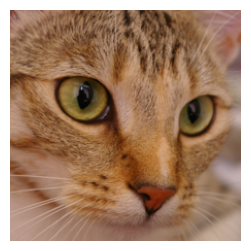

In [73]:
# 처음부터 끝까지 한 번에 추론한다
with torch.no_grad():
    output = vit(img_tensor)

top_values, top_indices = output[0].softmax(-1).topk(3)
for value, index in zip(top_values.tolist(), top_indices.tolist()):
    print(f"{value:.3f} {imagenet_label(index)}")
plt.figure(figsize=(3, 3))
plt.imshow(img)
plt.axis("off")
plt.show()

### ViT 들여다보기

한 번에 일어난 일을 네 단계로 나눠 직접 계산합니다. 끝에서 위 결과와 같은지 확인합니다.

1. 이미지를 16×16 패치로 나눠 벡터로 바꿉니다.
2. class token을 앞에 붙이고 위치 임베딩을 더합니다.
3. Transformer 인코더 블록을 차례로 지납니다. 입력과 출력의 모양이 같습니다.
4. class token 자리의 벡터로 분류합니다.

그림 출처: [ViT 추론 파이프라인](https://github.com/hirotomusiker/schwert_colab_data_storage/blob/master/images/vit_demo/vit_input.png?raw=true)

#### 1. 이미지를 패치로 나누기

ViT-Base는 224×224 이미지를 14×14 = 196개 패치로 나눕니다. "자르고 펴서 선형층에 넣기"는 **커널과 stride가 패치 크기인 합성곱 하나**로 한 번에 됩니다. 패치마다 $D=768$ 차원 벡터가 나옵니다.

```
Conv2d(3, 768, kernel_size=(16, 16), stride=(16, 16))
```

In [74]:
with torch.no_grad():
    patches = vit.patch_embed(img_tensor)
print("이미지:", img_tensor.shape, "→ 패치 임베딩:", patches.shape)
assert patches.shape == (1, 14 * 14, 768)

이미지: torch.Size([1, 3, 224, 224]) → 패치 임베딩: torch.Size([1, 196, 768])


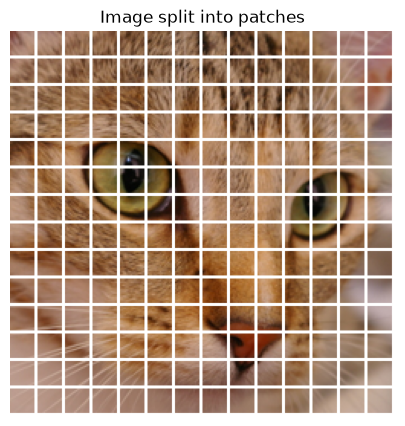

In [75]:
# 패치를 눈으로 보기 위한 그림이다. 칸 사이에 흰 틈을 두어 한 장으로 그린다
PATCH, GRID, GAP = 16, 14, 2
img_array = np.asarray(img)
step = PATCH + GAP
canvas = np.full((GRID * step, GRID * step, 3), 255, dtype=np.uint8)
for row in range(GRID):
    for col in range(GRID):
        canvas[row * step:row * step + PATCH, col * step:col * step + PATCH] = \
            img_array[row * PATCH:(row + 1) * PATCH, col * PATCH:(col + 1) * PATCH]

plt.figure(figsize=(5, 5))
plt.imshow(canvas)
plt.title("Image split into patches")
plt.axis("off")
plt.show()

#### 2. 위치 임베딩

패치의 순서는 합성곱 출력의 줄 세움일 뿐이라 모델은 그것만으로 위치를 모릅니다. 그래서 위치마다 **학습되는 벡터**를 하나씩 더합니다. 학습이 끝나면 이미지에서 가까운 위치끼리 벡터가 비슷해집니다. 위치 임베딩의 코사인 유사도로 확인합니다.

위치 임베딩: torch.Size([1, 197, 768]) (class token 1개 + 패치 196개)


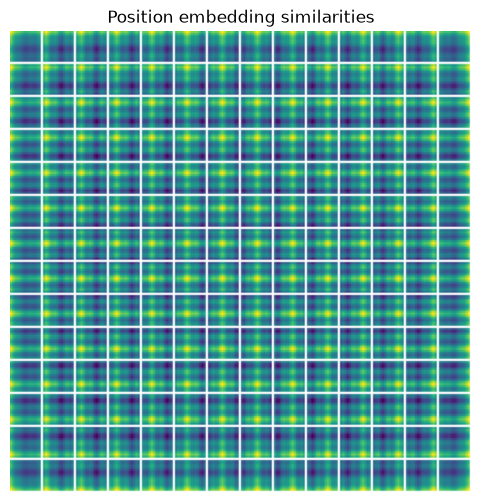

가운데 패치와의 유사도 → 바로 옆: 0.84 / 모서리: -0.481


In [76]:
print("위치 임베딩:", vit.pos_embed.shape, "(class token 1개 + 패치 196개)")

# 0번은 class token이라 빼고 패치끼리의 코사인 유사도를 구한다
patch_positions = F.normalize(vit.pos_embed[0, 1:].detach(), dim=1)
position_similarity = (patch_positions @ patch_positions.T).cpu().numpy()

# 작은 칸 하나가 한 패치의 유사도 지도다. 196장을 틈을 두고 한 장에 모은다
tile = GRID + 1
canvas = np.full((GRID * tile, GRID * tile), np.nan)
for index in range(GRID * GRID):
    row, col = index // GRID, index % GRID
    canvas[row * tile:row * tile + GRID, col * tile:col * tile + GRID] = position_similarity[index].reshape(GRID, GRID)

plt.figure(figsize=(6, 6))
plt.imshow(canvas, cmap="viridis")
plt.title("Position embedding similarities")
plt.axis("off")
plt.show()

# 거리가 멀수록 유사도가 낮은지 숫자로 본다: 가운데 패치 기준
center = 7 * GRID + 7
print("가운데 패치와의 유사도 → 바로 옆:", round(float(position_similarity[center, center + 1]), 3),
      "/ 모서리:", round(float(position_similarity[center, 0]), 3))

**인코더 입력 만들기**: 학습되는 **class token**을 맨 앞에 붙이고, 197개의 위치 임베딩을 더합니다. BERT의 `[CLS]`와 같은 발상입니다.

In [77]:
def tokens_from_patches(model: nn.Module, patch_tokens: torch.Tensor) -> torch.Tensor:
    """패치 임베딩 앞에 class token을 붙이고 위치 임베딩을 더합니다."""
    class_token = model.cls_token.expand(patch_tokens.size(0), -1, -1)
    return torch.cat([class_token, patch_tokens], dim=1) + model.pos_embed


with torch.no_grad():
    vit_tokens = tokens_from_patches(vit, patches)
print("인코더 입력:", vit_tokens.shape)

인코더 입력: torch.Size([1, 197, 768])


#### 3. Transformer 인코더

ViT 블록 하나의 계산 순서입니다.

1. Layer Norm을 먼저 합니다(**pre-norm**).
2. 선형층 `qkv` 하나로 차원을 3배로 늘려 query, key, value를 만들고, 각각을 12개 head로 나눕니다.
3. head마다 3.2절의 어텐션을 계산하고 이어 붙인 뒤 선형층 `proj`를 지나 입력에 더합니다.
4. 다시 Layer Norm 뒤에 두 층짜리 MLP를 지나 입력에 더합니다.

4부의 번역 모델은 sub-layer 뒤에 norm을 하는 post-norm(논문의 방식)이고, ViT는 앞에 norm을 합니다. 지금의 모델은 pre-norm을 많이 쓰며, 내장 `nn.TransformerEncoderLayer`도 `norm_first=True`로 고를 수 있습니다.

구현 참고: [timm의 vision_transformer.py](https://github.com/huggingface/pytorch-image-models/blob/main/timm/models/vision_transformer.py) · [Attention Is All You Need](https://papers.nips.cc/paper/2017/file/3f5ee243547dee91fbd053c1c4a845aa-Paper.pdf) · 그림 출처: [Transformer Encoder 구조](https://github.com/hirotomusiker/schwert_colab_data_storage/blob/master/images/vit_demo/transformer_encoder.png?raw=true)

In [78]:
with torch.no_grad():
    hidden_tokens = vit_tokens
    for block in vit.blocks:
        hidden_tokens = block(hidden_tokens)    # 블록마다 모양이 그대로다
    hidden_tokens = vit.norm(hidden_tokens)
class_vector = hidden_tokens[:, 0]
print(f"블록 {len(vit.blocks)}개 통과: {vit_tokens.shape} → {hidden_tokens.shape}")
print("분류에 쓸 class token 벡터:", class_vector.shape)

# 내장 인코더 층의 pre-norm 설정도 입력과 출력의 모양이 같다
builtin_layer = nn.TransformerEncoderLayer(d_model=768, nhead=12, dim_feedforward=3072,
                                           batch_first=True, norm_first=True)
print("nn.TransformerEncoderLayer:", builtin_layer(torch.zeros(1, 197, 768)).shape)

블록 12개 통과: torch.Size([1, 197, 768]) → torch.Size([1, 197, 768])
분류에 쓸 class token 벡터: torch.Size([1, 768])
nn.TransformerEncoderLayer: torch.Size([1, 197, 768])


#### 어텐션을 직접 계산하기

첫 블록의 어텐션을 위의 순서대로 계산합니다. pre-norm이므로 `norm1`을 빠뜨리면 다른 값이 나옵니다. 계산이 맞는지는 **모델 안에서 실제로 쓰인 어텐션**과 비교해 확인합니다.

In [79]:
def block_attention(block: nn.Module, tokens: torch.Tensor) -> tuple[torch.Tensor, torch.Tensor]:
    """블록의 스케일된 점수와 어텐션을 돌려줍니다. 모양은 (head, 토큰, 토큰)입니다."""
    attn = block.attn
    print(f"head {attn.num_heads}개, head 차원 {attn.head_dim}")
    # qkv의 출력은 q, k, v가 차례로 이어진 벡터다
    q_all, k_all, _ = attn.qkv(block.norm1(tokens))[0].chunk(3, dim=-1)
    print("q 전체:", q_all.shape, "→ head로 나눔:", q_all.unflatten(-1, (attn.num_heads, attn.head_dim)).shape)
    q_heads = q_all.unflatten(-1, (attn.num_heads, attn.head_dim)).transpose(0, 1)
    k_heads = k_all.unflatten(-1, (attn.num_heads, attn.head_dim)).transpose(0, 1)
    scaled_scores = q_heads @ k_heads.transpose(-2, -1) / math.sqrt(attn.head_dim)
    return scaled_scores, scaled_scores.softmax(dim=-1)


print(vit.blocks[0].attn)
with torch.no_grad():
    scaled_scores, attention_matrix = block_attention(vit.blocks[0], vit_tokens)
print("어텐션 행렬:", attention_matrix.shape)

Attention(
  (qkv): Linear(in_features=768, out_features=2304, bias=True)
  (q_norm): Identity()
  (k_norm): Identity()
  (attn_drop): Dropout(p=0.0, inplace=False)
  (norm): Identity()
  (proj): Linear(in_features=768, out_features=768, bias=True)
  (proj_drop): Dropout(p=0.0, inplace=False)
)
head 12개, head 차원 64
q 전체: torch.Size([197, 768]) → head로 나눔: torch.Size([197, 12, 64])
어텐션 행렬: torch.Size([12, 197, 197])


모델 내부 어텐션과의 최대 차이: 0.0


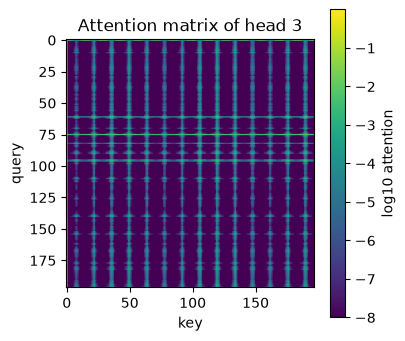

query별 가장 큰 가중치의 평균: 0.989 / 균등하면 0.005


In [80]:
# 고속 경로를 잠시 꺼야 attn_drop을 거치므로 모델 내부의 값을 잡을 수 있다
inner_attention = {}
first_attention = vit.blocks[0].attn
first_attention.fused_attn = False
hook = first_attention.attn_drop.register_forward_hook(lambda module, inp, out: inner_attention.update(value=out.detach()))
with torch.no_grad():
    vit.blocks[0](vit_tokens)
hook.remove()
first_attention.fused_attn = True
print("모델 내부 어텐션과의 최대 차이:", (inner_attention["value"][0] - attention_matrix).abs().max().item())
assert torch.allclose(inner_attention["value"][0], attention_matrix, atol=1e-4)

SHOWN_HEAD = 3
plt.figure(figsize=(4, 4))
# 가중치가 소수의 key에 몰려 그대로 그리면 거의 한 색이므로 로그로 그린다
plt.imshow(attention_matrix[SHOWN_HEAD].clamp_min(1e-8).log10().cpu().numpy())
plt.colorbar(label="log10 attention")
plt.title(f"Attention matrix of head {SHOWN_HEAD}")
plt.xlabel("key")
plt.ylabel("query")
plt.show()
print("query별 가장 큰 가중치의 평균:", round(attention_matrix[SHOWN_HEAD].max(dim=-1).values.mean().item(), 3), "/ 균등하면", round(1 / 197, 3))

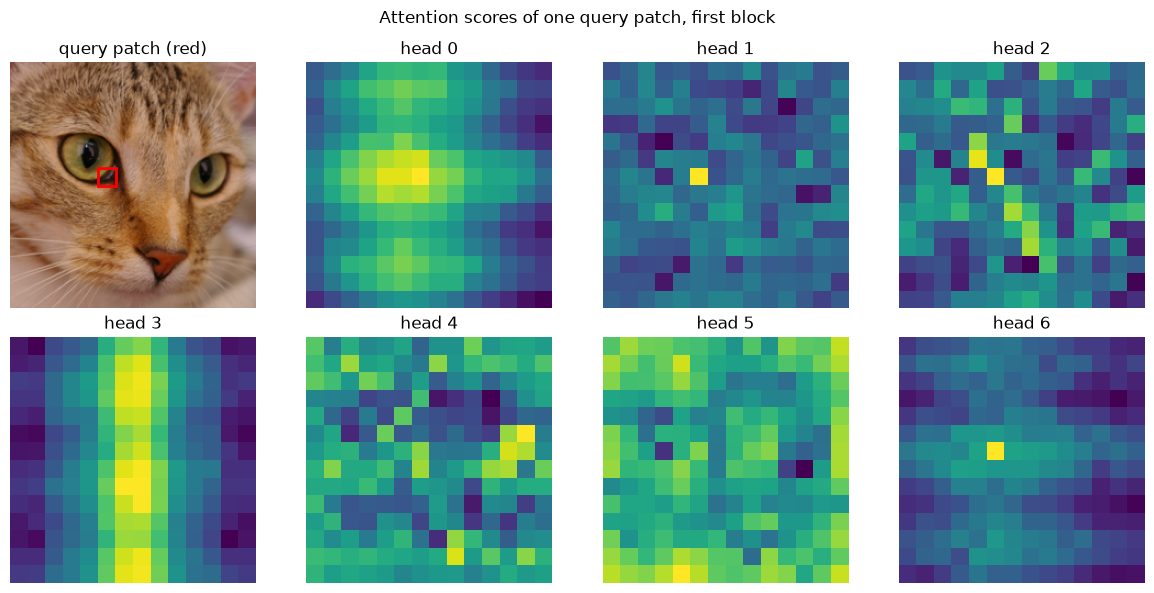

In [81]:
# 패치 하나를 query로 골라, head마다 다른 패치에 주는 점수를 지도로 그린다
QUERY_ROW, QUERY_COL = 6, 5
query_token = QUERY_ROW * GRID + QUERY_COL + 1     # 0번은 class token이다

fig = plt.figure(figsize=(12, 6))
fig.suptitle("Attention scores of one query patch, first block")
ax = fig.add_subplot(2, 4, 1)
ax.imshow(img_array)
ax.add_patch(plt.Rectangle((QUERY_COL * PATCH, QUERY_ROW * PATCH), PATCH, PATCH, fill=False, edgecolor="red", lw=2))
ax.set_title("query patch (red)")
ax.axis("off")
for head in range(7):
    # softmax 전의 점수를 그린다. head마다 무엇에 반응하는지 대비가 잘 보인다
    ax = fig.add_subplot(2, 4, head + 2)
    ax.imshow(scaled_scores[head, query_token, 1:].reshape(GRID, GRID).cpu().numpy())
    ax.set_title(f"head {head}")
    ax.axis("off")
plt.tight_layout()
plt.show()

#### 4. MLP(분류) Head

class token 자리의 벡터를 분류층에 넣으면 1000차원 로짓이 나옵니다. 하나씩 조립한 결과가 처음에 `vit(img_tensor)`로 한 번에 구한 값과 같아야 합니다.

분류층: Linear(in_features=768, out_features=1000, bias=True)


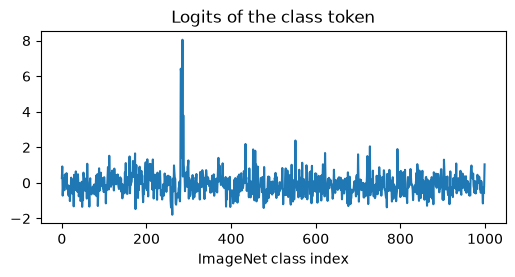

결과: id = 285, 이름 = Egyptian cat
한 번에 추론한 결과와 일치합니다


In [82]:
print("분류층:", vit.head)
with torch.no_grad():
    assembled_logits = vit.head(class_vector)
predicted_class = int(assembled_logits.argmax())
plt.figure(figsize=(6, 2.5))
plt.plot(assembled_logits.cpu().numpy()[0])
plt.title("Logits of the class token")
plt.xlabel("ImageNet class index")
plt.show()
print(f"결과: id = {predicted_class}, 이름 = {imagenet_label(predicted_class)}")

assert torch.allclose(assembled_logits, output, atol=1e-3)
print("한 번에 추론한 결과와 일치합니다")

### 실습 5. 패치 수와 패치 임베딩 파라미터

이미지 크기 `image_size`, 패치 크기 `patch_size`, 임베딩 차원 `dim`일 때 다음 함수를 작성하세요.

1. `n_tokens(image_size, patch_size)`: class token을 포함한 토큰 수
2. `patch_embed_params(patch_size, dim)`: 패치 임베딩 Conv2d(입력 채널 3, 편향 포함)의 파라미터 수

`vit_base_patch16_224`의 실제 값과 맞는지 `assert`로 확인하고, 이미지를 384로 키우면 토큰이 몇 개가 되는지 출력하세요.

In [83]:
# 여기에 작성하세요

<details><summary>정답</summary>

```python
def n_tokens(image_size: int, patch_size: int) -> int:
    return (image_size // patch_size) ** 2 + 1

def patch_embed_params(patch_size: int, dim: int) -> int:
    # 합성곱 가중치(3 × dim × 패치 × 패치) + 편향(dim)
    return 3 * dim * patch_size * patch_size + dim

assert n_tokens(224, 16) == vit.pos_embed.shape[1]
assert patch_embed_params(16, 768) == sum(p.numel() for p in vit.patch_embed.parameters())
print("384 이미지의 토큰 수:", n_tokens(384, 16))
```

</details>

---
# 5부. BERT와 GPT

## 5.1 Transformer에서 갈라진 두 갈래

1. **BERT**: [Pre-training of Deep Bidirectional Transformers for Language Understanding](https://arxiv.org/abs/1810.04805)
2. **GPT-1**: [Improving Language Understanding by Generative Pre-Training](https://cdn.openai.com/research-covers/language-unsupervised/language_understanding_paper.pdf)

둘 다 Transformer의 절반만 씁니다. 한국어 예문으로 차이를 봅니다.

| | GPT | BERT |
|---|---|---|
| 쓰는 부분 | 디코더 쪽 (masked self-attention) | 인코더 쪽 (마스크 없는 self-attention) |
| 읽는 방향 | 왼쪽 → 오른쪽 | 양방향 |
| 사전학습 과제 | **다음 단어 맞히기** | **빈칸 맞히기** |
| 예 | "어제 카페 갔었어 거기 사람 많더라"를 앞에서부터 예측 | "어제 카페 갔었어 [ ] 사람 많더라"의 빈칸을 앞뒤로 보고 예측 |

3.5절의 look-ahead mask 유무가 곧 이 차이입니다. 문장을 **만들어 내는** 일에는 GPT 쪽이, 문장을 **이해해 분류하는** 일에는 BERT 쪽이 자연스럽습니다. GPT 계열이 커진 대규모 언어 모델은 11강에서 다룹니다.

그림 출처: [GPT와 BERT 비교](https://i.imgur.com/S0equuG.png)

## 5.2 Hugging Face 소개

[Hugging Face Transformers](https://huggingface.co/docs/transformers/index): 트랜스포머 모델을 필두로 하는 딥러닝 커뮤니티입니다. 다양한 모델과 데이터셋을 쓸 수 있고, 자체 연구 도구도 제공합니다. 같은 코드로 모델 이름만 바꿔 불러올 수 있습니다. ([로고와 소개 그림](https://i.imgur.com/6DM516z.png))

이 라이브러리의 현재 버전은 PyTorch 중심입니다(`transformers` 5.x에는 `TFBertModel`이 없습니다). 그리고 `from transformers import *`처럼 전부 불러오지 말고 필요한 클래스만 이름을 적어 불러옵니다.

두 사전학습 과제를 실제 모델로 먼저 봅니다.

In [84]:
import transformers
from transformers import AutoModelForCausalLM, AutoTokenizer, BertForMaskedLM, BertModel, BertTokenizer

transformers.logging.set_verbosity_error()   # 사전학습 가중치 일부를 쓰지 않는다는 안내가 길게 나오는 것을 막는다

BERT_NAME = "bert-base-multilingual-cased"
tokenizer = BertTokenizer.from_pretrained(BERT_NAME)

# BERT: 빈칸 맞히기
mask_model = BertForMaskedLM.from_pretrained(BERT_NAME).to(device).eval()
masked_sentence = f"어제 카페 갔었어 {tokenizer.mask_token} 사람 많더라"
encoded = tokenizer(masked_sentence, return_tensors="pt").to(device)
mask_position = (encoded["input_ids"][0] == tokenizer.mask_token_id).nonzero().item()
with torch.no_grad():
    top_tokens = mask_model(**encoded).logits[0, mask_position].topk(5).indices
print(masked_sentence, "→", tokenizer.convert_ids_to_tokens(top_tokens))
del mask_model

# GPT: 다음 단어 맞히기. 작은 영어 모델로 원리만 본다
gpt_tokenizer = AutoTokenizer.from_pretrained("distilbert/distilgpt2")
gpt_model = AutoModelForCausalLM.from_pretrained("distilbert/distilgpt2").to(device).eval()
prompt = gpt_tokenizer("I went to the cafe yesterday, and", return_tensors="pt").to(device)
with torch.no_grad():
    generated = gpt_model.generate(**prompt, max_new_tokens=12, do_sample=False, pad_token_id=gpt_tokenizer.eos_token_id)
print(gpt_tokenizer.decode(generated[0]))
del gpt_model

어제 카페 갔었어 [MASK] 사람 많더라 → ['##도', '##요', '##지', '##면', '그']


I went to the cafe yesterday, and I was there. I was there. I was there.


두 결과 모두 썩 훌륭하지는 않습니다. BERT의 상위 후보에는 앞말에 붙는 `##` 조각이 많고, 작은 GPT는 같은 구절을 되풀이합니다. 이 BERT는 100개가 넘는 언어를 함께 배운 모델이라 한국어 빈칸 맞히기에 특화되어 있지 않고, GPT는 가장 작은 축에 드는 모델을 확률이 가장 높은 단어만 고르는 방식으로 돌렸기 때문입니다. 여기서 볼 것은 품질이 아니라 **과제의 형태**입니다. 5.5절에서 분류층을 붙여 이 가중치를 다시 학습합니다(전체 설정의 참고값은 5.6절).

## 5.3 네이버 영화 리뷰(NSMC) 데이터

예제는 [네이버 영화 리뷰 감성분석 데이터 NSMC](https://github.com/e9t/nsmc)(Lucy Park)입니다. 저장소 설명에 따르면 네이버 영화에서 모은 140자 미만의 리뷰 20만 개이고, 학습 15만 개와 테스트 5만 개로 나뉩니다. 라벨 규칙은 **평점 1~4는 부정(0), 9~10은 긍정(1)** 이고 5~8은 뺐습니다. 그래서 글만 보면 애매한데 라벨이 붙은 리뷰도 있습니다. 저장소는 CC0로 표시하지만, 이것은 데이터 공개자의 표시이고 리뷰 원문의 권리관계는 별개일 수 있으니 재배포하려면 직접 확인하세요.

저장소에서 필요한 파일 두 개만 받아 pandas DataFrame으로 읽습니다. 변수 이름을 `train`으로 쓰면 4부의 학습 함수 `train`을 덮어쓰므로 `nsmc_train`, `nsmc_test`로 둡니다.

In [85]:
NSMC_BASE_URL = "https://raw.githubusercontent.com/e9t/nsmc/master/"
nsmc_dir = Path("nsmc")
nsmc_dir.mkdir(exist_ok=True)
for filename in ["ratings_train.txt", "ratings_test.txt"]:
    if not (nsmc_dir / filename).exists():
        (nsmc_dir / filename).write_bytes(urllib.request.urlopen(NSMC_BASE_URL + filename, timeout=120).read())
print(os.listdir("nsmc"))

nsmc_train = pd.read_table(nsmc_dir / "ratings_train.txt")
nsmc_test = pd.read_table(nsmc_dir / "ratings_test.txt")
print("내려받은 크기:", nsmc_train.shape, nsmc_test.shape)
print("빈 리뷰:", nsmc_train["document"].isna().sum(), nsmc_test["document"].isna().sum())

# 빈 리뷰를 astype(str)로 바꾸면 'nan'이라는 글자가 되어 학습에 조용히 섞이므로 먼저 지운다
nsmc_train = nsmc_train.dropna(subset=["document"]).reset_index(drop=True)
nsmc_test = nsmc_test.dropna(subset=["document"]).reset_index(drop=True)
print("정리 후:", nsmc_train.shape, nsmc_test.shape)
print("긍정 비율:", round(nsmc_train["label"].mean(), 3), round(nsmc_test["label"].mean(), 3))

['ratings_test.txt', 'ratings_train.txt']
내려받은 크기: (150000, 3) (50000, 3)
빈 리뷰: 5 3
정리 후: (149995, 3) (49997, 3)
긍정 비율: 0.499 0.503


In [86]:
# 라벨과 리뷰 몇 줄만 본다
nsmc_train[["document", "label"]][50:60]

,document,label
50,영화가 사람의 영혼을 어루만져 줄 수도 있군요 거친 세상사를 잠시 잊고 동화같은 영...,1
51,야 세르게이! 작은고추의 매운맛을 보여주마! 포퐁저그 콩진호가 간다,0
52,이렇게 가슴시리게 본 드라마가 또 있을까? 감동 그 자체!,1
53,"난또 저 꼬마애가 무슨 원한이 깊길래.,. 했더니 OO 그냥 혼자 나대다 OO걸 어...",0
54,재미있어요,1
55,전 좋아요,1
56,최고,0
57,너무 충격적이엇다. 기분을 완전히 푹 꺼지게 하는 느낌... 활력이라고는 하나도 없...,1
58,심심한영화.,0
59,백봉기 언제나오나요?,1


## 5.4 BERT 입력 만들기

한글 데이터를 분석하는 방법으로 100개가 넘는 언어로 훈련된 **multilingual BERT**를 씁니다. 앞서 토크나이저를 불러왔습니다. Hugging Face에서는 모델과 같은 이름으로 불러옵니다. 한국어만 다룬다면 `klue/bert-base`(CC BY-SA 4.0) 같은 한국어 전용 모델도 좋은 선택입니다. 숙제에서 바꿔 봅니다.

토크나이저의 기본 사용법입니다.

- `tokenizer.encode`: 문장을 BERT 입력 토큰 번호로 바꿉니다.
- `tokenizer.tokenize`: 문장을 토큰으로 나눕니다.

In [87]:
print(tokenizer.encode("보는내내 그대로 들어맞는 예측 카리스마 없는 악역"))
print(tokenizer.tokenize("보는내내 그대로 들어맞는 예측 카리스마 없는 악역"))

[101, 9356, 11018, 31605, 31605, 110589, 71568, 118913, 11018, 9576, 119281, 9786, 79940, 23811, 40364, 9520, 23160, 102]
['보', '##는', '##내', '##내', '그대로', '들어', '##맞', '##는', '예', '##측', '카', '##리스', '##마', '없는', '악', '##역']


네이버 영화 평가의 긍부정 분석을 위해, train 15만 개를 BERT 입력으로 바꿉니다. BERT의 입력은 **토큰, 세그먼트, 마스크** 셋이고, 이 값이 모델 안에서 고차원 벡터로 임베딩됩니다.

- **토큰**: 단어를 사전의 번호로 나타냅니다.
- **세그먼트**: 앞 문장인지 뒷 문장인지 표시합니다. 여기서는 문장이 하나뿐이라 모두 0입니다.
- **마스크**: 진짜 토큰이면 1, 길이를 맞추려고 채운 패딩이면 0입니다.

문장마다 길이가 다른데 한 배치는 같은 길이여야 하므로 `SEQ_LEN`으로 맞춥니다. **짧은 문장은 패딩(0)으로 채우고, 긴 문장은 잘라냅니다.**

In [88]:
SEQ_LEN = 128   # BERT에 들어갈 입력의 길이. BERT의 한계인 512 이하에서 정하는 값이다
example_sentence = "전율을 일으키는 영화. 다시 보고싶은 영화"

print(tokenizer.tokenize(example_sentence))
print(tokenizer.encode(example_sentence))
# padding과 truncation으로 길이를 맞춘다. 길어서 앞 20개만 출력한다
padded_tokens = tokenizer.encode(example_sentence, max_length=SEQ_LEN, padding="max_length", truncation=True)
print(padded_tokens[:20], "... 길이", len(padded_tokens))

['전', '##율', '##을', '일', '##으', '##키는', '영화', '.', '다시', '보고', '##싶', '##은', '영화']
[101, 9665, 119183, 10622, 9641, 119185, 66815, 42428, 119, 25805, 98199, 119088, 10892, 42428, 102]
[101, 9665, 119183, 10622, 9641, 119185, 66815, 42428, 119, 25805, 98199, 119088, 10892, 42428, 102, 0, 0, 0, 0, 0] ... 길이 128


"전율을 일으키는 영화. 다시 보고싶은 영화"는 `'전', '##율', '##을', '일', '##으', '##키는', '영화', '.', '다시', '보고', '##싶', '##은', '영화'`로 토크나이징됩니다. `##`은 앞 토큰에 이어 붙는다는 표시입니다. 번호로 바꾸면 양 끝에 `[CLS]`(101)과 `[SEP]`(102)가 붙어 **15개**가 됩니다.

```
101, 9665, 119183, 10622, 9641, 119185, 66815, 42428, 119, 25805, 98199, 119088, 10892, 42428, 102
```

나머지 113칸은 패딩 0입니다. 아래에서 세그먼트와 마스크를 만들고, 이 설명과 맞는지 확인합니다.

In [89]:
# 세그먼트 입력: 문장이 하나라서 전부 0이다
segment_input = [0] * SEQ_LEN

# 마스크 입력: 패딩이 아닌 곳은 1, 패딩은 0
valid_num = len(tokenizer.encode(example_sentence))
mask_input = valid_num * [1] + (SEQ_LEN - valid_num) * [0]

print("토큰 앞부분  :", padded_tokens[:18])
print("세그먼트 앞부분:", segment_input[:18])
print("마스크 앞부분 :", mask_input[:18])

# 위 설명의 숫자와 비교한다
assert padded_tokens[:15] == [101, 9665, 119183, 10622, 9641, 119185, 66815, 42428, 119, 25805, 98199, 119088, 10892, 42428, 102]
assert valid_num == 15 and sum(mask_input) == 15

# 토크나이저를 그냥 호출하면 세 값을 한 번에 주고, 위에서 손으로 만든 값과 같다
all_inputs = tokenizer(example_sentence, max_length=SEQ_LEN, padding="max_length", truncation=True)
assert all_inputs["input_ids"] == padded_tokens
assert all_inputs["attention_mask"] == mask_input
assert all_inputs["token_type_ids"] == segment_input
print("토크나이저가 만든 세 입력과 일치합니다")

토큰 앞부분  : [101, 9665, 119183, 10622, 9641, 119185, 66815, 42428, 119, 25805, 98199, 119088, 10892, 42428, 102, 0, 0, 0]
세그먼트 앞부분: [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
마스크 앞부분 : [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0]
토크나이저가 만든 세 입력과 일치합니다


정리하면 BERT의 입력은 이렇습니다.

| 입력 | 내용 | 값 |
|---|---|---|
| 토큰 | `[CLS]` + 토큰 + `[SEP]` + 패딩 | `[101, 9665, ..., 42428, 102, 0, 0, ..., 0]` |
| 세그먼트 | 앞 문장 0, 뒷 문장 1. 한 문장이면 **`SEQ_LEN`만큼 전부** 0 | `[0, 0, ..., 0]` |
| 마스크 | 토큰 입력에서 패딩이 아니면 1, 패딩이면 0 | `[1]*15 + [0]*113` |

Hugging Face는 인자 순서가 [토큰, 마스크, 세그먼트]입니다.

`token.count(0)`으로 패딩 수를 세어 마스크를 만들 수도 있지만(pad 번호가 0이라 동작합니다), 토크나이저가 주는 `attention_mask`를 쓰는 편이 안전합니다. 한 문장씩 부르지 말고 **문장 리스트를 한 번에** 넘기면 훨씬 빠릅니다.

**BERT_TRAIN_SAMPLES**는 학습에 쓸 문장 수입니다. `None`이면 전체를 씁니다. 아래 출력은 빠른 확인을 위해 일부(train 8000, test 2000)로 돌린 결과입니다. 전체 결과는 직접 실행해 확인하세요.

In [90]:
BERT_TRAIN_SAMPLES = None
BERT_TEST_SAMPLES = None
DATA_COLUMN = "document"    # 긍부정 문장을 담은 칼럼
LABEL_COLUMN = "label"      # 정답(1=긍정, 0=부정)을 담은 칼럼


def take_subset(frame: pd.DataFrame, n: int | None) -> pd.DataFrame:
    return frame if n is None else frame.sample(n, random_state=1234).reset_index(drop=True)


def reviews_to_arrays(texts: list[str]) -> list[np.ndarray]:
    """리뷰 문장들을 [토큰, 마스크, 세그먼트] 배열로 바꿉니다."""
    encoded_batch = tokenizer(texts, max_length=SEQ_LEN, padding="max_length", truncation=True)
    return [np.array(encoded_batch[key]) for key in ("input_ids", "attention_mask", "token_type_ids")]


train_subset = take_subset(nsmc_train, BERT_TRAIN_SAMPLES)
test_subset = take_subset(nsmc_test, BERT_TEST_SAMPLES)

# train 데이터를 BERT 입력에 맞게 변환
train_x = reviews_to_arrays(train_subset[DATA_COLUMN].astype(str).tolist())
train_y = train_subset[LABEL_COLUMN].astype(int).to_numpy()
# 성능을 검증할 test 데이터를 BERT 입력에 맞게 변환
test_x = reviews_to_arrays(test_subset[DATA_COLUMN].astype(str).tolist())
test_y = test_subset[LABEL_COLUMN].astype(int).to_numpy()
print("train:", train_x[0].shape, "test:", test_x[0].shape)
print("패딩 전 길이 평균:", round(train_x[1].sum(axis=1).mean(), 1), "/ 잘린 문장 비율:", round((train_x[1].sum(axis=1) == SEQ_LEN).mean(), 4))

train: (8000, 128) test: (2000, 128)
패딩 전 길이 평균: 26.0 / 잘린 문장 비율: 0.0


## 5.5 BERT를 활용한 감성분석 모델

구조입니다. TPU가 있다면 더 빠르게 학습할 수 있지만, 여기서는 Colab의 GPU를 씁니다.

- BERT의 `last_hidden_state`는 `[batch, 길이, 768]`입니다. 분류에는 `pooler_output`(`[CLS]` 위치 벡터를 선형층과 tanh에 통과시킨 값, `[batch, 768]`)을 받습니다.
- 출력 1개의 선형층을 붙입니다. 가중치 초기값은 표준편차 0.02를 $\pm 2\sigma$에서 자른 절단 정규분포입니다. `nn.init.trunc_normal_`의 `a`, `b`는 절대값이라 직접 지정해야 잘립니다. 기본값($\pm 2$)으로 두면 표준편차 0.02에서는 사실상 자르지 않습니다.
- **로짓 출력 + `BCEWithLogitsLoss`** 는 sigmoid 뒤에 이진 크로스 엔트로피를 쓰는 것과 같습니다. sigmoid가 손실 안에 들어 있으므로 모델에서 또 씌우지 않습니다.

**옵티마이저**: 트랜스포머 파인튜닝에서 널리 쓰는 조합은 **AdamW + warmup**입니다. 학습 초반의 큰 갱신이 사전학습 가중치를 흔들지 않도록 전체 스텝의 5% 동안 학습률을 0부터 올리고, 여기서는 이후 고정합니다. warmup 뒤 학습률을 직선으로 줄이는 스케줄도 많이 씁니다. 초반의 불안정을 줄이도록 Adam을 고친 **RAdam(Rectified Adam)** 과 일반 Adam도 5.6절의 `BERT_OPTIMIZER`로 고를 수 있습니다.

In [91]:
INIT_STD = 0.02


class BertSentiment(nn.Module):
    def __init__(self, model_name: str) -> None:
        super().__init__()
        self.bert = BertModel.from_pretrained(model_name)   # 사전학습 BERT
        self.classifier = nn.Linear(self.bert.config.hidden_size, 1)
        nn.init.trunc_normal_(self.classifier.weight, std=INIT_STD, a=-2 * INIT_STD, b=2 * INIT_STD)
        nn.init.zeros_(self.classifier.bias)

    def forward(self, tokens: torch.Tensor, masks: torch.Tensor, segments: torch.Tensor) -> torch.Tensor:
        bert_outputs = self.bert(input_ids=tokens, attention_mask=masks, token_type_ids=segments)
        # pooler_output = [batch, 768]. 로짓을 그대로 낸다 (sigmoid는 손실 함수 안에 있다)
        return self.classifier(bert_outputs.pooler_output).squeeze(-1)


def create_sentiment_bert() -> BertSentiment:
    return BertSentiment(BERT_NAME).to(device)


set_seed()
sentiment_model = create_sentiment_bert()
n_total = sum(p.numel() for p in sentiment_model.parameters())
print(f"전체 파라미터 {n_total:,}, 이 중 분류층 {sum(p.numel() for p in sentiment_model.classifier.parameters()):,}")

# 모양 확인
with torch.no_grad():
    check_logits = sentiment_model(*[torch.tensor(a[:2], device=device) for a in train_x])
print("출력 모양:", check_logits.shape)

전체 파라미터 177,854,209, 이 중 분류층 769
출력 모양: torch.Size([2])


## 5.6 훈련과 성능 검증

전체 설정은 4 epoch, 배치 100입니다. 아래 출력은 일부 데이터로 1 epoch만 돌린 결과이므로 **성능을 판단하는 자료로 삼지 마세요.** 흐름만 확인합니다. 전체 설정 결과는 직접 실행해 확인하세요.

**전체 데이터의 참고값**: 같은 구조를 Keras와 TPU, RAdam으로 전체 데이터에 4 epoch 학습한 저자의 실행 기록에서는 epoch별 test 정확도가 0.8390, 0.8543, 0.8655, 0.8703이었고 F1은 0.87(5만 건)이었습니다. 프레임워크와 옵티마이저가 달라 같은 값이 나온다는 보장은 없습니다.

여기서는 test를 매 epoch의 검증에 함께 쓰지만, 그 결과로 모델이나 설정을 고르면 test가 검증 데이터가 되어 버립니다. 실제 프로젝트에서는 train에서 validation을 따로 떼세요.

In [92]:
BERT_EPOCHS = 4
BERT_BATCH_SIZE = 100
BERT_LR = 1.0e-5
BERT_OPTIMIZER = "adamw"    # "adam" 또는 "radam"으로 바꿔 비교할 수 있다
WEIGHT_DECAY = 0.0025
WARMUP_PROPORTION = 0.05


def make_loader(arrays: list[np.ndarray], targets: np.ndarray | None, shuffle: bool) -> DataLoader:
    tensors = [torch.tensor(a) for a in arrays]
    if targets is not None:
        tensors.append(torch.tensor(targets, dtype=torch.float))
    return DataLoader(TensorDataset(*tensors), batch_size=BERT_BATCH_SIZE, shuffle=shuffle)


def predict_probs(model: nn.Module, arrays: list[np.ndarray]) -> np.ndarray:
    """긍정일 확률을 돌려줍니다."""
    model.eval()
    probs = []
    with torch.no_grad():
        for batch in make_loader(arrays, None, shuffle=False):
            logits = model(*[t.to(device) for t in batch])
            probs.append(torch.sigmoid(logits).cpu().numpy())
    return np.concatenate(probs)


train_loader = make_loader(train_x, train_y, shuffle=True)
total_steps = len(train_loader) * BERT_EPOCHS
warmup_steps = max(1, int(total_steps * WARMUP_PROPORTION))

if BERT_OPTIMIZER == "radam":
    bert_optimizer = torch.optim.RAdam(sentiment_model.parameters(), lr=BERT_LR, weight_decay=WEIGHT_DECAY,
                                       decoupled_weight_decay=True)
elif BERT_OPTIMIZER == "adam":
    bert_optimizer = torch.optim.Adam(sentiment_model.parameters(), lr=BERT_LR)
elif BERT_OPTIMIZER == "adamw":
    bert_optimizer = torch.optim.AdamW(sentiment_model.parameters(), lr=BERT_LR, weight_decay=WEIGHT_DECAY)
else:
    raise ValueError(f"알 수 없는 옵티마이저: {BERT_OPTIMIZER}")
# warmup 동안 학습률을 0에서 BERT_LR까지 직선으로 올린 뒤 그대로 둔다
bert_scheduler = torch.optim.lr_scheduler.LambdaLR(bert_optimizer, lambda step: min(1.0, (step + 1) / warmup_steps))
bert_criterion = nn.BCEWithLogitsLoss()

for epoch in range(BERT_EPOCHS):
    sentiment_model.train()
    running_loss, n_seen = 0.0, 0
    start_time = time.time()
    for tokens, masks, segments, labels in train_loader:
        tokens, masks, segments, labels = tokens.to(device), masks.to(device), segments.to(device), labels.to(device)
        bert_optimizer.zero_grad()
        loss = bert_criterion(sentiment_model(tokens, masks, segments), labels)
        loss.backward()
        bert_optimizer.step()
        bert_scheduler.step()
        running_loss += loss.item() * labels.size(0)
        n_seen += labels.size(0)
    val_accuracy = ((predict_probs(sentiment_model, test_x) >= 0.5) == test_y).mean()
    print(f"epoch {epoch + 1} | train loss {running_loss / n_seen:.4f} | test accuracy {val_accuracy:.4f} | {time.time() - start_time:.0f}초")

epoch 1 | train loss 0.6479 | test accuracy 0.7300 | 102초


훈련한 모델을 저장합니다. 경로는 마음대로 정해도 됩니다. Colab의 파일은 런타임이 끝나면 사라지므로 오래 둘 모델은 내려받거나 구글 드라이브 같은 저장소에 옮기세요.

In [93]:
save_path = Path("naver_sentiment")
save_path.mkdir(exist_ok=True)
torch.save(sentiment_model.state_dict(), save_path / "huggingface_bert.pt")
print("저장 크기(MB):", round((save_path / "huggingface_bert.pt").stat().st_size / 1e6))

저장 크기(MB): 711


모델의 예측 성능을 F1 score로 확인합니다. test 데이터를 예측합니다. 입력은 앞에서 만든 `test_x`를 그대로 씁니다.

In [94]:
test_set = test_x   # [토큰, 마스크, 세그먼트]
print("토큰 입력:", test_set[0].shape)

preds = predict_probs(sentiment_model, test_set)
# 0.5에 가까울수록 부정(0)과 긍정(1) 사이에서 망설인다는 뜻이다
print("예측 확률 앞부분:", preds[:6].round(3))

토큰 입력: (2000, 128)


예측 확률 앞부분: [0.513 0.307 0.474 0.873 0.442 0.298]


**F1 score**는 precision과 recall의 **조화평균**입니다.

- **precision** = (진짜 TRUE를 맞힌 수) / (모델이 TRUE라고 판정한 수)
- **recall** = (진짜 TRUE를 맞힌 수) / (전체 진짜 TRUE의 수). 분자에 "모델이 TRUE라고 판정한 수"를 쓰면 틀린 판정까지 세게 되니 주의하세요.
- $F_1 = 2 \cdot \dfrac{\text{precision} \cdot \text{recall}}{\text{precision} + \text{recall}}$

In [95]:
from sklearn.metrics import classification_report

y_true = test_subset[LABEL_COLUMN].to_numpy()
y_pred = np.round(preds, 0).astype(int)
# F1 Score 확인
print(classification_report(y_true, y_pred, digits=3))

              precision    recall  f1-score   support

           0      0.753     0.665     0.706       976
           1      0.713     0.792     0.750      1024

    accuracy                          0.730      2000
   macro avg      0.733     0.728     0.728      2000
weighted avg      0.732     0.730     0.729      2000



## 5.7 실제 문장으로 실습하기

문장 하나하나를 직접 분류해 봅니다. 아래 문장은 직접 쓴 예입니다. 입력 처리와 예측 흐름은 [publicservant_AI의 NSMC 노트북](https://github.com/kimwoonggon/publicservant_AI)을 참고했습니다. 짧게 학습한 모델의 결과이므로 틀린 답이 있을 수 있습니다. 전체 설정으로 다시 돌려 비교하세요.

In [96]:
def review_sentiment(review: str) -> float:
    """리뷰 한 문장이 긍정일 확률을 돌려줍니다."""
    return predict_probs(sentiment_model, reviews_to_arrays([review])).item()


my_reviews = [
    "기대하고 봤는데 전개가 너무 느려서 중간에 끄고 싶었다",
    "이야기는 조금 아쉬웠지만 배우들 연기가 좋아서 끝까지 재미있게 봤다",
    "화면은 예쁜데 내용이 없다. 다시 보고 싶지는 않다",
]
for review in my_reviews:
    positive = review_sentiment(review)
    verdict = "긍정" if positive >= 0.5 else "부정"
    print(f"{verdict} (긍정 확률 {positive:.2f}) | {review}")

긍정 (긍정 확률 0.63) | 기대하고 봤는데 전개가 너무 느려서 중간에 끄고 싶었다
긍정 (긍정 확률 0.88) | 이야기는 조금 아쉬웠지만 배우들 연기가 좋아서 끝까지 재미있게 봤다
부정 (긍정 확률 0.41) | 화면은 예쁜데 내용이 없다. 다시 보고 싶지는 않다


### 실습 6. F1을 손으로 계산하기

`y_true`와 `y_pred`로 긍정(1) 클래스의 precision, recall, F1을 **직접** 계산하는 함수 `binary_f1(y_true, y_pred)`를 작성하세요. 결과를 `(precision, recall, f1)` 튜플로 돌려줍니다. `sklearn.metrics.f1_score` 등과 값이 같은지 확인합니다.

In [97]:
# 여기에 작성하세요

<details><summary>정답</summary>

```python
from sklearn.metrics import f1_score, precision_score, recall_score

def binary_f1(y_true: np.ndarray, y_pred: np.ndarray) -> tuple[float, float, float]:
    true_positive = ((y_pred == 1) & (y_true == 1)).sum()
    precision = true_positive / max((y_pred == 1).sum(), 1)
    recall = true_positive / max((y_true == 1).sum(), 1)
    f1 = 2 * precision * recall / max(precision + recall, 1e-12)
    return float(precision), float(recall), float(f1)

p, r, f = binary_f1(y_true, y_pred)
assert math.isclose(p, precision_score(y_true, y_pred), abs_tol=1e-9)
assert math.isclose(r, recall_score(y_true, y_pred), abs_tol=1e-9)
assert math.isclose(f, f1_score(y_true, y_pred), abs_tol=1e-9)
print(f"precision {p:.3f}, recall {r:.3f}, f1 {f:.3f}")
```

</details>

---
# 6부. CLIP과 임베딩 검색

## 6.1 CLIP이란

**CLIP**([Learning Transferable Visual Models From Natural Language Supervision](https://arxiv.org/abs/2103.00020))은 이미지 인코더와 텍스트 인코더를 함께 학습합니다. 사진과 그 설명을 짝지어 **짝끼리는 임베딩이 가깝고 나머지와는 멀게** 만듭니다(contrastive learning). 그 결과 이미지와 텍스트를 **같은 공간의 벡터**로 비교할 수 있습니다.

이 절에서는 CLIP 모델을 내려받아 실행하고, 임의의 이미지와 텍스트의 유사도를 계산하고, zero-shot 이미지 분류를 해 봅니다.

`transformers`의 CLIP으로 5부와 같은 방식으로 불러옵니다. 이 부의 유사도 실습은 [openai/CLIP의 노트북](https://github.com/openai/CLIP/blob/main/notebooks/Interacting_with_CLIP.ipynb)(MIT)을 고쳐 쓴 것입니다. 공개한 쪽의 모델 카드는 이 모델을 연구용으로 설명하며, 실제 서비스 배포는 범위 밖이라고 적습니다. 지금은 후속 모델도 많습니다. 예를 들어 `google/siglip2-base-patch16-224`(Apache-2.0)도 같은 방식의 이미지-텍스트 모델입니다. GPU 런타임이면 더 빠릅니다.

## 6.2 모델 불러오기

CLIP의 Hugging Face 이름은 `openai/clip-vit-base-patch32`, `openai/clip-vit-base-patch16`, `openai/clip-vit-large-patch14`, `openai/clip-vit-large-patch14-336` 등입니다.

In [98]:
from transformers import CLIPModel, CLIPProcessor

CLIP_NAME = "openai/clip-vit-base-patch32"   # ViT-B/32
clip_model = CLIPModel.from_pretrained(CLIP_NAME).to(device).eval()
clip_processor = CLIPProcessor.from_pretrained(CLIP_NAME)

print("Torch version:", torch.__version__)
print("Model parameters:", f"{sum(p.numel() for p in clip_model.parameters()):,}")
print("Input resolution:", clip_model.config.vision_config.image_size)
print("Context length:", clip_model.config.text_config.max_position_embeddings)
print("Vocab size:", clip_model.config.text_config.vocab_size)

Torch version: 2.15.0
Model parameters: 151,277,313
Input resolution: 224
Context length: 77
Vocab size: 49408


## 6.3 이미지 전처리

입력 이미지를 모델이 기대하는 해상도로 리사이즈하고 가운데를 잘라낸 뒤, 데이터셋의 평균과 표준편차로 픽셀을 정규화합니다. 순서는 리사이즈 → 크롭 → 정규화입니다.

이 일은 `clip_processor.image_processor`가 합니다.

In [99]:
clip_processor.image_processor

CLIPImageProcessor {
  "crop_size": {
    "height": 224,
    "width": 224
  },
  "do_center_crop": true,
  "do_convert_rgb": true,
  "do_normalize": true,
  "do_rescale": true,
  "do_resize": true,
  "image_mean": [
    0.48145466,
    0.4578275,
    0.40821073
  ],
  "image_processor_type": "CLIPImageProcessor",
  "image_std": [
    0.26862954,
    0.26130258,
    0.27577711
  ],
  "resample": 3,
  "rescale_factor": 0.00392156862745098,
  "size": {
    "shortest_edge": 224
  }
}

## 6.4 텍스트 전처리

대소문자를 구분하지 않는 토크나이저를 씁니다. 모델의 최대 길이는 **77 토큰**이고, `padding="max_length"`를 주면 그 길이로 채웁니다(인자가 없으면 채우지 않습니다). 시작 토큰(49406)과 끝 토큰(49407)이 붙고, 패딩도 끝 토큰으로 합니다. 패딩을 하든 안 하든 `attention_mask` 덕분에 텍스트 특징은 거의 같습니다.

In [100]:
hello_tokens = clip_processor.tokenizer("Hello World!", padding="max_length", max_length=77, return_tensors="pt")
print(hello_tokens["input_ids"][0][:10], hello_tokens["input_ids"].shape)
print("대소문자 구분 없음:", clip_processor.tokenizer("hello world!")["input_ids"] == clip_processor.tokenizer("HELLO WORLD!")["input_ids"])

tensor([49406,  3306,  1002,   256, 49407, 49407, 49407, 49407, 49407, 49407]) torch.Size([1, 77])
대소문자 구분 없음: True


## 6.5 입력 이미지와 텍스트 준비

예제 이미지 8장과 설명을 모델에 넣어 특징 사이의 유사도를 비교합니다. 이미지는 `scikit-image`의 예제 데이터로, CC0 또는 퍼블릭 도메인입니다(chelsea Stefan van der Walt, rocket SpaceX, horse Andreas Preuss, coffee Rachel Michetti, hubble_deep_field NASA, brick CC0Textures, eagle Dayane Machado, clock Stefan van der Walt). 설명은 무엇이든 써도 됩니다.

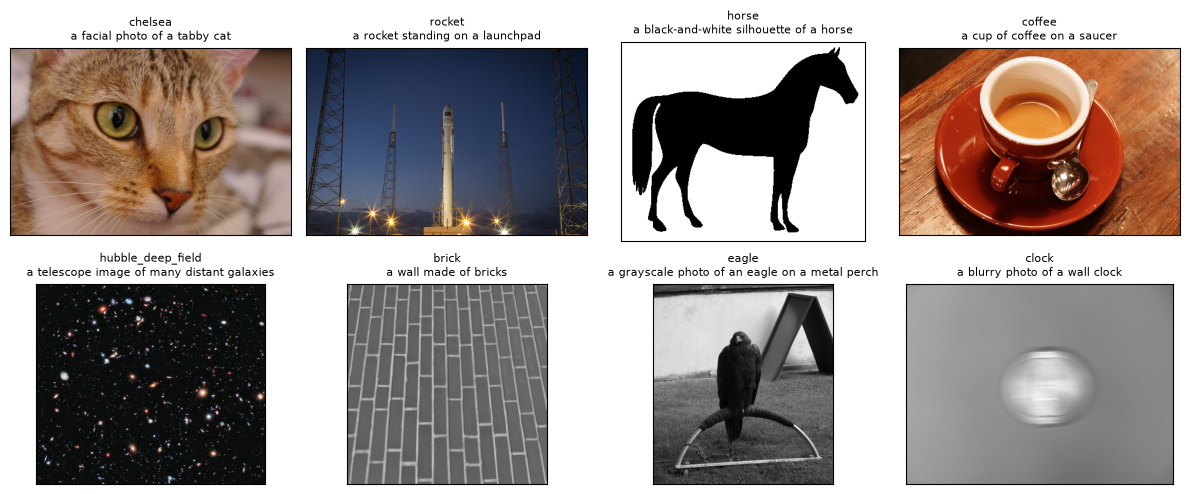

In [101]:
import skimage.data

# scikit-image 예제 이미지와 그 설명. 최신 버전은 파일을 처음 쓸 때 내려받는다
descriptions = {
    "chelsea": "a facial photo of a tabby cat",
    "rocket": "a rocket standing on a launchpad",
    "horse": "a black-and-white silhouette of a horse",
    "coffee": "a cup of coffee on a saucer",
    "hubble_deep_field": "a telescope image of many distant galaxies",
    "brick": "a wall made of bricks",
    "eagle": "a grayscale photo of an eagle on a metal perch",
    "clock": "a blurry photo of a wall clock",
}


def load_skimage(name: str) -> PIL.Image.Image:
    array = getattr(skimage.data, name)()
    if array.dtype == bool:     # horse는 불리언 배열이다
        array = (array * 255).astype(np.uint8)
    return PIL.Image.fromarray(array).convert("RGB")


original_images, texts = [], []
plt.figure(figsize=(12, 5))
for name, text in descriptions.items():
    image = load_skimage(name)
    plt.subplot(2, 4, len(original_images) + 1)
    plt.imshow(image)
    plt.title(f"{name}\n{text}", fontsize=8)
    plt.xticks([])
    plt.yticks([])
    original_images.append(image)
    texts.append(text)
plt.tight_layout()
plt.show()

## 6.6 특징 만들기

이미지를 정규화하고 텍스트를 토큰으로 바꿔 모델의 순전파로 이미지 특징과 텍스트 특징을 얻습니다.

`transformers` 버전에 따라 `get_image_features`의 반환이 텐서이거나 출력 객체이므로, 작은 함수로 감싸 두 경우를 함께 처리합니다.

In [102]:
def as_embedding(output: torch.Tensor | object) -> torch.Tensor:
    """버전에 따라 텐서 또는 출력 객체로 오는 CLIP 특징을 텐서로 맞춥니다."""
    return output if torch.is_tensor(output) else output.pooler_output


def encode_images(images: list[PIL.Image.Image], batch_size: int = 64) -> torch.Tensor:
    """이미지들을 단위 벡터로 인코딩합니다."""
    features = []
    with torch.no_grad():
        for start in range(0, len(images), batch_size):
            pixels = clip_processor(images=images[start:start + batch_size], return_tensors="pt")["pixel_values"]
            features.append(as_embedding(clip_model.get_image_features(pixel_values=pixels.to(device))))
    return F.normalize(torch.cat(features), dim=-1)


def encode_texts(sentences: list[str]) -> torch.Tensor:
    """문장들을 단위 벡터로 인코딩합니다."""
    tokens = clip_processor.tokenizer(sentences, padding=True, return_tensors="pt").to(device)
    with torch.no_grad():
        features = as_embedding(clip_model.get_text_features(**tokens))
    return F.normalize(features, dim=-1)


image_features = encode_images(original_images)
text_features = encode_texts(["This is " + desc for desc in texts])
print(image_features.shape, text_features.shape)
assert image_features.shape[-1] == clip_model.config.projection_dim

torch.Size([8, 512]) torch.Size([8, 512])


## 6.7 코사인 유사도 계산

특징을 단위 길이로 정규화하고 각 쌍의 내적을 구합니다. 단위 벡터의 내적이 곧 코사인 유사도입니다.

In [103]:
# 위 함수에서 이미 정규화했으므로 내적만 하면 된다
similarity = (text_features @ image_features.T).cpu().numpy()
print("텍스트별로 가장 비슷한 이미지가 짝과 같은가:", similarity.argmax(axis=1).tolist() == list(range(len(texts))))
print("대각선 평균:", similarity.diagonal().mean().round(3), "/ 나머지 평균:", similarity[~np.eye(len(texts), dtype=bool)].mean().round(3))

텍스트별로 가장 비슷한 이미지가 짝과 같은가: True
대각선 평균: 0.309 / 나머지 평균: 0.17


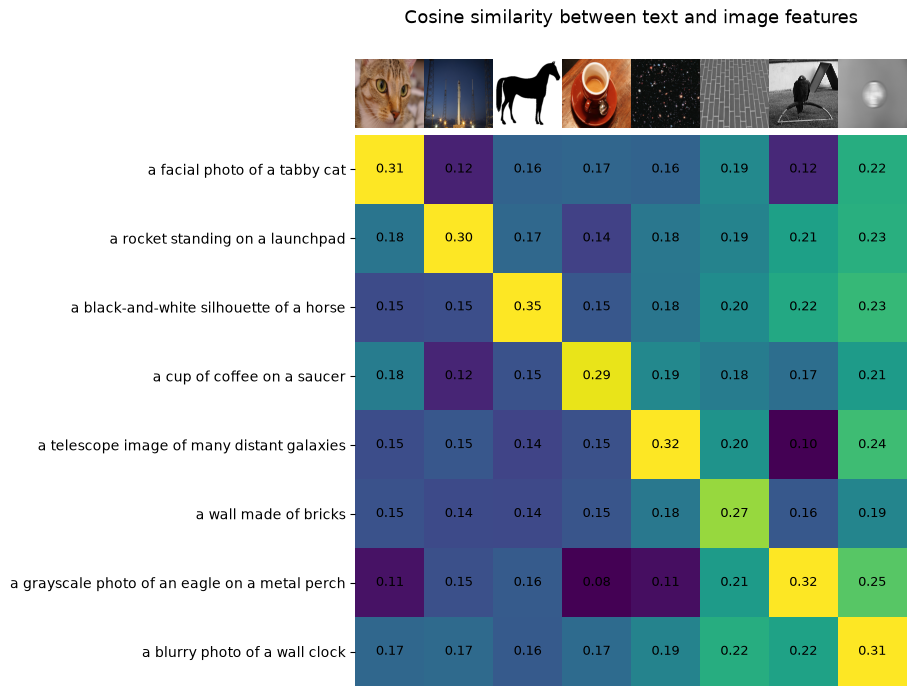

In [104]:
count = len(descriptions)

plt.figure(figsize=(12, 8.5))
plt.imshow(similarity, vmin=0.1, vmax=0.3)
plt.yticks(range(count), texts, fontsize=10)
plt.xticks([])
for i, image in enumerate(original_images):
    plt.imshow(image, extent=(i - 0.5, i + 0.5, -1.6, -0.6), origin="lower")
for x in range(similarity.shape[1]):
    for y in range(similarity.shape[0]):
        plt.text(x, y, f"{similarity[y, x]:.2f}", ha="center", va="center", size=9)
for side in ["left", "top", "right", "bottom"]:
    plt.gca().spines[side].set_visible(False)
plt.xlim([-0.5, count - 0.5])
plt.ylim([count - 0.5, -2])
plt.title("Cosine similarity between text and image features", size=13)
plt.show()

## 6.8 Zero-shot 이미지 분류

**학습 때 본 적 없는 클래스 목록**으로 분류합니다. 각 클래스를 문장으로 만들어 텍스트 임베딩을 구하고, 코사인 유사도에 100을 곱해 softmax에 넣습니다. 이 100은 임의의 값이 아니라 **CLIP이 학습한 값(`logit_scale`, 온도의 역수)** 입니다. 아래에서 값을 확인합니다.

클래스 이름은 CIFAR-100의 100개입니다. 이름 목록만 있으면 되므로 데이터는 내려받지 않고 직접 적었습니다.

In [105]:
CIFAR100_CLASSES = """apple aquarium_fish baby bear beaver bed bee beetle bicycle bottle bowl boy bridge bus butterfly
camel can castle caterpillar cattle chair chimpanzee clock cloud cockroach couch crab crocodile cup dinosaur dolphin
elephant flatfish forest fox girl hamster house kangaroo keyboard lamp lawn_mower leopard lion lizard lobster man
maple_tree motorcycle mountain mouse mushroom oak_tree orange orchid otter palm_tree pear pickup_truck pine_tree plain
plate poppy porcupine possum rabbit raccoon ray road rocket rose sea seal shark shrew skunk skyscraper snail snake
spider squirrel streetcar sunflower sweet_pepper table tank telephone television tiger tractor train trout tulip
turtle wardrobe whale willow_tree wolf woman worm""".split()
assert len(CIFAR100_CLASSES) == 100

text_descriptions = [f"This is a photo of a {label.replace('_', ' ')}" for label in CIFAR100_CLASSES]
print(text_descriptions[:2])
print("CLIP이 학습한 logit_scale:", round(clip_model.logit_scale.exp().item(), 2))

['This is a photo of a apple', 'This is a photo of a aquarium fish']
CLIP이 학습한 logit_scale: 100.0


In [106]:
class_text_features = encode_texts(text_descriptions)
text_probs = (100.0 * image_features @ class_text_features.T).softmax(dim=-1)
top_probs, top_labels = text_probs.cpu().topk(5, dim=-1)

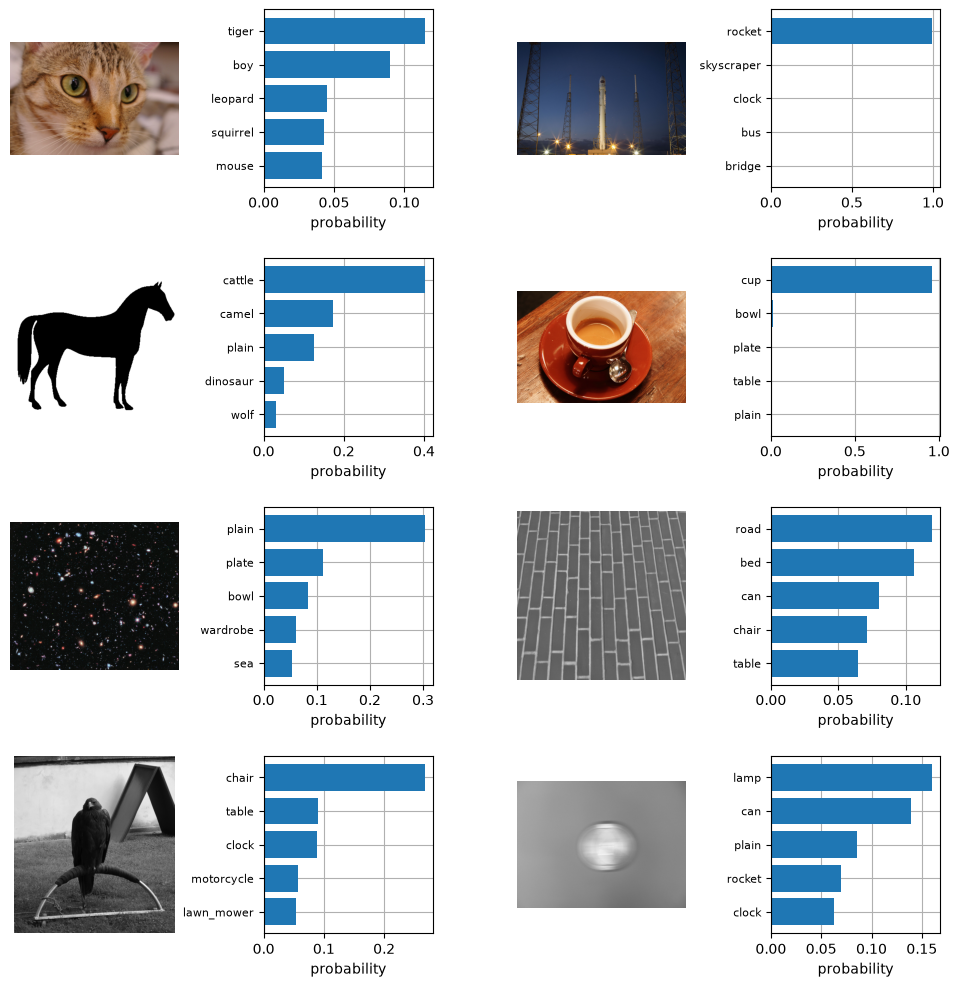

In [107]:
plt.figure(figsize=(12, 12))
for i, image in enumerate(original_images):
    plt.subplot(4, 4, 2 * i + 1)
    plt.imshow(image)
    plt.axis("off")

    plt.subplot(4, 4, 2 * i + 2)
    y = np.arange(top_probs.shape[-1])
    plt.grid()
    plt.barh(y, top_probs[i])
    plt.gca().invert_yaxis()
    plt.gca().set_axisbelow(True)
    plt.yticks(y, [CIFAR100_CLASSES[index] for index in top_labels[i].numpy()], fontsize=8)
    plt.xlabel("probability")
plt.subplots_adjust(wspace=0.5, hspace=0.4)
plt.show()

그림을 보면 zero-shot의 **한계**도 드러납니다. 목록에 답이 있고 모습이 뚜렷한 rocket과 cup은 잘 맞힙니다. clock은 목록에 있지만 5위입니다. CIFAR-100에는 cat이 없어 고양이 사진은 낮은 확률로 tiger를 답합니다. horse, eagle, galaxy, brick도 목록에 없으므로 말은 cattle로, 나머지도 낮은 확률로 엉뚱한 클래스로 답합니다. softmax는 **주어진 목록 안에서** 반드시 하나를 고릅니다. "없음"이라고 답하지 못합니다.

## 6.9 임베딩과 의미 검색

**임베딩**을 쓰면 키워드가 일치하지 않아도 **뜻이 비슷한 문서**를 찾을 수 있습니다. 문서를 벡터로 바꿔 두고, 검색어도 벡터로 바꿔 코사인 유사도가 높은 문서를 고릅니다. 이것이 **의미 검색(semantic search)** 입니다.

문서를 벡터로 바꾸는 방법은 API(OpenAI Embedding 등)와 내려받아 쓰는 모델 두 갈래입니다. 큰 규모에서는 벡터 DB(Pinecone 등)에 넣습니다. API와 벡터 DB는 키가 필요하므로 아래 선택 실습으로 두고, 본 흐름은 **무료로 내려받는 다국어 모델**(`sentence-transformers`로 불러오는 `intfloat/multilingual-e5-small`, MIT)로 진행합니다. 더 큰 모델이 필요하면 `BAAI/bge-m3`(MIT)도 널리 쓰입니다. 문서는 5부의 NSMC 리뷰입니다. 한국어뿐 아니라 영어로 검색해도 되는지 봅니다.

In [108]:
from sentence_transformers import SentenceTransformer

sentence_model = SentenceTransformer("intfloat/multilingual-e5-small", device=str(device))

DOC_COUNT = 5000
documents = nsmc_test.sample(DOC_COUNT, random_state=1234)["document"].astype(str).tolist()
start_time = time.time()
# 이 모델은 문서 앞에 "passage: ", 검색어 앞에 "query: "를 붙이도록 학습되었다
doc_embeddings = sentence_model.encode(["passage: " + doc for doc in documents], normalize_embeddings=True, batch_size=128, show_progress_bar=False)
print(f"문서 {doc_embeddings.shape[0]}개 → {doc_embeddings.shape[1]}차원 임베딩, {time.time() - start_time:.0f}초")


def semantic_search(query: str, k: int = 3) -> None:
    query_embedding = sentence_model.encode(["query: " + query], normalize_embeddings=True, show_progress_bar=False)
    scores = (doc_embeddings @ query_embedding.T).squeeze(1)    # 단위 벡터의 내적 = 코사인 유사도
    print(f"\n검색어: {query}")
    for index in np.argsort(-scores)[:k]:
        print(f"  {scores[index]:.3f} | {documents[index][:60]}")


semantic_search("배우들의 연기가 정말 훌륭했다")
semantic_search("음악이 너무 좋아서 계속 생각난다")
semantic_search("시간 낭비였어요 돈 아까움")
semantic_search("The acting was wonderful")     # 다른 언어로 검색한다

문서 5000개 → 384차원 임베딩, 3초

검색어: 배우들의 연기가 정말 훌륭했다
  0.926 | 진짜 재미있음 배우들 연기도좋고
  0.911 | 등장인물들이 연기를 정말 잘 했다. 소재가 신선했다.
  0.909 | 배우들의 연기가 너무나 자연스럽고, 코믹하고, 찐한 감동까지 있는 보기드문 수작입니다.

검색어: 음악이 너무 좋아서 계속 생각난다
  0.883 | 너무좋앗어요 노래음악이너무 좋네요 ..
  0.882 | OST 들으면 아직도 감동이와요..
  0.881 | 음악만으로도 충분히 매력적... 따뜻함과 쓸쓸함이 동시에..

검색어: 시간 낭비였어요 돈 아까움
  0.904 | 시간낭비했다. 재미 하나도 없다.
  0.902 | 돈잃고 시간잃고 딸 한테 얻어맞고---
  0.896 | ㅡㅡ;; 돈이 아까워

검색어: The acting was wonderful
  0.848 | 배우들 개성이 좋았던...
  0.845 | 진짜 재미있음 배우들 연기도좋고
  0.835 | 넘잘봤어요 멋진영화임


검색 결과에 검색어의 낱말이 그대로 없어도 뜻이 가까운 리뷰가 나오는지 살펴보세요. 음악을 묻는 검색에 "OST"가 들어간 리뷰가 나오고, 영어 검색에도 한국어 리뷰가 나옵니다. 모델 선택은 중요합니다. 다국어 모델 `paraphrase-multilingual-MiniLM-L12-v2`로 같은 검색을 해 보면 음악과 무관한 칭찬 리뷰가 유사도 0.976으로 올라옵니다. 유사도 값이 높다고 결과가 맞는 것은 아니므로 **눈으로 확인하세요.** 문서가 수백만 개가 되면 전부 내적할 수 없으므로 근사 최근접 탐색을 하는 **벡터 DB**(Pinecone, FAISS 등)를 씁니다.

### 선택 실습: OpenAI Embedding과 Pinecone

- [OpenAI 임베딩 문서](https://platform.openai.com/docs/guides/embeddings)
- [OpenAI + Pinecone 의미 검색 예제 노트북](https://colab.research.google.com/github/pinecone-io/examples/blob/master/integrations/openai/semantic_search_openai.ipynb)

아래 셀은 Colab Secrets(왼쪽 열쇠 아이콘)나 환경 변수에 `OPENAI_API_KEY`, `PINECONE_API_KEY`가 있을 때만 돕니다. 키가 없으면 건너뜁니다. API 호출에는 요금이 듭니다. 이 셀은 키 없이 검증했기 때문에 건너뛰는 경로만 확인했습니다. 라이브러리가 바뀌면 위 문서를 따르세요.

In [109]:
def read_secret(name: str) -> str | None:
    """환경 변수나 Colab Secrets에서 키를 읽습니다. 없으면 None입니다."""
    if os.environ.get(name):
        return os.environ[name]
    try:
        from google.colab import userdata
        return userdata.get(name)
    except Exception as error:     # Colab이 아니거나 비밀값이 등록되지 않은 경우
        print(f"{name} 없음: {type(error).__name__}")
        return None


openai_key = read_secret("OPENAI_API_KEY")
pinecone_key = read_secret("PINECONE_API_KEY")

if openai_key:
    %pip install -q openai
    from openai import OpenAI

    openai_client = OpenAI(api_key=openai_key)
    response = openai_client.embeddings.create(model="text-embedding-3-small", input=documents[:100])
    openai_embeddings = np.array([item.embedding for item in response.data])
    print("OpenAI 임베딩:", openai_embeddings.shape)

    if pinecone_key:
        %pip install -q pinecone
        from pinecone import Pinecone, ServerlessSpec

        pc = Pinecone(api_key=pinecone_key)
        INDEX_NAME = "nsmc-demo"
        if INDEX_NAME not in pc.list_indexes().names():
            pc.create_index(INDEX_NAME, dimension=openai_embeddings.shape[1], metric="cosine",
                            spec=ServerlessSpec(cloud="aws", region="us-east-1"))
        index = pc.Index(INDEX_NAME)
        index.upsert([(str(i), openai_embeddings[i].tolist(), {"text": documents[i]}) for i in range(100)])
        print("Pinecone에 올렸습니다. 끝나면 콘솔에서 인덱스를 지우세요")
else:
    print("API 키가 없어 선택 실습을 건너뜁니다")

OPENAI_API_KEY 없음: ModuleNotFoundError
PINECONE_API_KEY 없음: ModuleNotFoundError
API 키가 없어 선택 실습을 건너뜁니다


### 실습 7. 코사인 유사도 Top-k

`semantic_search`의 핵심을 NumPy로 직접 작성합니다. 함수 `top_k_indices(query, corpus, k)`는 **정규화되지 않은** 벡터를 받아 코사인 유사도가 높은 순서로 인덱스 k개를 돌려줍니다. `query`는 (차원,), `corpus`는 (문서 수, 차원) 모양입니다.

In [110]:
# 여기에 작성하세요

<details><summary>정답</summary>

```python
def top_k_indices(query: np.ndarray, corpus: np.ndarray, k: int) -> np.ndarray:
    query_unit = query / np.linalg.norm(query)
    corpus_unit = corpus / np.linalg.norm(corpus, axis=1, keepdims=True)
    return np.argsort(-(corpus_unit @ query_unit))[:k]

corpus = np.array([[1.0, 0.0], [10.0, 1.0], [0.0, 5.0], [-1.0, 0.0]])
# 길이가 달라도 방향이 가까운 순서로 나와야 한다
assert top_k_indices(np.array([2.0, 0.0]), corpus, 2).tolist() == [0, 1]

# 실제 임베딩으로도 확인한다: 자기 자신이 1등이어야 한다
assert top_k_indices(doc_embeddings[7], doc_embeddings, 1)[0] == 7
print("확인했습니다")
```

</details>

---
# 7부. 학습 방식과 zero/one/few-shot

## 7.1 라벨을 얼마나 갖고 있는가

학습 방식은 **라벨을 얼마나, 어떤 형태로 갖고 있는가**로 나눕니다.

| 방식 | 데이터와 라벨 | 예 |
|---|---|---|
| **supervised** | 모든 입력에 라벨이 있습니다. 취득한 데이터와 라벨을 학습합니다. | 1~5부의 MNIST, 감성분석 |
| **semi-supervised** | 일부 데이터만 라벨이 있습니다. | pseudo label, [meta pseudo labels](https://arxiv.org/abs/2003.10580) |
| **weakly-supervised** | 라벨이 있지만 예측하려는 것보다 **정보가 적습니다.** 취득한 라벨보다 더 큰 정보를 예측합니다. | 분류 라벨로 위치까지 찾기, 박스 라벨로 마스크 찾기 |
| **self-supervised** | 라벨이 없지만 입력에서 과제를 만듭니다. $X$에 변형 $z$를 가해 $X_z$를 만들고, $X_z$로부터 $X$나 $z$를 예측합니다. | 회전 맞히기, BERT의 빈칸 맞히기, CLIP의 짝 맞히기 |
| **unsupervised** | 입력만 있고 라벨이 없습니다. | 군집화, 7강의 차원 축소 |
| **reinforcement** | 라벨 대신 행동의 결과로 보상을 받습니다. | 게임, 로봇 제어 |

몇 가지를 더 풀어 씁니다.

- **weakly-supervised**: 예측에 여러 종류의 라벨(검출과 인식)이 필요한데 일부(인식용 라벨)만 있는 경우입니다. 입력과 모델은 지도 학습과 같고, **전체 라벨 정보를 주지 않는 것**만 다릅니다. 데이터 효율과 라벨링 비용에서 이점이 있어 다양하게 연구됩니다. 이미지 하나에 대한 라벨의 정보량을 나열하면 분류 < 박스 < semantic segmentation(픽셀별 클래스) < instance segmentation(픽셀별 개체)입니다. 왼쪽 라벨로 오른쪽을 예측하는 것이 약지도입니다.
- **semi-supervised**: 전체 중 일부 데이터에만 라벨이 달린 상황을 가정합니다. 지도 학습은 라벨이 달린 샘플만 학습에 활용하지만, 이 방식은 라벨 없는 샘플도 활용합니다.
- **self-training**: semi-supervised의 한 방법입니다. 라벨이 있는 $X$로 모델을 학습하고, 라벨이 없는 $X'$을 예측해 신뢰도가 높은 예측을 그 샘플의 라벨(**pseudo label**)로 삼아 다시 학습합니다.

그림 출처: [세 방식 비교](https://velog.velcdn.com/images%2Fcha-suyeon%2Fpost%2F07523763-7693-4c90-8aef-11c8e06b981c%2Fimage.png) · [supervised와 weak supervision](https://velog.velcdn.com/images%2Fcha-suyeon%2Fpost%2Fa285bb24-71b4-44dc-b539-9cb033980c61%2Fimage.png) · [semi-supervision](https://velog.velcdn.com/images%2Fcha-suyeon%2Fpost%2Fde840fe7-e39e-443a-9136-df17bfecb743%2Fimage.png) · [semantic과 instance segmentation](https://i.stack.imgur.com/MEB9F.png)

두 달 모양 데이터로 지도, 준지도, 비지도의 차이를 그립니다.

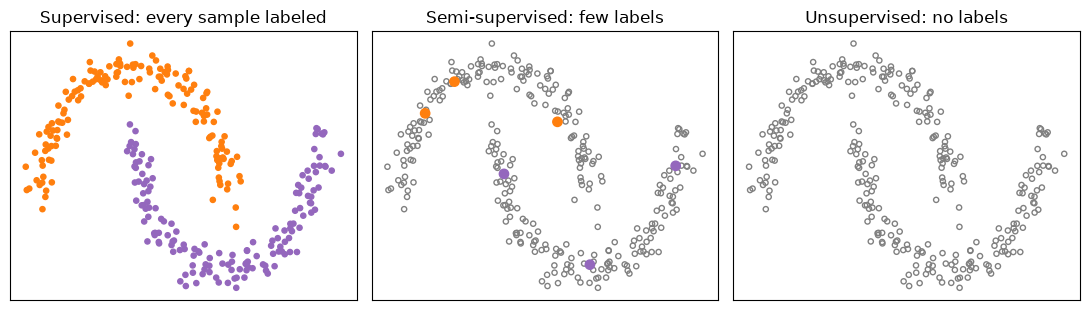

In [111]:
from sklearn.datasets import make_moons
from sklearn.neighbors import KNeighborsClassifier

MOON_SAMPLES = 300
moon_x, moon_y = make_moons(MOON_SAMPLES, noise=0.08, random_state=0)
rng = np.random.default_rng(0)
LABELED_PER_CLASS = 3
labeled_idx = np.concatenate([rng.choice(np.where(moon_y == c)[0], LABELED_PER_CLASS, replace=False) for c in [0, 1]])

fig, axes = plt.subplots(1, 3, figsize=(11, 3.2))
colors = np.array(["tab:orange", "tab:purple"])
axes[0].scatter(*moon_x.T, c=colors[moon_y], s=14)
axes[0].set_title("Supervised: every sample labeled")
axes[1].scatter(*moon_x.T, facecolors="none", edgecolors="gray", s=14)
axes[1].scatter(*moon_x[labeled_idx].T, c=colors[moon_y[labeled_idx]], s=45)
axes[1].set_title("Semi-supervised: few labels")
axes[2].scatter(*moon_x.T, facecolors="none", edgecolors="gray", s=14)
axes[2].set_title("Unsupervised: no labels")
for ax in axes:
    ax.set_xticks([])
    ax.set_yticks([])
plt.tight_layout()
plt.show()

## 7.2 Self-training을 직접 돌려 보기

위의 가운데 그림 상황입니다. 라벨은 클래스당 3개뿐입니다. 라벨만 쓴 분류기와 self-training을 비교합니다. 데이터 구조(두 달)가 라벨 없는 점들에 담겨 있으므로, pseudo label이 이 구조를 따라 퍼질 수 있는지가 관건입니다. 한 번의 운으로 판단하지 않도록 **라벨을 고르는 시드를 바꿔 20번** 평균 냅니다.

In [112]:
CONFIDENCE = 0.95       # 이 확률 이상인 예측만 pseudo label로 받는다
MAX_ROUNDS = 30
SEED_COUNT = 20


def self_training(x_labeled: np.ndarray, y_labeled: np.ndarray, x_unlabeled: np.ndarray) -> KNeighborsClassifier:
    """신뢰도가 높은 예측을 라벨로 편입하며 다시 학습합니다."""
    x_cur, y_cur, pool = x_labeled.copy(), y_labeled.copy(), x_unlabeled.copy()
    clf = KNeighborsClassifier(n_neighbors=3, weights="distance").fit(x_cur, y_cur)
    for _ in range(MAX_ROUNDS):
        if len(pool) == 0:
            break
        confidence = clf.predict_proba(pool).max(axis=1)
        # 확신이 높은 것 중 라벨 데이터와 가장 가까운 점부터 조금씩 받아 구조를 따라 번지게 한다
        distance = clf.kneighbors(pool, n_neighbors=1)[0].squeeze(1)
        take = np.argsort(distance)[:10]
        take = take[confidence[take] >= CONFIDENCE]
        if len(take) == 0:
            break
        x_cur = np.vstack([x_cur, pool[take]])
        y_cur = np.concatenate([y_cur, clf.predict(pool[take])])
        pool = np.delete(pool, take, axis=0)
        clf = KNeighborsClassifier(n_neighbors=3, weights="distance").fit(x_cur, y_cur)
    return clf


x_test_moon, y_test_moon = make_moons(1000, noise=0.08, random_state=1)
supervised_scores, self_training_scores = [], []
for seed in range(SEED_COUNT):
    rng = np.random.default_rng(seed)
    labeled = np.concatenate([rng.choice(np.where(moon_y == c)[0], LABELED_PER_CLASS, replace=False) for c in [0, 1]])
    unlabeled = np.setdiff1d(np.arange(MOON_SAMPLES), labeled)
    base = KNeighborsClassifier(n_neighbors=3, weights="distance").fit(moon_x[labeled], moon_y[labeled])
    supervised_scores.append(base.score(x_test_moon, y_test_moon))
    self_training_scores.append(self_training(moon_x[labeled], moon_y[labeled], moon_x[unlabeled]).score(x_test_moon, y_test_moon))

print(f"라벨 {2 * LABELED_PER_CLASS}개만: 평균 {np.mean(supervised_scores):.3f} (최소 {np.min(supervised_scores):.3f})")
print(f"self-training:  평균 {np.mean(self_training_scores):.3f} (최소 {np.min(self_training_scores):.3f})")
print(f"self-training이 나았던 시드 수: {sum(a > b for a, b in zip(self_training_scores, supervised_scores))}/{SEED_COUNT}, "
      f"나빴던 시드 수: {sum(a < b for a, b in zip(self_training_scores, supervised_scores))}/{SEED_COUNT}")

라벨 6개만: 평균 0.911 (최소 0.823)
self-training:  평균 0.972 (최소 0.858)
self-training이 나았던 시드 수: 17/20, 나빴던 시드 수: 3/20


이 조건에서는 평균 0.911이 0.972로 올랐습니다. 다만 20번 중 3번은 오히려 나빠졌습니다. 잘못된 pseudo label이 한번 들어가면 그 오류가 번지기 때문입니다. 두 달 구조처럼 **라벨 없는 데이터의 구조가 클래스와 맞을 때** 잘 통하는 방법이고, 공짜가 아닙니다.

## 7.3 Zero-shot, one-shot, few-shot

클래스마다 **라벨이 달린 예시를 몇 장 보여 주는가**에 따른 이름입니다.

| 이름 | 클래스당 예시 | 어떻게 맞히나 | 이 강의 예 |
|---|---|---|---|
| **zero-shot** | 0장 | 이미지 말고 다른 지식(문장, 속성)을 이용합니다. | CLIP에 "a photo of a dog"라고 글로 알려 줍니다(6.8절). |
| **one-shot** | 1장 | 예시와의 유사도로 판단합니다. | 얼굴 한 장으로 등록하는 얼굴 인식 |
| **few-shot** | 몇 장 | 예시들의 평균(**프로토타입**)과 비교합니다. | 아래 실험 |

모두 **좋은 임베딩**이 있어야 가능합니다. 처음부터 학습하지 않고 임베딩 공간에서 거리만 잽니다. 용어로, 예시 집합은 **support set**, 맞힐 대상은 **query set**입니다. "N-way K-shot"은 N개 클래스, 클래스당 K개 예시라는 뜻입니다.

CIFAR-10에서 CLIP 이미지 임베딩으로 직접 비교합니다. 10-way K-shot에서 K를 바꾸고, zero-shot은 "a photo of a {class}" 문장의 텍스트 임베딩을 프로토타입처럼 씁니다. support를 뽑는 운을 평균 내기 위해 K마다 50번 반복합니다.

support: torch.Size([1000, 512]) | query: torch.Size([2000, 512]) | 7초
zero-shot (문장만): 0.903
  1-shot: 0.612 ± 0.062
  2-shot: 0.735 ± 0.042
  5-shot: 0.838 ± 0.021
 10-shot: 0.867 ± 0.013
 20-shot: 0.883 ± 0.010
 50-shot: 0.894 ± 0.007


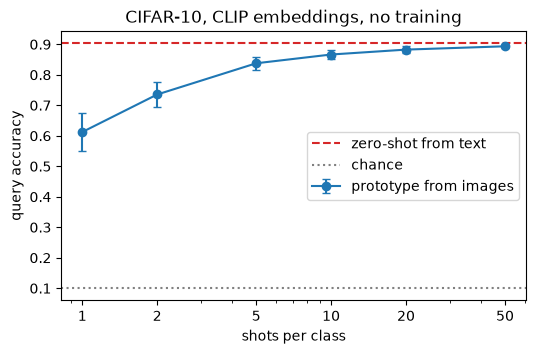

In [113]:
SUPPORT_POOL_PER_CLASS = 100    # support를 뽑을 후보 수
QUERY_PER_CLASS = 200           # 평가할 query 수
TRIALS = 50
SHOTS = [1, 2, 5, 10, 20, 50]


def pick_per_class(dataset: torchvision.datasets.CIFAR10, per_class: int) -> tuple[list[PIL.Image.Image], np.ndarray]:
    """클래스마다 앞에서 per_class장씩 고릅니다."""
    labels_array = np.array(dataset.targets)
    indices = np.concatenate([np.where(labels_array == c)[0][:per_class] for c in range(10)])
    return [dataset[int(i)][0] for i in indices], labels_array[indices]


cifar_train = torchvision.datasets.CIFAR10("./data", train=True, download=True)
cifar_test = torchvision.datasets.CIFAR10("./data", train=False, download=True)
support_images, support_labels = pick_per_class(cifar_train, SUPPORT_POOL_PER_CLASS)
query_images, query_labels = pick_per_class(cifar_test, QUERY_PER_CLASS)

start_time = time.time()
support_features = encode_images(support_images).cpu()
query_features = encode_images(query_images).cpu()
class_prompts = encode_texts([f"a photo of a {name}" for name in cifar_train.classes]).cpu()
print("support:", support_features.shape, "| query:", query_features.shape, f"| {time.time() - start_time:.0f}초")


def prototype_accuracy(prototypes: torch.Tensor) -> float:
    """query를 가장 가까운 프로토타입의 클래스로 분류한 정확도입니다."""
    predictions = (query_features @ F.normalize(prototypes, dim=-1).T).argmax(dim=1).numpy()
    return float((predictions == query_labels).mean())


zero_shot_accuracy = prototype_accuracy(class_prompts)
print(f"zero-shot (문장만): {zero_shot_accuracy:.3f}")

rng = np.random.default_rng(1234)
few_shot_mean, few_shot_std = [], []
for shot in SHOTS:
    scores = []
    for _ in range(TRIALS):
        chosen = np.concatenate([rng.choice(np.where(support_labels == c)[0], shot, replace=False) for c in range(10)])
        chosen = chosen.reshape(10, shot)
        scores.append(prototype_accuracy(support_features[chosen].mean(dim=1)))
    few_shot_mean.append(np.mean(scores))
    few_shot_std.append(np.std(scores))
    print(f"{shot:3d}-shot: {few_shot_mean[-1]:.3f} ± {few_shot_std[-1]:.3f}")

plt.figure(figsize=(6, 3.5))
plt.errorbar(SHOTS, few_shot_mean, yerr=few_shot_std, marker="o", capsize=3, label="prototype from images")
plt.axhline(zero_shot_accuracy, color="tab:red", ls="--", label="zero-shot from text")
plt.axhline(0.1, color="gray", ls=":", label="chance")
plt.xscale("log")
plt.xticks(SHOTS, SHOTS)
plt.xlabel("shots per class")
plt.ylabel("query accuracy")
plt.title("CIFAR-10, CLIP embeddings, no training")
plt.legend()
plt.show()

해석입니다.

- 클래스당 1장으로도 찍기(0.1)의 6배인 약 0.61입니다. 학습은 전혀 하지 않았고 임베딩의 거리만 쟀습니다.
- 예시가 늘수록 올라가고 표준편차는 줄어듭니다. 예시가 적을수록 **어떤 예시를 뽑느냐에 크게 좌우**됩니다.
- 이 실험에서는 **문장 하나로 만든 zero-shot(약 0.90)이 이미지 50장의 프로토타입(약 0.89)과 비슷하거나 약간 높았습니다.** query 2000장의 표준오차가 0.007쯤이라 차이는 이 수준입니다. CIFAR-10처럼 클래스 이름이 명확한 경우입니다. 이름으로 설명하기 어려운 클래스(예: 공장의 불량 유형)에서는 이렇게 되리라고 기대하면 안 됩니다. 그때는 그 데이터로 직접 재 봐야 합니다.

### 실습 8. 프로토타입 분류기

위 실험의 핵심을 직접 작성합니다. 함수 `few_shot_predict(support, support_labels, query, n_classes)`는 다음을 합니다.

1. 클래스별로 support 벡터를 평균 내 프로토타입을 만들고 단위 길이로 정규화합니다.
2. query와 프로토타입의 코사인 유사도가 가장 큰 클래스를 예측으로 돌려줍니다.

`support_features`에서 클래스당 5장으로 정확도를 재서, 찍었을 때(0.1)보다 충분히 높은지 `assert`로 확인하세요.

In [114]:
# 여기에 작성하세요

<details><summary>정답</summary>

```python
def few_shot_predict(support: torch.Tensor, support_labels: np.ndarray, query: torch.Tensor, n_classes: int) -> np.ndarray:
    labels_tensor = torch.as_tensor(support_labels)
    prototypes = torch.stack([support[labels_tensor == c].mean(dim=0) for c in range(n_classes)])
    prototypes = F.normalize(prototypes, dim=-1)
    return (F.normalize(query, dim=-1) @ prototypes.T).argmax(dim=1).numpy()

keep = np.concatenate([np.where(support_labels == c)[0][:5] for c in range(10)])
few_shot_pred = few_shot_predict(support_features[keep], support_labels[keep], query_features, 10)
few_shot_acc = (few_shot_pred == query_labels).mean()
print(f"5-shot 정확도: {few_shot_acc:.3f}")
assert few_shot_acc > 0.3
```

</details>

---
# 이 강의 요약

- **원핫**은 범주 사이 거리를 없애지만 차원이 크고 비슷함을 표현하지 못합니다. **임베딩**은 원핫 × 가중치 행렬이고 학습됩니다.
- **RNN**은 은닉 상태로 과거를 기억합니다. BPTT에서 곱이 이어져 기울기가 **소실하거나 폭주**합니다. 폭주는 클리핑으로 막습니다.
- **LSTM**은 셀 상태와 게이트 셋, **GRU**는 게이트 둘로 정보의 통로를 만듭니다. 내장 모듈과 가중치를 맞추면 직접 구현과 값이 같습니다. 게이트는 통로를 열 수 있게 해 줄 뿐이고, **초기값이 결과를 크게 좌우**합니다.
- **어텐션**은 $\text{softmax}(QK^T/\sqrt{d_k})V$이고, 지금은 `F.scaled_dot_product_attention`으로 씁니다. Multi-Head는 여러 표현 공간을 함께 봅니다. 마스크는 곱하는 것이 아니라 덮어씁니다.
- **Transformer**는 순환 없이 어텐션, FFN, 위치 정보로 시퀀스를 처리합니다. 디코더 입력을 한 칸 밀어 학습합니다. 번역은 **BLEU**로 평가합니다.
- **ViT**는 패치를 단어처럼, **BERT**는 빈칸 맞히기로, **GPT**는 다음 단어 맞히기로 사전학습합니다.
- **CLIP**은 이미지와 글을 같은 공간에 놓아 **zero-shot** 분류를 가능하게 합니다. 문장 임베딩은 **의미 검색**의 기반입니다.
- 학습 방식은 **라벨의 양과 형태**로 나눕니다. 좋은 임베딩이 있으면 몇 장의 예시로도 분류할 수 있습니다.

# 숙제

1. **Label smoothing 실험**: `nn.CrossEntropyLoss(ignore_index=TRG_PAD_IDX, label_smoothing=0.1)`로 번역기를 다시 학습하고 loss, PPL, BLEU를 원래 모델과 비교하세요. PPL은 왜 비교하기 어려운지, BLEU로 무엇을 봐야 하는지 적습니다.
2. **sinusoid 위치 인코딩**: `Encoder`와 `Decoder`의 학습하는 위치 임베딩을 3.8절의 `positional_encoding`으로 바꿔 BLEU를 비교하세요.
3. **BERT 전체 학습**: `BERT_TRAIN_SAMPLES = None`, 원래 설정으로 학습해 F1을 재세요. 일부 데이터 결과와 얼마나 다른가요?
4. **문장 틀 실험**: `"a photo of a {class}"` 문장 틀을 바꾸면 7.3절의 zero-shot 정확도가 얼마나 달라지는지 재 보세요. 틀을 고를 때 test 정확도를 쓰면 왜 문제일까요?
5. **한국어 전용 모델**: `BERT_NAME`을 `klue/bert-base`로 바꿔 같은 설정으로 학습해 보세요. `tokenizer.tokenize` 결과가 어떻게 달라지나요? 5.4절의 토큰 번호와 길이 15를 확인하는 `assert` 두 줄(`padded_tokens[:15]`, `valid_num == 15`)은 multilingual 모델의 값이므로 지우고 실행하세요. 그 절의 본문에 적힌 번호와 15칸도 이 모델 기준입니다.
6. **치트시트 추가**: RNN, LSTM, GRU, Multi-Head Attention의 입출력 모양과 `batch_first`의 차이를 표로 정리하세요.

# 더 읽을거리

- [Seq2Seq 논문 리뷰 노트북](https://github.com/Seonghoon-Yu/AI_Paper_Review/blob/master/NLP/Seq2Seq%282014%29.ipynb)
- [The Illustrated Transformer 한국어 번역](https://nlpinkorean.github.io/illustrated-transformer/)
- [The Annotated Transformer](https://nlp.seas.harvard.edu/annotated-transformer/)
- [Hugging Face NLP Course](https://huggingface.co/learn/nlp-course)

---
# 부록. EfficientDet 짧은 복습

객체 탐지의 **특징 피라미드**를 복습합니다. 이번 주제와 달라 부록으로 둡니다.

- 논문: [EfficientDet](https://arxiv.org/abs/1911.09070) · 설명 글: [ysbstudy 블로그](https://ysbstudy.tistory.com/78)

**FPN**은 해상도가 다른 특징 $P_3 \sim P_7$을 위에서 아래로 합칩니다.

$$P_7^{out} = Conv(P_7^{in}), \quad P_6^{out} = Conv\big(P_6^{in} + Resize(P_7^{out})\big), \quad \dots, \quad P_3^{out} = Conv\big(P_3^{in} + Resize(P_4^{out})\big)$$

**PANet**은 여기에 아래에서 위로 가는 경로를 하나 더 둡니다. **BiFPN**은 이 양방향 흐름을 반복 블록으로 쌓고, 같은 층의 입력을 출력으로 건너뛰는 연결을 더하고, 입력이 하나뿐인 노드를 뺀 구조입니다. 또 해상도가 다른 특징을 단순히 더하지 않고 **학습되는 가중치로 합칩니다**(weighted feature fusion).

그림 출처: [FPN](https://img1.daumcdn.net/thumb/R1280x0/?scode=mtistory2&fname=https%3A%2F%2Fblog.kakaocdn.net%2Fdn%2FbdIUbt%2Fbtq4OhQoawP%2F8XXJ2j66PUzFo12xbBkU41%2Fimg.png) · [FPN 식](https://img1.daumcdn.net/thumb/R1280x0/?scode=mtistory2&fname=https%3A%2F%2Fblog.kakaocdn.net%2Fdn%2FFZaSI%2Fbtq4INcpPck%2FtAJXFFQL5SR4YHYXpqODQ0%2Fimg.png) · [PANet과 BiFPN](https://img1.daumcdn.net/thumb/R1280x0/?scode=mtistory2&fname=https%3A%2F%2Fblog.kakaocdn.net%2Fdn%2Fc2AnUU%2Fbtq4MBPBQk8%2FgcXv4IR1KBmNMJKQD6qqyK%2Fimg.png)